# 17 · SQL Essentials: Grain, Joins, Aggregation & Safe Data Cleaning
*AI Foundations · Notebook 17 of 19*

Every machine-learning project starts long before the model. Someone has to pull the right rows out of a database, join tables together, compute features and labels, and clean up the mess that real systems produce. The language for that work is **SQL**, and its most dangerous bugs never crash. They return a neat, plausible table with the wrong numbers in it: revenue silently doubled by a join, a month that quietly loses its last day, a "deduplication" step that deletes the only valid copy of a record. None of these raises an error, and all of them end up in dashboards and training sets.

In this notebook you will learn SQL from the ground up with two real database engines running inside Python, **SQLite** and **DuckDB**. Above all you will learn the habit that prevents most silent bugs: always knowing the **grain** of every table and every intermediate result, that is, what exactly one row means.

**What you will learn**
- Relational basics: tables, primary and foreign keys, the **grain** of a table, and 1:1 / 1:N / N:M relationships, plus how to *test* each of these claims with a query.
- Single-table queries: `SELECT`, `WHERE`, `ORDER BY`, `LIMIT`, three-valued logic with `NULL`, and the **logical order of evaluation** (which explains why `WHERE COUNT(*) > 5` is an error).
- Aggregation: `COUNT(*)` vs `COUNT(col)` vs `COUNT(DISTINCT col)`, how `SUM`/`AVG`/`MIN`/`MAX` treat `NULL`, `GROUP BY`, `HAVING` and conditional aggregation.
- Joins: `INNER`, `LEFT`, `RIGHT`, `FULL`, conditions in `ON` vs `WHERE`, semi-joins, anti-joins and the `NOT IN` trap.
- **The fan-out trap**: why joining a one-row-per-order table to a many-rows-per-order table inflates sums, an exact formula for how it biases averages, how to diagnose it, the correct fix (pre-aggregate to the right grain in a CTE) and several tempting wrong fixes.
- Dates and time windows: half-open intervals, the `BETWEEN` trap and engine-dependent timestamp comparisons.
- CTEs, subqueries and window functions: `ROW_NUMBER`, `RANK`, `DENSE_RANK`, running totals, `LAG`/`LEAD` and deterministic tie-breaking.
- **Safe data cleaning**: normalization, business-rule filters, why row filters commute but deduplication does not, nondeterministic `GROUP BY` in SQLite and MySQL vs hard errors in DuckDB and PostgreSQL, deterministic deduplication with `ROW_NUMBER`, and the pandas equivalents.
- Data-quality testing: uniqueness, referential-integrity and reconciliation checks that catch these bugs automatically.

**Prerequisites:** Python basics and a little pandas (DataFrames, boolean masks, `groupby`). No prior SQL is needed.      **Estimated time:** ~6 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers. In every exercise you complete a small Python function that **returns a SQL query as a string**. The checker runs your query and compares its result table with the correct one, often with a hint about what went wrong.

**Contents**
1. Tables, keys and grain
2. Querying one table: `SELECT`, `WHERE`, `ORDER BY`, `LIMIT` and `NULL`
3. Aggregation: `COUNT`, `SUM`, `AVG`, `GROUP BY`, `HAVING`
4. Joins
5. The fan-out trap
6. Dates and time windows
7. CTEs, subqueries and window functions
8. Safe data cleaning
9. Data-quality tests
10. Exam-style questions
11. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style, versions and a tiny test harness.
import importlib
import math
import random
import sqlite3
import subprocess
import sys
from datetime import date, datetime, timedelta
from decimal import Decimal
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


duckdb = ensure("duckdb")   # an analytical SQL engine that runs inside Python
pa = ensure("pyarrow")      # used only to hand our generated tables to DuckDB efficiently

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# Every table in this notebook is generated in code, so nothing is downloaded.
# DATA_DIR is defined only for consistency with the rest of the series.
DATA_DIR = Path("data")

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

print(f"Python {sys.version.split()[0]} | SQLite library {sqlite3.sqlite_version} | "
      f"DuckDB {duckdb.__version__} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | SQLite library 3.45.1 | DuckDB 1.5.6 | pandas 2.3.3 | numpy 2.5.3 | matplotlib 3.11.2


### Our SQL toolkit

We talk to the databases from Python. Two **connections** stay open for the whole notebook: `db` (SQLite, the default) and `duck` (DuckDB). A handful of small helpers keep the cells short. You do not need to study their code, only what they do:

| helper | what it does |
|---|---|
| `q(sql, con=db)` | runs one query and returns the result as a pandas DataFrame |
| `attempt(sql, con=db)` | runs a query the engine may *reject* and prints the error instead of crashing |
| `show(df, max_rows=12)` | displays a DataFrame, truncated, and says how many rows were hidden |
| `both(sql)` | runs the same query in SQLite **and** DuckDB and reports whether the two answers agree |
| `load_table(name, schema, rows)` | creates a table in both engines and inserts rows |
| `check_sql(sql, expected, ...)` | used by the exercises: compares your query's result with the expected table |

In [2]:
# Two SQL engines, both running inside this Python process (no database server needed).
db = sqlite3.connect(":memory:")   # SQLite: ships with Python, our default engine
duck = duckdb.connect()            # DuckDB: a columnar engine built for analytics


def engine_name(con) -> str:
    """'SQLite' or 'DuckDB' (used in printed messages)."""
    return "SQLite" if isinstance(con, sqlite3.Connection) else "DuckDB"


def to_frame(rows: list[tuple], columns: list[str]) -> pd.DataFrame:
    """Rows -> DataFrame. Integer columns containing NULL become pandas' nullable Int64 (shown as <NA>)
    instead of being silently turned into floats (shown as 903.0 and NaN)."""
    df = pd.DataFrame(rows, columns=columns)
    for j in range(len(columns)):
        values = [r[j] for r in rows]
        present = [v for v in values if v is not None]
        if (present and len(present) < len(values)
                and all(isinstance(v, int) and not isinstance(v, bool) for v in present)):
            df.isetitem(j, pd.array(values, dtype="Int64"))
    return df


def q(sql: str, con=None, params=()) -> pd.DataFrame:
    """Run one SQL query and return its result as a pandas DataFrame (default engine: SQLite)."""
    con = db if con is None else con
    cur = con.execute(sql, params)
    columns = [d[0] for d in cur.description] if cur.description else []
    return to_frame(cur.fetchall(), columns)


def attempt(sql: str, con=None) -> pd.DataFrame | None:
    """Run a query that the engine may reject, and print its error message instead of crashing."""
    con = db if con is None else con
    try:
        return q(sql, con)
    except Exception as err:
        first_line = str(err).strip().splitlines()[0]
        print(f"{engine_name(con)} refused it -> {type(err).__name__}: {first_line}")
        return None


def show(df: pd.DataFrame, max_rows: int = 12) -> None:
    """Display at most max_rows rows of a DataFrame and report how many were hidden."""
    display(df.head(max_rows))
    if len(df) > max_rows:
        print(f"... {len(df) - max_rows} more rows (total {len(df)})")

In [3]:
# Comparing result tables: used by both(), by the exercise checkers and by our reconciliation tests.
def _norm(v):
    """Normalize one cell so that answers from different engines and libraries compare fairly."""
    if v is None or v is pd.NA or v is pd.NaT or (isinstance(v, float) and math.isnan(v)):
        return None
    if isinstance(v, (bool, np.bool_)):
        return float(v)
    if isinstance(v, (int, float, Decimal, np.integer, np.floating)):
        return float(v)
    if isinstance(v, datetime):                       # also covers pandas Timestamps
        millis = f".{v.microsecond // 1000:03d}" if v.microsecond else ""
        return v.strftime("%Y-%m-%d %H:%M:%S") + millis
    if isinstance(v, date):
        return v.isoformat()
    return v


def _rows(df: pd.DataFrame) -> list[tuple]:
    return [tuple(_norm(v) for v in row) for row in df.astype(object).itertuples(index=False, name=None)]


def _sort_key(row: tuple) -> tuple:
    return tuple((0, "") if v is None else (1, round(v, 6)) if isinstance(v, float) else (2, str(v))
                 for v in row)


def frame_diff(got: pd.DataFrame, expected: pd.DataFrame, ordered: bool = False,
               atol: float = 0.01) -> str | None:
    """None if the two result tables match (numbers within atol), else a description of the first difference."""
    g_cols = [str(c).lower() for c in got.columns]
    e_cols = [str(c).lower() for c in expected.columns]
    if g_cols != e_cols:
        return f"expected columns {e_cols}, got {g_cols}"
    if len(got) != len(expected):
        return f"expected {len(expected)} rows, got {len(got)}"
    g_rows, e_rows = _rows(got), _rows(expected)
    if not ordered:
        g_rows, e_rows = sorted(g_rows, key=_sort_key), sorted(e_rows, key=_sort_key)
    for i, (g_row, e_row) in enumerate(zip(g_rows, e_rows)):
        for col, gv, ev in zip(e_cols, g_row, e_row):
            close = (isinstance(gv, float) and isinstance(ev, float)
                     and math.isclose(gv, ev, rel_tol=1e-9, abs_tol=atol))
            if gv != ev and not close:
                where = f"row {i}" if ordered else f"row {i} (after sorting)"
                return f"{where}, column '{col}': expected {ev!r}, got {gv!r}\n   expected row {e_row}\n   your row     {g_row}"
    return None


def check_sql(sql: str, expected: pd.DataFrame, *, ordered: bool = False, atol: float = 0.01,
              con=None, diagnose=None) -> None:
    """Assert that the query `sql` returns exactly the table `expected` (used by the exercises)."""
    if not isinstance(sql, str) or not sql.strip():
        raise AssertionError("your function must return the SQL query as a non-empty string")
    try:
        got = q(sql, con)
    except Exception as err:
        first_line = str(err).strip().splitlines()[0]
        raise AssertionError(f"the query did not run -> {type(err).__name__}: {first_line}") from None
    problem = frame_diff(got, expected, ordered=ordered, atol=atol)
    if problem:
        hint = diagnose(got) if diagnose is not None else None
        raise AssertionError(problem + (f"\n   Hint: {hint}" if hint else ""))


def both(sql: str, ordered: bool = True, atol: float = 1e-6):
    """Run the same query in SQLite and DuckDB and report whether the answers agree."""
    a, b = q(sql, db), q(sql, duck)
    problem = frame_diff(a, b, ordered=ordered, atol=atol)
    print("SQLite and DuckDB agree." if problem is None else f"SQLite and DuckDB DISAGREE: {problem}")
    return a, b

In [4]:
# Loading generated rows into both engines.
SQLITE_TYPES = {"int": "INTEGER", "float": "REAL", "text": "TEXT", "timestamp": "TEXT"}
DUCK_TYPES = {"int": "BIGINT", "float": "DOUBLE", "text": "VARCHAR", "timestamp": "TIMESTAMP"}
ARROW_TYPES = {"int": pa.int64(), "float": pa.float64(), "text": pa.string(), "timestamp": pa.string()}


def load_table(name: str, schema: list[tuple[str, str]], rows: list[tuple], cons=None) -> None:
    """(Re)create table `name` in each engine of `cons` and insert `rows` (a list of tuples).

    No constraints are declared, just like in most analytics warehouses. SQLite stores
    timestamps as ISO-8601 TEXT, and DuckDB gets a real TIMESTAMP column.
    """
    for con in ((db, duck) if cons is None else cons):
        if isinstance(con, sqlite3.Connection):
            cols = ", ".join(f"{c} {SQLITE_TYPES[t]}" for c, t in schema)
            con.execute(f"DROP TABLE IF EXISTS {name}")
            con.execute(f"CREATE TABLE {name} ({cols})")
            con.executemany(f"INSERT INTO {name} VALUES ({', '.join('?' * len(schema))})", rows)
            con.commit()
        else:
            columns = list(zip(*rows)) if rows else [()] * len(schema)
            staging = pa.table({c: pa.array(list(v), type=ARROW_TYPES[t])
                                for (c, t), v in zip(schema, columns)})
            con.register("_staging", staging)
            casts = ", ".join(f"CAST({c} AS {DUCK_TYPES[t]}) AS {c}" for c, t in schema)
            con.execute(f"CREATE OR REPLACE TABLE {name} AS SELECT {casts} FROM _staging")
            con.unregister("_staging")

## 1. Tables, keys and grain

### 1.1 Why an AI course spends a whole notebook on SQL

Most real training data lives in **relational databases**: collections of tables that refer to each other. Before a single gradient step, that data passes through queries that join, filter, aggregate and deduplicate it. A mistake there flows silently into features (inflated counts), labels (duplicated positives) and evaluation (rows leaking across a date boundary). A database engine never complains about a query that is *semantically* wrong: if the query is syntactically valid, it runs and returns a table.

> **Key idea.** Before you write any query, answer two questions out loud: *what does one row of each input table mean?* and *what should one row of my result mean?* Nearly every bug in this notebook is a mismatch between those two answers.

### 1.2 Two engines, one language

SQL (Structured Query Language) is a **declarative** language: you describe the table you want, and the engine decides how to compute it. We use two engines, both of which run inside this Python process:

| | SQLite | DuckDB |
|---|---|---|
| how you get it | built into Python (`import sqlite3`) | `pip install duckdb` |
| designed for | small transactional apps (phones, browsers, websites) | analytics: scanning and aggregating many rows |
| storage and execution | row by row | column by column, vectorized |
| typing | flexible ("type affinity"): an `INTEGER` column can end up holding text | strict: putting `'abc'` into an `INTEGER` column is an error |
| dates and times | no date type: timestamps are stored as text (usually ISO-8601, as in this notebook) or as numbers (Julian day, Unix time) | real `DATE` and `TIMESTAMP` types |

Both speak the same core SQL, so most queries run unchanged in both. We run every query in SQLite by default and cross-check the important ones in DuckDB. When the two engines disagree, the disagreement almost always exposes an ambiguity in the *query*, so we will go looking for disagreements on purpose.

### 1.3 Meet the bookstore

Our main dataset is a fictional bookstore that sells through four **channels**: a street shop (`store`), a website (`web`), a phone app (`app`) and a phone-order line (`phone`). We have three months of data, from February 1 to April 30, 2026. The simulation deliberately includes quirks that real systems produce, and every one of them will matter later:

- **guest checkouts** in the shop: the order has no customer (`customer_id` is `NULL`),
- **gift-card orders**: an order with no lines at all in `order_items`,
- **subscription boxes**: 30 web orders created at exactly midnight on the first day of each month,
- the **app logs milliseconds**, and one app order arrived at 23:59:59.640 on March 31,
- **cancelled orders**: the order row was deleted, but its lines were left behind in `order_items`,
- `order_total` includes shipping and discounts, so it is not always the sum of quantity × unit price.

You do not need to read the generator code in detail.

In [5]:
# The fictional bookstore, part 1: the catalog and the customers.
GENRES = ["sci-fi", "mystery", "literary", "math", "cooking", "history", "kids"]
CITIES = ["Toronto", "Montreal", "Vancouver", "Calgary", "Ottawa", "Halifax"]


def make_books(rng, n_books: int = 60):
    """Titles with a genre and a list price, plus a popularity weight per title."""
    adjectives = ["Silent", "Northern", "Paper", "Hidden", "Last", "Copper",
                  "Winter", "Glass", "Distant", "Little", "Burning", "Quiet"]
    nouns = ["Harbor", "Theorem", "Garden", "Engine", "Atlas", "Kitchen",
             "Lantern", "River", "Signal", "Comet", "Orchard", "Ledger"]
    titles = [f"The {a} {n}" for a in adjectives for n in nouns]
    prices = [9.99, 12.99, 14.99, 17.99, 19.99, 24.99, 29.99]
    pick = rng.choice(len(titles), size=n_books, replace=False)
    books = [(301 + i, titles[j], GENRES[rng.integers(len(GENRES))], prices[rng.integers(len(prices))])
             for i, j in enumerate(pick)]
    popularity = rng.permutation(1.0 / np.arange(1, n_books + 1) ** 0.8)   # a few bestsellers, a long tail
    return books, popularity / popularity.sum()


def make_customers(rng, n_customers: int = 1500):
    """Registered customers (some without a known city or e-mail) and how often each one shops."""
    city_p = [0.34, 0.20, 0.16, 0.12, 0.10, 0.08]
    customers = []
    for cid in range(1, n_customers + 1):
        city = None if rng.random() < 0.03 else CITIES[rng.choice(len(CITIES), p=city_p)]
        email = None if rng.random() < 0.15 else f"reader{cid:04d}@example.com"
        customers.append((cid, city, email))
    weight = rng.gamma(0.7, 1.0, size=n_customers)   # very uneven: a few regulars, many occasional buyers
    return customers, weight / weight.sum()

In [6]:
# The fictional bookstore, part 2: one day of checkouts.
RATES = {"store": 15.0, "web": 12.0, "app": 7.0, "phone": 1.3}       # mean orders per day per channel
WEB_HOURS = np.array([1, 1, 1, 1, 1, 1, 2, 3, 4, 4, 4, 5, 5, 5, 4, 4, 5, 6, 7, 8, 8, 7, 4, 2], float)
WEB_HOURS /= WEB_HOURS.sum()                                          # online shoppers like evenings


def checkouts_of_day(rng, day, book_ids, price_of, popularity, cust_w):
    """One day's checkouts as (timestamp, customer_id, channel, lines, gift_total, is_subscription)."""
    n_cust, todays = len(cust_w), []
    if day.day == 1:                     # subscription boxes are created at exactly midnight on the 1st
        book = int(rng.choice(book_ids))
        for _ in range(30):
            cust = int(rng.choice(n_cust, p=cust_w)) + 1
            todays.append((f"{day} 00:00:00", cust, "web", [(book, 1, 14.99)], None, True))
    for channel, rate in RATES.items():
        lam = rate * (1.35 if channel == "store" and day.weekday() >= 5 else 1.0)   # busier weekend shop
        for _ in range(rng.poisson(lam)):
            if channel == "store":
                sec = int(rng.integers(9 * 3600, 21 * 3600))
            elif channel == "phone":
                sec = int(rng.integers(9 * 3600, 17 * 3600))
            else:
                sec = int(rng.choice(24, p=WEB_HOURS)) * 3600 + int(rng.integers(3600))
            ts = f"{day} {sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}"
            if channel == "app":         # the app's backend logs milliseconds
                ts += f".{int(rng.integers(1000)):03d}"
            guest = channel == "store" and rng.random() < 0.06          # paid at the till, no account
            cust = None if guest else int(rng.choice(n_cust, p=cust_w)) + 1
            if rng.random() < 0.025:     # a digital gift card: an order without any book lines
                todays.append((ts, cust, channel, [], float(rng.choice([25.0, 50.0, 100.0])), False))
                continue
            n_lines = 1 + min(int(rng.poisson(0.8)), 5)
            chosen = rng.choice(book_ids, size=n_lines, replace=False, p=popularity)
            lines = [(int(b), int(rng.choice([1, 2, 3], p=[0.82, 0.14, 0.04])), price_of[int(b)])
                     for b in chosen]
            todays.append((ts, cust, channel, lines, None, False))
    if day == date(2026, 3, 31):         # one app order placed a fraction of a second before April
        b = int(rng.choice(book_ids, p=popularity))
        cust = int(rng.choice(n_cust, p=cust_w)) + 1
        todays.append(("2026-03-31 23:59:59.640", cust, "app", [(b, 1, price_of[b])], None, False))
    return sorted(todays, key=lambda r: r[0])

In [7]:
# The fictional bookstore, part 3: orders and order lines for Feb 1 - Apr 30, 2026.
def make_orders(rng, books, popularity, cust_w):
    """Turn simulated checkouts into rows of the `orders` and `order_items` tables."""
    book_ids = np.array([b[0] for b in books])
    price_of = {b[0]: b[3] for b in books}
    orders, items, next_id = [], [], 50001
    for d in range(89):
        day = date(2026, 2, 1) + timedelta(days=d)
        for ts, cust, channel, lines, gift_total, is_sub in checkouts_of_day(
                rng, day, book_ids, price_of, popularity, cust_w):
            order_id, next_id = next_id, next_id + 1               # order ids increase with time
            if gift_total is not None:
                total = gift_total
            else:
                subtotal = sum(qty * price for _, qty, price in lines)
                discount = 5.0 if (not is_sub and subtotal >= 25 and rng.random() < 0.10) else 0.0
                shipping = (4.99 if channel in ("web", "app") and subtotal < 35 and not is_sub
                            else 6.99 if channel == "phone" else 0.0)
                total = round(subtotal - discount + shipping, 2)
            items += [(order_id, n, b, qty, price) for n, (b, qty, price) in enumerate(lines, start=1)]
            if not is_sub and rng.random() < 0.003:    # cancelled: the order row was deleted,
                continue                               # but its lines were left behind
            orders.append((order_id, cust, channel, ts, total))
    return orders, items


def make_bookstore(seed: int = SEED) -> dict[str, list[tuple]]:
    """Simulate the bookstore. Returns {table name: list of row tuples}."""
    rng = np.random.default_rng(seed)
    books, popularity = make_books(rng)
    customers, cust_w = make_customers(rng)
    orders, items = make_orders(rng, books, popularity, cust_w)
    return {"books": books, "customers": customers, "orders": orders, "order_items": items}

Now we generate the data and load the four tables into **both** engines. A schema is just a list of `(column, type)` pairs.

In [8]:
BOOKSTORE_SCHEMAS = {
    "books":       [("book_id", "int"), ("title", "text"), ("genre", "text"), ("list_price", "float")],
    "customers":   [("customer_id", "int"), ("city", "text"), ("email", "text")],
    "orders":      [("order_id", "int"), ("customer_id", "int"), ("channel", "text"),
                    ("order_ts", "timestamp"), ("order_total", "float")],
    "order_items": [("order_id", "int"), ("line_no", "int"), ("book_id", "int"),
                    ("quantity", "int"), ("unit_price", "float")],
}
bookstore = make_bookstore()
for name, schema in BOOKSTORE_SCHEMAS.items():
    load_table(name, schema, bookstore[name])

pd.DataFrame({engine_name(con): [q(f"SELECT COUNT(*) AS n FROM {t}", con).n[0] for t in BOOKSTORE_SCHEMAS]
              for con in (db, duck)}, index=list(BOOKSTORE_SCHEMAS)).rename_axis("rows per table")

,SQLite,DuckDB
rows per table,,
books,60,60
customers,1500,1500
orders,3416,3416
order_items,5970,5970


Here is a peek at each table. Look at the values, not only the column names: the missing customer of order 50141 is a `NULL` (pandas shows it as `<NA>`), a guest checkout in the shop, and the app's timestamp on order 50137 carries milliseconds.

In [9]:
display(q("SELECT * FROM books ORDER BY book_id LIMIT 3"))
display(q("SELECT * FROM customers ORDER BY customer_id LIMIT 3"))
display(q("SELECT * FROM orders WHERE order_id BETWEEN 50137 AND 50141 ORDER BY order_id"))
display(q("SELECT * FROM order_items WHERE order_id BETWEEN 50137 AND 50141 ORDER BY order_id, line_no"))

,book_id,title,genre,list_price
0,301,The Copper Lantern,sci-fi,17.99
1,302,The Little Ledger,cooking,19.99
2,303,The Paper Orchard,math,24.99


,customer_id,city,email
0,1,Toronto,None
1,2,Montreal,reader0002@example.com
2,3,Toronto,reader0003@example.com


,order_id,customer_id,channel,order_ts,order_total
0,50137,903,app,2026-02-04 10:31:35.036,48.96
1,50138,616,store,2026-02-04 10:37:06,89.95
2,50139,1287,store,2026-02-04 10:41:52,32.97
3,50140,538,store,2026-02-04 10:44:59,59.97
4,50141,<NA>,store,2026-02-04 11:26:43,42.97


,order_id,line_no,book_id,quantity,unit_price
0,50137,1,312,3,12.99
1,50137,2,307,1,9.99
2,50138,1,305,1,19.99
3,50138,2,315,1,24.99
4,50138,3,323,3,14.99
5,50139,1,349,1,9.99
6,50139,2,357,1,9.99
7,50139,3,312,1,12.99
8,50140,1,354,1,24.99
9,50140,2,324,1,14.99


### 1.4 Grain: what does one row mean?

The **grain** of a table is the precise meaning of one of its rows, best written as a sentence "one row per ___". The grain tells you which columns identify a row, that is, the table's **key**:

| table | grain: one row per... | key (unique, never `NULL`) |
|---|---|---|
| `books` | title in the catalog | `book_id` |
| `customers` | registered customer | `customer_id` |
| `orders` | order (one checkout) | `order_id` |
| `order_items` | order **line**: one title inside one order, with a quantity | (`order_id`, `line_no`) |

The tables are linked by **foreign keys**: columns whose values point at the key of another table.

```
customers   (grain: 1 row per registered customer)     key: customer_id
    | 1
    |      a customer places 0, 1 or many orders, and a guest order has customer_id = NULL
    | N
orders      (grain: 1 row per order)                    key: order_id
    | 1
    |      an order has 0 lines (gift card), 1 line or many lines
    | N
order_items (grain: 1 row per order line)               key: (order_id, line_no)
    | N
    |      each line refers to exactly one title, and a title appears in many lines
    | 1
books       (grain: 1 row per title)                    key: book_id
```

Formally, a set of columns $K$ is a **key** of a table $T$ when no two different rows agree on all columns of $K$. Writing $r[K]$ for the values of row $r$ in the columns $K$, the claim is

$$
r[K] \neq s[K] \quad \text{for all rows } r \neq s \text{ in } T
\qquad\Longleftrightarrow\qquad
|T| = \big|\{\, r[K] : r \in T \,\}\big| ,
$$

that is, the number of rows equals the number of *distinct* key values. A **primary key** additionally forbids `NULL` in its columns. The right-hand form is something we can **count**, so a grain claim is a testable statement, not a matter of opinion. The helper below counts the three quantities for any candidate key.

In [10]:
def key_report(table: str, key_cols: list[str], con=None) -> pd.DataFrame:
    """Count rows, distinct key values and rows with a NULL key column: is `key_cols` a key of `table`?"""
    cols = ", ".join(key_cols)
    any_null = " OR ".join(f"{c} IS NULL" for c in key_cols)
    out = q(f"""
        SELECT (SELECT COUNT(*) FROM {table})                                 AS n_rows,
               (SELECT COUNT(*) FROM (SELECT DISTINCT {cols} FROM {table}) AS k) AS n_distinct_keys,
               (SELECT COUNT(*) FROM {table} WHERE {any_null})                 AS n_rows_with_null_key
    """, con)
    out.insert(0, "candidate key", f"{table}({cols})")
    out["is a key?"] = (out.n_rows == out.n_distinct_keys) & (out.n_rows_with_null_key == 0)
    return out


pd.concat([key_report("orders", ["order_id"]),
           key_report("order_items", ["order_id"]),
           key_report("order_items", ["order_id", "line_no"]),
           key_report("customers", ["customer_id"]),
           key_report("books", ["book_id"])], ignore_index=True)

,candidate key,n_rows,n_distinct_keys,n_rows_with_null_key,is a key?
0,orders(order_id),3416,3416,0,True
1,order_items(order_id),5970,3350,0,False
2,"order_items(order_id, line_no)",5970,5970,0,True
3,customers(customer_id),1500,1500,0,True
4,books(book_id),60,60,0,True


`order_id` alone is **not** a key of `order_items`: many lines share an order. The pair (`order_id`, `line_no`) is. Keep this table in mind: the most famous SQL bug of all (Section 5) is what happens when you forget that `order_items` repeats each `order_id`.

### 1.5 Relationships: 1:1, 1:N and N:M

- **One-to-many (1:N)**: one *parent* row relates to any number of *child* rows, and each child points to exactly one parent through a foreign key. A customer has many orders, and an order has many lines.
- **One-to-one (1:1)**: each row on either side matches at most one row on the other side, for example a `customers` table and a `loyalty_cards` table if every customer holds at most one card. A 1:1 pair is often one table split in two.
- **Many-to-many (N:M)**: an order contains many titles and a title appears in many orders. Relational databases represent N:M with a **bridge table** (also called a junction table) whose rows pair the two sides. Here `order_items` is the bridge between `orders` and `books`.
- Relationships can be **optional**: a guest order has no customer, and a gift-card order has no lines.

Cardinalities are also testable. The query below counts children per parent for each relationship. It uses `GROUP BY` ("one result row per value of this column") and `UNION ALL` ("stack the result tables"). `GROUP BY` is explained in detail in Section 3 and `UNION ALL` in Section 4.1, so for now just read it as "for each parent, count its children, then summarize those counts".

In [11]:
q("""
SELECT 'lines per order' AS relationship,
       MIN(n) AS min_children, ROUND(AVG(n), 2) AS avg_children, MAX(n) AS max_children
FROM (SELECT order_id, COUNT(*) AS n FROM order_items GROUP BY order_id) AS per_order
UNION ALL
SELECT 'orders per customer', MIN(n), ROUND(AVG(n), 2), MAX(n)
FROM (SELECT customer_id, COUNT(*) AS n FROM orders
      WHERE customer_id IS NOT NULL GROUP BY customer_id) AS per_customer
UNION ALL
SELECT 'orders per title', MIN(n), ROUND(AVG(n), 2), MAX(n)
FROM (SELECT book_id, COUNT(DISTINCT order_id) AS n FROM order_items GROUP BY book_id) AS per_title
""")

,relationship,min_children,avg_children,max_children
0,lines per order,1,1.78,6
1,orders per customer,1,3.54,28
2,orders per title,26,99.50,755


Every relationship is genuinely "many": an order can have up to six lines, a customer can have dozens of orders, a bestseller sits in hundreds of orders. Note that a parent with **zero** children (a customer who never ordered, a gift-card order without lines) cannot appear in these counts at all, because we only looked at the child tables. Finding such "missing" rows needs a join (Section 4).

### 1.6 Keys are promises: who enforces them?

In a transactional database you **declare** constraints (`PRIMARY KEY`, `FOREIGN KEY`, `NOT NULL`, `CHECK`) and the engine refuses rows that break them. Let us see SQLite do that in a separate, throw-away database:

In [12]:
demo = sqlite3.connect(":memory:")
demo.execute("PRAGMA foreign_keys = ON")   # SQLite checks foreign keys only when asked (it is off by default!)
demo.executescript("""
    CREATE TABLE demo_orders (
        order_id    INTEGER PRIMARY KEY,
        order_total REAL NOT NULL CHECK (order_total >= 0));
    CREATE TABLE demo_lines (
        order_id INTEGER NOT NULL REFERENCES demo_orders(order_id),
        line_no  INTEGER NOT NULL,
        quantity INTEGER CHECK (quantity > 0),
        PRIMARY KEY (order_id, line_no));
    INSERT INTO demo_orders VALUES (1, 30.0);
    INSERT INTO demo_lines  VALUES (1, 1, 2);
""")
for bad in ["INSERT INTO demo_orders VALUES (1, 12.0)",    # duplicate primary key
            "INSERT INTO demo_orders VALUES (2, -5.0)",    # breaks the CHECK constraint
            "INSERT INTO demo_lines  VALUES (99, 1, 1)",   # orphan line: there is no order 99
            "INSERT INTO demo_lines  VALUES (1, 1, 3)"]:   # duplicate (order_id, line_no)
    try:
        demo.execute(bad)
        print(f"accepted: {bad}")
    except sqlite3.IntegrityError as err:
        print(f"rejected: {bad:<43} -> {err}")

rejected: INSERT INTO demo_orders VALUES (1, 12.0)    -> UNIQUE constraint failed: demo_orders.order_id
rejected: INSERT INTO demo_orders VALUES (2, -5.0)    -> CHECK constraint failed: order_total >= 0
rejected: INSERT INTO demo_lines  VALUES (99, 1, 1)   -> FOREIGN KEY constraint failed
rejected: INSERT INTO demo_lines  VALUES (1, 1, 3)    -> UNIQUE constraint failed: demo_lines.order_id, demo_lines.line_no


Two cautions about SQLite in particular:

- Foreign keys are only checked after `PRAGMA foreign_keys = ON`, which must be issued on every new connection and outside a transaction.
- Column types are suggestions ("type affinity"). Unless a table is declared `STRICT` (SQLite 3.37+), text that does not look like a number is happily stored in an `INTEGER` column. DuckDB refuses:

In [13]:
demo.execute("CREATE TABLE loose (n INTEGER)")
demo.executemany("INSERT INTO loose VALUES (?)", [(42,), ("42",), ("forty-two",)])
display(q("SELECT n, typeof(n) AS stored_as FROM loose", demo))

strict_demo = duckdb.connect()                  # a throw-away DuckDB database
strict_demo.execute("CREATE TABLE loose (n INTEGER)")
attempt("INSERT INTO loose VALUES ('forty-two')", strict_demo)
demo.close()
strict_demo.close()

,n,stored_as
0,42,integer
1,42,integer
2,forty-two,text


DuckDB refused it -> ConversionException: Conversion Error: Could not convert string 'forty-two' to INT32


Our bookstore tables were loaded the way an **analytics warehouse** receives data: from exports, with no constraints at all. That is realistic: popular warehouses such as BigQuery, Snowflake and Redshift accept primary- and foreign-key declarations only as *informational* hints and do not enforce them. So keys and grain are promises that nobody checks for you.

> **Key idea.** If the engine does not enforce a key, you must **test** it. The `key_report` check above is the first of several data-quality tests, and Section 9 collects them into a small automatic test suite.

**Quick check 1.** `order_items` has 5,970 rows, and `COUNT(DISTINCT order_id)` on it is much smaller. (a) Is `order_id` a key of `order_items`? (b) If you count rows of `order_items` per channel, are you counting orders?

<details>
<summary>Answer</summary>

(a) No. Several rows share the same `order_id` (one per line), so the table's grain is finer than "one row per order", and its key is (`order_id`, `line_no`). (b) No, you would be counting order **lines**. An order with three lines would be counted three times. To count orders, count distinct `order_id` values, or better, count rows of a table whose grain is one row per order.
</details>

## 2. Querying one table: `SELECT`, `WHERE`, `ORDER BY`, `LIMIT` and `NULL`

### 2.1 `SELECT`: choosing and computing columns

The smallest useful query names the columns you want and the table they come from. Columns can be **expressions**, and `AS` gives a result column a name (an **alias**):

In [14]:
q("""
SELECT order_id,
       line_no,
       quantity,
       unit_price,
       quantity * unit_price            AS line_amount,
       ROUND(quantity * unit_price * 1.13, 2) AS line_amount_with_tax   -- 13% sales tax
FROM order_items
WHERE order_id = 50137
""")

,order_id,line_no,quantity,unit_price,line_amount,line_amount_with_tax
0,50137,1,3,12.99,38.97,44.04
1,50137,2,1,9.99,9.99,11.29


A few details worth knowing from day one:

- Text after `--` is a **comment**. SQL keywords are case-insensitive (`select` works), but string *values* are compared exactly (more on that in a moment).
- String literals use **single quotes**: `'web'`. Double quotes are for *identifiers* (column or table names), so `"web"` means "the column called web". SQLite falls back to treating an unknown `"identifier"` as a string, a famous source of confusion. DuckDB and PostgreSQL do not.
- `SELECT DISTINCT` removes duplicate **result rows**: `SELECT DISTINCT genre FROM books` lists each genre once. With several columns, rows are duplicates only if they agree in *every* selected column.

### 2.2 `WHERE`: keeping the rows you want

`WHERE` keeps exactly the rows for which a condition is **true**. Conditions are built from comparisons (`=`, `<>` or `!=`, `<`, `<=`, `>`, `>=`), the logical operators `AND`, `OR`, `NOT`, and a few shortcuts:

| shortcut | means | example |
|---|---|---|
| `x IN (a, b, c)` | `x = a OR x = b OR x = c` | `channel IN ('web', 'app')` |
| `x BETWEEN a AND b` | `x >= a AND x <= b` (**both ends included**) | `list_price BETWEEN 10 AND 20` |
| `x LIKE pattern` | text matching: `%` = any run of characters, `_` = exactly one | `title LIKE '%Garden%'` |
| `x IS NULL` | the value is missing | `customer_id IS NULL` |

**Operator precedence** is the first silent trap: `AND` binds more tightly than `OR`, exactly like multiplication binds more tightly than addition. So `a OR b AND c` means `a OR (b AND c)`. Suppose we want *web or app orders above \$100*:

In [15]:
wrong = q("SELECT COUNT(*) AS n FROM orders WHERE channel = 'web' OR channel = 'app' AND order_total > 100")
right = q("SELECT COUNT(*) AS n FROM orders WHERE (channel = 'web' OR channel = 'app') AND order_total > 100")
same = q("SELECT COUNT(*) AS n FROM orders WHERE channel IN ('web', 'app') AND order_total > 100")
print(f"without parentheses: {wrong.n[0]} orders   with parentheses: {right.n[0]}   with IN: {same.n[0]}")

without parentheses: 1163 orders   with parentheses: 28   with IN: 28


Without parentheses the query returns 1163 rows: **every** web order (of any amount) plus the app orders above \$100. The intended answer is 28. Both queries run without complaint, and 1163 does not look absurd, which is exactly what makes this bug dangerous. Use parentheses whenever you mix `AND` and `OR`, or use `IN`.

`LIKE` has an engine-dependent detail: SQLite's `LIKE` ignores the case of ASCII letters, DuckDB's (like PostgreSQL's) does not. DuckDB offers `ILIKE` for case-insensitive matching.

In [16]:
pattern_sql = "SELECT COUNT(*) AS n FROM books WHERE title LIKE '%garden%'"
print(f"titles matching '%garden%': SQLite {q(pattern_sql).n[0]}, DuckDB {q(pattern_sql, duck).n[0]}, "
      f"DuckDB with ILIKE {q(pattern_sql.replace('LIKE', 'ILIKE'), duck).n[0]}")

titles matching '%garden%': SQLite 6, DuckDB 0, DuckDB with ILIKE 6


### 2.3 `ORDER BY` and `LIMIT`: sorting is the *only* source of row order

A table is a **set** of rows: it has no inherent order. A query returns rows in whatever order is convenient for the engine *unless* you add `ORDER BY`. `ORDER BY a DESC, b` sorts by `a` from largest to smallest and breaks ties by `b` (ascending is the default). `LIMIT k` keeps the first `k` rows of the sorted result, and `OFFSET m` skips `m` rows first.

Here is a subtle trap. "Show the five most expensive books" sounds like a precise request, but look at the prices:

In [17]:
display(q("SELECT list_price, COUNT(*) AS n_books FROM books GROUP BY list_price ORDER BY list_price DESC LIMIT 3"))

# The same 60 rows, stored in a different physical order (sorted by title instead of book_id).
db.execute("DROP TABLE IF EXISTS books_by_title")
db.execute("CREATE TABLE books_by_title AS SELECT * FROM books ORDER BY title")
for table in ["books", "books_by_title"]:
    top5 = q(f"SELECT book_id FROM {table} ORDER BY list_price DESC LIMIT 5").book_id.tolist()
    top5_total = q(f"SELECT book_id FROM {table} ORDER BY list_price DESC, book_id LIMIT 5").book_id.tolist()
    print(f"{table:<15} ORDER BY list_price DESC -> {top5}   ... DESC, book_id -> {top5_total}")
_ = db.execute("DROP TABLE books_by_title")

,list_price,n_books
0,29.99,7
1,24.99,11
2,19.99,8


books           ORDER BY list_price DESC -> [311, 313, 317, 321, 330]   ... DESC, book_id -> [311, 313, 317, 321, 330]
books_by_title  ORDER BY list_price DESC -> [311, 331, 338, 321, 313]   ... DESC, book_id -> [311, 313, 317, 321, 330]


Seven books share the top price of \$29.99, so "the top five" is **not well defined**: any five of the seven are a correct answer to `ORDER BY list_price DESC LIMIT 5`. The copy `books_by_title` contains exactly the same rows, only stored in a different order, and the same query returns a different "top five". Which five you get can change with the engine, its version, an index, or the order in which rows happened to be loaded. Adding a unique column as the last sort key (here `book_id`) makes the order **total**, and the result deterministic. Section 7 returns to this with window functions, where it matters even more.

`NULL` values also need a position when sorting, and engines disagree. SQLite puts `NULL` **first** in ascending order, DuckDB (like PostgreSQL) puts it **last**. Write `ORDER BY city NULLS LAST` (supported by both engines) when it matters.

In [18]:
for con in (db, duck):
    print(f"{engine_name(con):>6}: ORDER BY city ->", q("SELECT city FROM customers ORDER BY city LIMIT 3", con).city.tolist())

SQLite: ORDER BY city -> [None, None, None]
DuckDB: ORDER BY city -> ['Calgary', 'Calgary', 'Calgary']


### 2.4 `NULL`: the third truth value

`NULL` means "unknown or missing". It is **not** zero and not the empty string, and it changes the rules of logic. Any comparison with `NULL` gives neither true nor false but **`NULL` (unknown)**: is an unknown city equal to `'Toronto'`? Unknown. Is an unknown value equal to another unknown value? Also unknown! SQL therefore uses **three-valued logic** with values *true* (T), *false* (F) and *unknown* (U):

| `p` | `q` | `p AND q` | `p OR q` | `NOT p` |
|:-:|:-:|:-:|:-:|:-:|
| T | U | U | T | F |
| F | U | F | U | T |
| U | U | U | U | U |

A handy way to remember it: think of U as "could be either". `F AND anything` is false no matter what, and `T OR anything` is true no matter what, and in every other case the unknown leaks through. And the rule that matters most in practice:

> **Key idea.** `WHERE` keeps a row only when the condition is **true**. Rows where it is *unknown* are dropped, silently, exactly like rows where it is false.

Both engines agree on the logic, but SQLite just prints true and false as 1 and 0:

In [19]:
nulls_sql = """
SELECT NULL = NULL     AS null_eq_null,
       NULL <> 'x'     AS null_neq_x,
       NULL AND FALSE  AS null_and_false,
       NULL OR TRUE    AS null_or_true,
       1 + NULL        AS one_plus_null,
       NULL IS NULL    AS null_is_null
"""
display(q(nulls_sql))
display(q(nulls_sql, duck))

,null_eq_null,null_neq_x,null_and_false,null_or_true,one_plus_null,null_is_null
0,None,None,0,1,None,1


,null_eq_null,null_neq_x,null_and_false,null_or_true,one_plus_null,null_is_null
0,None,None,False,True,None,True


The consequences for real queries:

In [20]:
print("customers                     :", q("SELECT COUNT(*) AS n FROM customers").n[0])
print("WHERE city = 'Toronto'        :", q("SELECT COUNT(*) AS n FROM customers WHERE city = 'Toronto'").n[0])
print("WHERE city <> 'Toronto'       :", q("SELECT COUNT(*) AS n FROM customers WHERE city <> 'Toronto'").n[0])
print("WHERE city IS NULL            :", q("SELECT COUNT(*) AS n FROM customers WHERE city IS NULL").n[0])
print("WHERE city = NULL  (a bug!)   :", q("SELECT COUNT(*) AS n FROM customers WHERE city = NULL").n[0])

customers                     : 1500
WHERE city = 'Toronto'        : 509
WHERE city <> 'Toronto'       : 950
WHERE city IS NULL            : 41
WHERE city = NULL  (a bug!)   : 0


509 + 950 = 1459, not 1500: the 41 customers with an unknown city satisfy **neither** `city = 'Toronto'` nor `city <> 'Toronto'`. And `city = NULL` matches nothing at all, because it is unknown for every row, and the correct test is `city IS NULL`. Three tools handle `NULL` explicitly:

- `x IS NULL` / `x IS NOT NULL` always return true or false, never unknown.
- `COALESCE(x, y, ...)` returns its first non-`NULL` argument, e.g. `COALESCE(city, 'unknown')`.
- `x IS DISTINCT FROM y` is a "`NULL`-safe not-equal": it treats two `NULL`s as equal and a `NULL` as different from any value. DuckDB and PostgreSQL spell it `IS DISTINCT FROM`. SQLite spells it `IS NOT` (and recent SQLite versions accept both).

### 2.5 The logical order of evaluation

You **write** a query in the order `SELECT … FROM … WHERE … GROUP BY … HAVING … ORDER BY … LIMIT`, but its meaning is defined as if the clauses ran in a different order:

```
  1. FROM / JOIN   build the input rows (combining tables)
  2. WHERE         keep rows whose condition is TRUE              (one row at a time)
  3. GROUP BY      put the surviving rows into groups
  4. HAVING        keep groups whose condition is TRUE            (one group at a time)
  5. SELECT        compute the output columns (and aliases)
  6. DISTINCT      remove duplicate output rows
  7. ORDER BY      sort                                           (aliases are visible here)
  8. LIMIT/OFFSET  cut
```

Real engines execute queries in whatever physical order is fastest, but the result must always be *as if* this logical order were followed. Many rules that look arbitrary follow from it:

- **Aggregates are not allowed in `WHERE`.** `WHERE` looks at one row at a time *before* groups exist (step 2), so "the number of rows in my group" has no meaning there. Group-level conditions go in `HAVING` (step 4).
- **`ORDER BY` may use aliases** defined in `SELECT`, because it runs after `SELECT`.
- **`WHERE` should not use aliases** from `SELECT` in standard SQL (PostgreSQL rejects it), since `SELECT` has not run yet. SQLite and DuckDB accept it as a convenience, so such queries are not portable.

In [21]:
bad_sql = "SELECT channel, COUNT(*) AS n_orders FROM orders WHERE COUNT(*) > 500 GROUP BY channel"
for con in (db, duck):
    attempt(bad_sql, con)
display(q("SELECT channel, COUNT(*) AS n_orders FROM orders GROUP BY channel HAVING COUNT(*) > 500 ORDER BY n_orders DESC"))

SQLite refused it -> OperationalError: misuse of aggregate: COUNT()
DuckDB refused it -> BinderException: Binder Error: WHERE clause cannot contain aggregates!


,channel,n_orders
0,store,1503
1,web,1154
2,app,641


**Quick check 2.** What does `SELECT COUNT(*) FROM customers WHERE NOT (city = 'Toronto')` return, 950 or 991?

<details>
<summary>Answer</summary>

950. For the 41 customers whose city is `NULL`, `city = 'Toronto'` is unknown, and `NOT unknown` is still unknown, so `WHERE` drops them. `NOT` never "rescues" a `NULL`. To include them, write `WHERE city <> 'Toronto' OR city IS NULL`, or `WHERE COALESCE(city, '') <> 'Toronto'`.
</details>

### ✏️ Exercise 1: cheap math and science fiction

Return the `book_id`, `title`, `genre` and `list_price` of every book whose genre is `'math'` or `'sci-fi'` **and** whose list price is below \$15, sorted by `list_price` from highest to lowest and then by `book_id`. Complete the function so that it returns the SQL text.

In [22]:
# ✏️ Exercise 1: cheap math and science fiction
def ex1_sql() -> str:
    """Return a SQL query (as a string) for Exercise 1."""
    # YOUR CODE HERE
    raise NotImplementedError


EX1_EXPECTED = q("""SELECT book_id, title, genre, list_price FROM books
                    WHERE genre IN ('math', 'sci-fi') AND list_price < 15
                    ORDER BY list_price DESC, book_id""")


def _diagnose_ex1(got):
    if "list_price" in got.columns and (got.list_price >= 15).any():
        return "some rows cost $15 or more. Did you mix AND with OR without parentheses?"
    return None


def _test():
    check_sql(ex1_sql(), EX1_EXPECTED, ordered=True, diagnose=_diagnose_ex1)

run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex1_sql() -> str:
    return """
    SELECT book_id, title, genre, list_price
    FROM books
    WHERE (genre = 'math' OR genre = 'sci-fi') AND list_price < 15
    ORDER BY list_price DESC, book_id
    """
```
The parentheses are essential: without them the condition means `genre = 'math' OR (genre = 'sci-fi' AND list_price < 15)` and returns all 12 math books plus the cheap science fiction, 16 rows instead of 8. `genre IN ('math', 'sci-fi')` avoids the problem altogether. `book_id` as the second sort key makes the order deterministic among books with the same price.
</details>

### ✏️ Exercise 2: everyone outside Toronto

Marketing wants to e-mail every customer who is **not known to live in Toronto**, including the customers whose city is unknown. Return `customer_id` and `city` for these customers, sorted by `customer_id`.

In [23]:
# ✏️ Exercise 2: everyone outside Toronto (including unknown cities)
def ex2_sql() -> str:
    """Return a SQL query (as a string) for Exercise 2."""
    # YOUR CODE HERE
    raise NotImplementedError


EX2_EXPECTED = q("SELECT customer_id, city FROM customers WHERE city IS NOT 'Toronto' ORDER BY customer_id")


def _diagnose_ex2(got):
    if len(got) == 950:
        return "the 41 customers with a NULL city are missing: city <> 'Toronto' is unknown (not true) for them."
    return None


def _test():
    check_sql(ex2_sql(), EX2_EXPECTED, ordered=True, diagnose=_diagnose_ex2)

run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex2_sql() -> str:
    return """
    SELECT customer_id, city
    FROM customers
    WHERE city <> 'Toronto' OR city IS NULL
    ORDER BY customer_id
    """
```
The expected answer has 991 rows. `WHERE city <> 'Toronto'` alone returns only 950, because the comparison is unknown for the 41 `NULL` cities. Equivalent alternatives: `WHERE COALESCE(city, '') <> 'Toronto'`, or the `NULL`-safe `WHERE city IS NOT 'Toronto'` (SQLite) / `WHERE city IS DISTINCT FROM 'Toronto'` (DuckDB, PostgreSQL).
</details>

## 3. Aggregation: `COUNT`, `SUM`, `AVG`, `GROUP BY`, `HAVING`

### 3.1 Three different counts

An **aggregate function** turns many rows into one value. The three flavors of `COUNT` answer three different questions:

| expression | counts | on `orders` it answers |
|---|---|---|
| `COUNT(*)` | rows | how many orders? |
| `COUNT(customer_id)` | rows where `customer_id` is **not** `NULL` | how many orders by registered customers? |
| `COUNT(DISTINCT customer_id)` | different non-`NULL` values | how many different customers ordered? |

In [24]:
q("""
SELECT COUNT(*)                    AS n_rows,
       COUNT(customer_id)          AS n_with_customer,
       COUNT(DISTINCT customer_id) AS n_distinct_customers,
       COUNT(*) - COUNT(customer_id) AS n_guest_orders
FROM orders
""")

,n_rows,n_with_customer,n_distinct_customers,n_guest_orders
0,3416,3332,940,84


3416 orders, of which 3332 have a customer, and the other 84 are guest checkouts. Those 3332 orders were placed by only 940 different customers. Each number is correct. They simply answer different questions, and a report that labels `COUNT(*)` as "customers" is wrong by a factor of more than three.

### 3.2 `SUM`, `AVG`, `MIN`, `MAX` and `NULL`

All aggregates except `COUNT(*)` **skip `NULL`s**. That sounds harmless, but it changes what an average means. Here is a tiny table of book reviews, where a review may have text but no star rating:

| review_id | book | stars |
|:-:|:-:|:-:|
| 1 | Atlas | 5 |
| 2 | Atlas | 3 |
| 3 | Atlas | `NULL` |
| 4 | Comet | 4 |
| 5 | Comet | `NULL` |
| 6 | Ledger | `NULL` |

By hand, over the whole table: `COUNT(*)` = 6, `COUNT(stars)` = 3, `SUM(stars)` = 5 + 3 + 4 = 12, and

$$
\texttt{AVG(stars)} = \frac{\texttt{SUM(stars)}}{\texttt{COUNT(stars)}} = \frac{12}{3} = 4.0
\qquad\text{but}\qquad
\frac{\texttt{SUM(stars)}}{\texttt{COUNT(*)}} = \frac{12}{6} = 2.0 .
$$

`AVG` is the average **of the known ratings**. The second number treats a missing rating as a zero-star rating, which is a different (and here wrong) claim. Neither is "the" average: you must decide what a `NULL` means in your data. For the book Ledger, every rating is missing, so `SUM` and `AVG` have no values to work with and return `NULL`, while `COUNT(stars)` returns 0.

In [25]:
load_table("reviews", [("review_id", "int"), ("book", "text"), ("stars", "int")],
           [(1, "Atlas", 5), (2, "Atlas", 3), (3, "Atlas", None),
            (4, "Comet", 4), (5, "Comet", None), (6, "Ledger", None)])
reviews_sql = """
SELECT book,
       COUNT(*)                         AS n_reviews,
       COUNT(stars)                     AS n_rated,
       SUM(stars)                       AS sum_stars,
       AVG(stars)                       AS avg_known,
       SUM(stars) * 1.0 / COUNT(*)      AS avg_if_null_means_zero,
       AVG(COALESCE(stars, 0))          AS avg_coalesce_zero
FROM reviews
GROUP BY book
ORDER BY book
"""
display(q(reviews_sql))
_ = both(reviews_sql)

,book,n_reviews,n_rated,sum_stars,avg_known,avg_if_null_means_zero,avg_coalesce_zero
0,Atlas,3,2,8,4.0,2.6667,2.6667
1,Comet,2,1,4,4.0,2.0000,2.0000
2,Ledger,1,0,<NA>,NaN,NaN,0.0000


SQLite and DuckDB agree.


Notice that `SUM(stars) * 1.0 / COUNT(*)` gives `NULL` for Ledger (since `NULL` divided by anything is `NULL`), whereas `AVG(COALESCE(stars, 0))` gives 0. Converting `NULL` to 0 *before* aggregating is a modeling decision, so make it explicitly and only when it is true.

The same `NULL` appears when an aggregate sees **no rows at all**, which surprises many people: the sum of an empty set is `NULL` in SQL, not 0 (only `COUNT` returns 0).

In [26]:
display(q("SELECT COUNT(*) AS n, SUM(order_total) AS revenue, MAX(order_total) AS biggest FROM orders WHERE channel = 'kiosk'"))
display(q("SELECT COALESCE(SUM(order_total), 0) AS revenue FROM orders WHERE channel = 'kiosk'"))

,n,revenue,biggest
0,0,None,None


,revenue
0,0


> **Common pitfall: integer division.** In SQLite and PostgreSQL, dividing two integers gives an integer (the fraction is truncated). DuckDB's `/` always returns a fractional result (`//` is its integer division). Multiply by `1.0` or `CAST(... AS REAL)` before dividing, or use `AVG`.

In [27]:
div_sql = "SELECT SUM(quantity) / COUNT(*) AS int_division, SUM(quantity) * 1.0 / COUNT(*) AS real_division, AVG(quantity) AS avg_qty FROM order_items"
for con in (db, duck):
    row = q(div_sql, con).to_dict("records")[0]
    print(f"{engine_name(con):>6}:", {k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})

SQLite: {'int_division': 1, 'real_division': 1.2224, 'avg_qty': 1.2224}
DuckDB: {'int_division': 1.2224, 'real_division': 1.2224, 'avg_qty': 1.2224}


### 3.3 `GROUP BY`: one result row per group

`GROUP BY channel` splits the rows into one **group** per distinct value of `channel`, and every aggregate is computed separately within each group. The grain of the result is "one row per channel", whatever the grain of the input.

The rule that follows: every column in `SELECT` must either be **in the `GROUP BY` list** or be **inside an aggregate**. Otherwise the query asks for something ill-defined. Which `customer_id` should be printed next to "store, 1503 orders", when 1503 different orders (and hundreds of customers) were merged into that row?

In [28]:
bare_sql = "SELECT channel, customer_id, COUNT(*) AS n_orders FROM orders GROUP BY channel ORDER BY channel"
display(q(bare_sql))     # SQLite accepts it and picks a customer_id from some row of each group
attempt(bare_sql, duck)  # DuckDB (like PostgreSQL) refuses the ill-defined query

,channel,customer_id,n_orders
0,app,762,641
1,phone,1467,118
2,store,208,1503
3,web,1430,1154


DuckDB refused it -> BinderException: Binder Error: column "customer_id" must appear in the GROUP BY clause or must be part of an aggregate function.


SQLite answers with *some* `customer_id` from each group (a "bare column"). The answer looks like data but means nothing. DuckDB and PostgreSQL refuse the query. This permissiveness looks like a curiosity now, but in Section 8 it becomes a real data-loss bug in a deduplication step.

Two more facts about groups:

- **`NULL` forms its own group.** `GROUP BY city` produces one row for the 41 customers with an unknown city, even though `NULL = NULL` is not true. For grouping (and for `DISTINCT`), all `NULL`s are treated as one value.
- **Group by expressions**, not just columns: `GROUP BY substr(order_ts, 1, 7)` groups by month (the first seven characters, e.g. `'2026-03'`), `GROUP BY quantity >= 2` makes two groups.

In [29]:
q("SELECT city, COUNT(*) AS n_customers FROM customers GROUP BY city ORDER BY n_customers DESC")

,city,n_customers
0,Toronto,509
1,Montreal,312
2,Vancouver,208
3,Calgary,173
4,Ottawa,140
5,Halifax,117
6,None,41


### 3.4 `HAVING` filters groups, `WHERE` filters rows

Recall the logical order: `WHERE` runs **before** grouping, on single rows, and `HAVING` runs **after** grouping, on whole groups, so it can use aggregates. One query can use both. Which channels had more than 200 orders above \$50?

In [30]:
q("""
SELECT channel, COUNT(*) AS big_orders
FROM orders
WHERE order_total > 50          -- row filter: only orders above $50 enter the groups
GROUP BY channel
HAVING COUNT(*) > 200           -- group filter: only channels with more than 200 such orders
ORDER BY big_orders DESC
""")

,channel,big_orders
0,store,374
1,web,257


Without the `HAVING` line the app (158 big orders) and the phone line (43) would also appear. A condition that does not involve an aggregate (`channel <> 'phone'`) could go in either clause, but put it in `WHERE`: it filters earlier and states the intent clearly.

### 3.5 Conditional aggregation

Often you want several counts with different conditions in **one** pass over the table. Put the condition *inside* the aggregate with `CASE WHEN … THEN … ELSE … END`, or with the `FILTER` clause (supported by SQLite 3.30+, DuckDB and PostgreSQL). The average of a 0/1 indicator is a share:

In [31]:
cond_sql = """
SELECT channel,
       COUNT(*)                                                  AS n_orders,
       SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END)      AS guest_orders,
       COUNT(*) FILTER (WHERE order_total >= 50)                 AS orders_50_plus,
       ROUND(AVG(CASE WHEN order_total >= 50 THEN 1.0 ELSE 0.0 END), 4) AS share_50_plus
FROM orders
GROUP BY channel
ORDER BY channel
"""
display(q(cond_sql))
_ = both(cond_sql)

,channel,n_orders,guest_orders,orders_50_plus,share_50_plus
0,app,641,0,160,0.2496
1,phone,118,0,43,0.3644
2,store,1503,84,389,0.2588
3,web,1154,0,269,0.2331


SQLite and DuckDB agree.


A `GROUP BY` result is a new table with its own grain, so you can aggregate it again. The next cell counts orders per customer (grain: one row per customer) and then plots how many customers have 1, 2, 3, ... orders. The shape is typical of real customer data: most customers buy once or twice, a few regulars buy dozens of times.

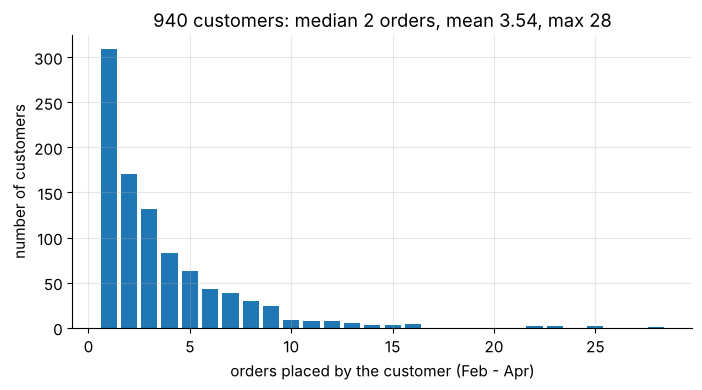

In [32]:
per_customer = q("""
SELECT customer_id, COUNT(*) AS n_orders, SUM(order_total) AS total_spent
FROM orders
WHERE customer_id IS NOT NULL
GROUP BY customer_id
""")
hist = per_customer.n_orders.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(hist.index, hist.values, color="tab:blue")
ax.set_xlabel("orders placed by the customer (Feb - Apr)")
ax.set_ylabel("number of customers")
ax.set_title(f"{len(per_customer)} customers: median {per_customer.n_orders.median():.0f} orders, "
             f"mean {per_customer.n_orders.mean():.2f}, max {per_customer.n_orders.max()}")
plt.show()

**Quick check 3.** A colleague computes the average order value per channel as `SUM(order_total) / COUNT(customer_id)`. Is that right?

<details>
<summary>Answer</summary>

No. `COUNT(customer_id)` skips the guest orders, so in the store channel the denominator is too small (1503 − 84 = 1419 instead of 1503) and the average is inflated, while the numerator still includes the guests' money. Use `AVG(order_total)` or `SUM(order_total) / COUNT(*)`: the denominator must count exactly the rows that contribute to the numerator.
</details>

### ✏️ Exercise 3: April at a glance

For orders placed in **April 2026** (use `WHERE order_ts >= '2026-04-01' AND order_ts < '2026-05-01'`. Section 6 explains why this form is the safe one), return one row per channel with the columns `channel`, `n_orders`, `guest_orders` (orders without a customer) and `n_customers` (number of different customers), sorted by `channel`.

In [33]:
# ✏️ Exercise 3: April at a glance
def ex3_sql() -> str:
    """Return a SQL query (as a string) for Exercise 3."""
    # YOUR CODE HERE
    raise NotImplementedError


EX3_EXPECTED = q("""
SELECT channel, COUNT(*) AS n_orders, COUNT(*) - COUNT(customer_id) AS guest_orders,
       COUNT(DISTINCT customer_id) AS n_customers
FROM orders WHERE order_ts >= '2026-04-01' AND order_ts < '2026-05-01'
GROUP BY channel ORDER BY channel""")


def _diagnose_ex3(got):
    if "n_customers" in got.columns and got.n_customers.sum() == EX3_EXPECTED.n_orders.sum() - EX3_EXPECTED.guest_orders.sum():
        return "n_customers looks like COUNT(customer_id): a customer with several orders must be counted once."
    return None


def _test():
    check_sql(ex3_sql(), EX3_EXPECTED, ordered=True, diagnose=_diagnose_ex3)

run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex3_sql() -> str:
    return """
    SELECT channel,
           COUNT(*)                                             AS n_orders,
           SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS guest_orders,
           COUNT(DISTINCT customer_id)                          AS n_customers
    FROM orders
    WHERE order_ts >= '2026-04-01' AND order_ts < '2026-05-01'
    GROUP BY channel
    ORDER BY channel
    """
```
`COUNT(*) - COUNT(customer_id)` is an equally good way to count the guest orders. `COUNT(DISTINCT customer_id)` ignores `NULL`, so guests do not count as a "customer", which is what we want here.
</details>

### ✏️ Exercise 4: the regulars

Over the whole period, find the registered customers with **at least 10 orders** and a **total spend of at least \$350**. Return `customer_id`, `n_orders` and `total_spent` (the sum of `order_total`, rounded to 2 decimals), sorted by `total_spent` from highest to lowest, then by `customer_id`.

In [34]:
# ✏️ Exercise 4: the regulars
def ex4_sql() -> str:
    """Return a SQL query (as a string) for Exercise 4."""
    # YOUR CODE HERE
    raise NotImplementedError


EX4_EXPECTED = q("""
SELECT customer_id, COUNT(*) AS n_orders, ROUND(SUM(order_total), 2) AS total_spent
FROM orders WHERE customer_id IS NOT NULL
GROUP BY customer_id HAVING COUNT(*) >= 10 AND SUM(order_total) >= 350
ORDER BY total_spent DESC, customer_id""")


def _diagnose_ex4(got):
    if "customer_id" in got.columns and got.customer_id.isna().any():
        return "a NULL customer_id appears: the guest orders form their own group. Filter them out with WHERE."
    if len(got) == 47:
        return "you kept every customer with 10+ orders, but the spend condition is missing."
    return None


def _test():
    check_sql(ex4_sql(), EX4_EXPECTED, ordered=True, diagnose=_diagnose_ex4)

run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex4_sql() -> str:
    return """
    SELECT customer_id,
           COUNT(*)                   AS n_orders,
           ROUND(SUM(order_total), 2) AS total_spent
    FROM orders
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
    HAVING COUNT(*) >= 10 AND SUM(order_total) >= 350
    ORDER BY total_spent DESC, customer_id
    """
```
42 customers qualify (47 have at least 10 orders, but 5 of them spent less than \$350). Both conditions involve aggregates, so they belong in `HAVING`. Without `WHERE customer_id IS NOT NULL`, the 84 guest orders form a `NULL` group with \$3,446.20 of spend, which passes both conditions: you would report 43 "regulars", one of whom is not a customer at all. Prefer `HAVING SUM(order_total) >= 350` over the rounded value, so that rounding never decides who qualifies.
</details>

## 4. Joins

### 4.1 What a join really does

A join combines rows of two tables. Its precise definition is short: take **every pair** of rows (one from each table), and keep the pairs that satisfy the join condition. In relational algebra, with $R \times S$ the set of all pairs (the **Cartesian product**, `CROSS JOIN` in SQL) and $\sigma_\theta$ "keep the rows where $\theta$ is true",

$$
R \bowtie_\theta S = \sigma_\theta(R \times S), \qquad |R \times S| = |R| \cdot |S| .
$$

The size of the result follows directly. For an equality join on a key column $k$, a value $v$ that appears $a_v$ times in $R$ and $b_v$ times in $S$ contributes $a_v \cdot b_v$ pairs, so

$$
|R \bowtie S| = \sum_{v} a_v \, b_v .
$$

If $k$ is unique in $S$ (every $b_v \le 1$), the join can never create more rows than $R$ has. If both sides repeat a value, the counts **multiply**. Keep this formula in mind: it is the whole story of the fan-out trap in Section 5.

Let us watch the four join types on two tiny tables. Customer 3 (Cleo) has no orders, and order 104 points to a customer 9 who does not exist:

In [35]:
load_table("mini_customers", [("customer_id", "int"), ("name", "text")],
           [(1, "Ada"), (2, "Ben"), (3, "Cleo")])
load_table("mini_orders", [("order_id", "int"), ("customer_id", "int"), ("amount", "float")],
           [(101, 1, 20.0), (102, 1, 35.0), (103, 2, 15.0), (104, 9, 50.0)])
print("CROSS JOIN rows:", q("SELECT COUNT(*) AS n FROM mini_customers CROSS JOIN mini_orders").n[0], "= 3 x 4")

HAS_RIGHT_FULL = sqlite3.sqlite_version_info >= (3, 39, 0)   # RIGHT/FULL JOIN arrived in SQLite 3.39 (2022)
print(f"SQLite {sqlite3.sqlite_version}: RIGHT and FULL OUTER JOIN supported -> {HAS_RIGHT_FULL}")

CROSS JOIN rows: 12 = 3 x 4
SQLite 3.45.1: RIGHT and FULL OUTER JOIN supported -> True


In [36]:
JOIN_SQL = """
SELECT c.customer_id, c.name, o.order_id, o.customer_id AS order_customer, o.amount
FROM mini_customers AS c
{kind} JOIN mini_orders AS o ON o.customer_id = c.customer_id
ORDER BY o.order_id NULLS LAST, c.customer_id
"""
for kind in ["INNER", "LEFT", "RIGHT", "FULL"]:
    con = db if (kind in ("INNER", "LEFT") or HAS_RIGHT_FULL) else duck   # fall back to DuckDB on old SQLite
    result = q(JOIN_SQL.format(kind=kind), con)
    print(f"{kind} JOIN ({engine_name(con)}): {len(result)} rows")
    display(result)

INNER JOIN (SQLite): 3 rows


,customer_id,name,order_id,order_customer,amount
0,1,Ada,101,1,20.0
1,1,Ada,102,1,35.0
2,2,Ben,103,2,15.0


LEFT JOIN (SQLite): 4 rows


,customer_id,name,order_id,order_customer,amount
0,1,Ada,101,1,20.0
1,1,Ada,102,1,35.0
2,2,Ben,103,2,15.0
3,3,Cleo,<NA>,<NA>,NaN


RIGHT JOIN (SQLite): 4 rows


,customer_id,name,order_id,order_customer,amount
0,1,Ada,101,1,20.0
1,1,Ada,102,1,35.0
2,2,Ben,103,2,15.0
3,<NA>,None,104,9,50.0


FULL JOIN (SQLite): 5 rows


,customer_id,name,order_id,order_customer,amount
0,1,Ada,101,1,20.0
1,1,Ada,102,1,35.0
2,2,Ben,103,2,15.0
3,<NA>,None,104,9,50.0
4,3,Cleo,<NA>,<NA>,NaN


Read the four results as a story:

- **`INNER JOIN`** keeps only matching pairs: 3 rows. Ada appears **twice** because she has two orders: the join produces one row per *pair*, so the result has the grain of `mini_orders` restricted to known customers. Cleo and order 104 disappear without a trace.
- **`LEFT JOIN`** keeps every row of the **left** table. Cleo, who has no partner, is kept once with `NULL` in all the right-hand columns: 3 + 1 = 4 rows.
- **`RIGHT JOIN`** is the mirror image: every row of the right table is kept, so the orphan order 104 appears with `NULL` customer columns. Any right join can be rewritten as a left join by swapping the tables, which is what most people do.
- **`FULL OUTER JOIN`** keeps unmatched rows from **both** sides: 3 + 1 + 1 = 5 rows.

In general, $|\text{LEFT}| = |\text{INNER}| + (\text{left rows without a partner})$ and $|\text{FULL}| = |\text{INNER}| + (\text{unmatched left}) + (\text{unmatched right})$.

> **Common pitfall.** Venn diagrams are often used to explain joins, but they mislead: a join does not intersect two sets of rows (the two tables do not even have the same columns). It pairs rows up, and a row can be paired many times, which is exactly what a Venn diagram cannot show.

On an older SQLite (before 3.39, still common on some systems), `RIGHT` and `FULL` are missing. A `FULL` join can always be emulated as "the `LEFT` join, plus the right-hand rows that found no partner", using an anti-join (Section 4.3):

In [37]:
FULL_EMULATED = """
SELECT c.customer_id, c.name, o.order_id, o.customer_id AS order_customer, o.amount
FROM mini_customers AS c LEFT JOIN mini_orders AS o ON o.customer_id = c.customer_id
UNION ALL
SELECT NULL, NULL, o.order_id, o.customer_id, o.amount          -- orders without a matching customer
FROM mini_orders AS o
WHERE NOT EXISTS (SELECT 1 FROM mini_customers AS c WHERE c.customer_id = o.customer_id)
"""
emulated = q(FULL_EMULATED)
native = q(JOIN_SQL.format(kind="FULL"), duck)
print("emulated FULL JOIN in SQLite == native FULL JOIN in DuckDB:", frame_diff(emulated, native) is None)

emulated FULL JOIN in SQLite == native FULL JOIN in DuckDB: True


`UNION ALL` stacks two results with the same number of columns. (Plain `UNION` would also remove duplicate rows, which costs time and can silently delete legitimate identical rows, so use `UNION ALL` unless you really want deduplication.)

### 4.2 `ON` versus `WHERE` in a `LEFT JOIN`

For an inner join it makes no difference whether a condition is written in `ON` or in `WHERE`. For a left join it makes a big difference, because the clauses run at different times:

- a condition in **`ON`** decides which right-hand rows count as a **partner**, and a left row without partners is still kept (with `NULL`s).
- a condition in **`WHERE`** runs **after** the join and filters the joined rows. For a left row without partner the right-hand columns are `NULL`, the condition is unknown, and the row is dropped.

Task: *for every customer, count their March orders (zero included)*.

In [38]:
march_on = q("""
SELECT c.customer_id, COUNT(o.order_id) AS march_orders
FROM customers AS c
LEFT JOIN orders AS o
       ON o.customer_id = c.customer_id
      AND o.order_ts >= '2026-03-01' AND o.order_ts < '2026-04-01'     -- condition in ON
GROUP BY c.customer_id
""")
march_where = q("""
SELECT c.customer_id, COUNT(o.order_id) AS march_orders
FROM customers AS c
LEFT JOIN orders AS o
       ON o.customer_id = c.customer_id
WHERE o.order_ts >= '2026-03-01' AND o.order_ts < '2026-04-01'        -- condition in WHERE
GROUP BY c.customer_id
""")
print(f"condition in ON   : {len(march_on)} customers, {(march_on.march_orders == 0).sum()} of them with zero March orders")
print(f"condition in WHERE: {len(march_where)} customers, {(march_where.march_orders == 0).sum()} of them with zero March orders")

condition in ON   : 1500 customers, 880 of them with zero March orders
condition in WHERE: 620 customers, 0 of them with zero March orders


With the date condition in `WHERE`, the 880 customers without a March order vanish. The 560 who never ordered have only their `NULL`-extended row, where `o.order_ts` is `NULL` and the condition is unknown, and the other 320 ordered only in February or April, so each of their joined rows carries a real date for which the condition is false. Either way `WHERE` drops the rows, and the `LEFT JOIN` has silently become an `INNER JOIN`. Two related details in the correct query:

- It counts `COUNT(o.order_id)`, not `COUNT(*)`. A customer without partner still occupies **one** joined row (the `NULL`-extended one), so `COUNT(*)` would report 1 order instead of 0.
- To filter the **left** table (say, only Halifax customers), the condition *does* belong in `WHERE`: it refers to columns that are never `NULL`-extended.

> **Key idea.** In a `LEFT JOIN`, conditions on the **right** table go in `ON`, and conditions on the **left** table go in `WHERE`.

### 4.3 Semi-joins and anti-joins

Two very common questions are not really "joins" at all, because you do not want any columns from the second table:

- **semi-join**: rows of `A` that have **at least one** partner in `B` (customers who ordered).
- **anti-join**: rows of `A` that have **no** partner in `B` (customers who never ordered).

A plain join answers the first question badly: it returns one row per *pair*, so a customer with 28 orders appears 28 times. `EXISTS` returns each customer once:

In [39]:
print("JOIN rows     :", q("SELECT COUNT(*) AS n FROM customers c JOIN orders o ON o.customer_id = c.customer_id").n[0])
print("EXISTS (semi) :", q("""SELECT COUNT(*) AS n FROM customers c
                              WHERE EXISTS (SELECT 1 FROM orders o WHERE o.customer_id = c.customer_id)""").n[0])

JOIN rows     : 3332


EXISTS (semi) : 940


`EXISTS (subquery)` is true when the subquery returns at least one row. The subquery mentions `c.customer_id` from the outer query, so it is a **correlated subquery**: conceptually it is re-evaluated for each customer (engines optimize this into an efficient join). `WHERE customer_id IN (SELECT customer_id FROM orders)` is an equivalent semi-join.

For the anti-join there are three common spellings. Two of them are correct, but the third has a famous trap:

In [40]:
anti_sqls = {
    "LEFT JOIN ... IS NULL": """
        SELECT COUNT(*) AS n FROM customers c
        LEFT JOIN orders o ON o.customer_id = c.customer_id
        WHERE o.order_id IS NULL""",
    "NOT EXISTS": """
        SELECT COUNT(*) AS n FROM customers c
        WHERE NOT EXISTS (SELECT 1 FROM orders o WHERE o.customer_id = c.customer_id)""",
    "NOT IN": """
        SELECT COUNT(*) AS n FROM customers
        WHERE customer_id NOT IN (SELECT customer_id FROM orders)""",
}
for name, sql in anti_sqls.items():
    print(f"{name:<22} SQLite: {q(sql).n[0]:>4}   DuckDB: {q(sql, duck).n[0]:>4}")

LEFT JOIN ... IS NULL  SQLite:  560   DuckDB:  560


NOT EXISTS             SQLite:  560   DuckDB:  560
NOT IN                 SQLite:    0   DuckDB:    0


560 customers never ordered, yet `NOT IN` returns **zero** in both engines. The reason is the 84 guest orders, whose `customer_id` is `NULL`. By definition,

$$
x \texttt{ NOT IN } (a_1, \dots, a_n) \;\equiv\; x \neq a_1 \texttt{ AND } \dots \texttt{ AND } x \neq a_n ,
$$

and as soon as one $a_i$ is `NULL`, the term $x \neq \texttt{NULL}$ is unknown. A conjunction containing an unknown term can be false or unknown, but never true, so **no row** passes the `WHERE`. A single `NULL` in the subquery silently empties the result.

> **Key idea.** Write anti-joins with `NOT EXISTS` (or `LEFT JOIN … WHERE right_key IS NULL`). If you use `NOT IN`, add `WHERE customer_id IS NOT NULL` inside the subquery.

In the `LEFT JOIN … IS NULL` form, test a column that can only be `NULL` because the row found no partner, ideally the right table's key, not a column that might legitimately contain `NULL`.

### 4.4 Anti-joins as data-quality probes

Anti-joins in both directions reveal broken relationships. Do all order lines belong to an existing order? Does every order have lines?

In [41]:
orphans = q("""
SELECT COUNT(*) AS orphan_lines, COUNT(DISTINCT i.order_id) AS orphan_orders,
       ROUND(SUM(i.quantity * i.unit_price), 2) AS orphan_amount
FROM order_items AS i
LEFT JOIN orders AS o ON o.order_id = i.order_id
WHERE o.order_id IS NULL
""")
no_lines = q("""
SELECT COUNT(*) AS orders_without_lines, ROUND(SUM(o.order_total), 2) AS their_total
FROM orders AS o
WHERE NOT EXISTS (SELECT 1 FROM order_items AS i WHERE i.order_id = o.order_id)
""")
display(orphans)
display(no_lines)

,orphan_lines,orphan_orders,orphan_amount
0,35,19,736.58


,orders_without_lines,their_total
0,85,5175.0


Both findings match quirks of our bookstore: 35 lines (from 19 cancelled orders) point to orders that no longer exist, and 85 gift-card orders have no lines at all. Neither is an error message: they are facts about the data that every query must handle on purpose. An `INNER JOIN` between `orders` and `order_items` silently drops both groups, and Section 5 shows how much money that hides.

**Quick check 4.** `SELECT COUNT(*) FROM orders o LEFT JOIN customers c ON c.customer_id = o.customer_id` returns 3416, exactly the number of orders. Why can this join not change the row count, while `customers LEFT JOIN orders` has 3332 + 560 = 3892 rows?

<details>
<summary>Answer</summary>

Each order has at most one matching customer, because `customer_id` is the key of `customers` (every $b_v \le 1$ in the formula of Section 4.1). So every order produces exactly one row: its matching customer, or the `NULL`-extended row for guests. Joining **many → one** keeps the grain of the "many" side. In the other direction, each customer is repeated once per order (3332 rows for customers with orders), plus one `NULL`-extended row for each of the 560 customers without orders.
</details>

### ✏️ Exercise 5: lapsed customers

A customer is **lapsed** if they placed at least one order in **February 2026** but **none in March 2026**. Return the `customer_id` of every lapsed customer (one row each), sorted by `customer_id`.

In [42]:
# ✏️ Exercise 5: lapsed customers (ordered in February, not in March)
def ex5_sql() -> str:
    """Return a SQL query (as a string) for Exercise 5."""
    # YOUR CODE HERE
    raise NotImplementedError


EX5_EXPECTED = q("""
SELECT DISTINCT f.customer_id
FROM orders AS f
WHERE f.order_ts >= '2026-02-01' AND f.order_ts < '2026-03-01' AND f.customer_id IS NOT NULL
  AND NOT EXISTS (SELECT 1 FROM orders AS m
                  WHERE m.customer_id = f.customer_id
                    AND m.order_ts >= '2026-03-01' AND m.order_ts < '2026-04-01')
ORDER BY f.customer_id""")


def _diagnose_ex5(got):
    if len(got) == 0:
        return "no rows at all: a NOT IN subquery that returns a NULL customer_id empties the result."
    if len(got) > len(EX5_EXPECTED) and got.iloc[:, 0].duplicated().any():
        return "some customers appear several times (one row per February order). Use DISTINCT."
    if got.iloc[:, 0].isna().any():
        return "a NULL customer_id appears: guest orders are not customers."
    return None


def _test():
    check_sql(ex5_sql(), EX5_EXPECTED, ordered=True, diagnose=_diagnose_ex5)

run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex5_sql() -> str:
    return """
    SELECT DISTINCT f.customer_id
    FROM orders AS f
    WHERE f.order_ts >= '2026-02-01' AND f.order_ts < '2026-03-01'
      AND f.customer_id IS NOT NULL
      AND NOT EXISTS (
            SELECT 1 FROM orders AS m
            WHERE m.customer_id = f.customer_id
              AND m.order_ts >= '2026-03-01' AND m.order_ts < '2026-04-01')
    ORDER BY f.customer_id
    """
```
187 of the 573 February customers lapsed. `DISTINCT` is needed because a customer with three February orders would otherwise appear three times. A version with `customer_id NOT IN (SELECT customer_id FROM orders WHERE <March>)` returns nothing, because some March orders are guest orders with a `NULL` `customer_id`.
</details>

### ✏️ Exercise 6: Halifax in April, zeros included

For **every** customer whose city is `'Halifax'`, return `customer_id`, `n_april_orders` (their number of orders in April 2026, 0 if none) and `april_spend` (the sum of their April `order_total`, rounded to 2 decimals, **0** if none), sorted by `customer_id`.

In [43]:
# ✏️ Exercise 6: Halifax customers and their April orders (zeros included)
def ex6_sql() -> str:
    """Return a SQL query (as a string) for Exercise 6."""
    # YOUR CODE HERE
    raise NotImplementedError


EX6_EXPECTED = q("""
SELECT c.customer_id, COUNT(o.order_id) AS n_april_orders,
       COALESCE(ROUND(SUM(o.order_total), 2), 0) AS april_spend
FROM customers AS c
LEFT JOIN orders AS o ON o.customer_id = c.customer_id
                     AND o.order_ts >= '2026-04-01' AND o.order_ts < '2026-05-01'
WHERE c.city = 'Halifax'
GROUP BY c.customer_id ORDER BY c.customer_id""")


def _diagnose_ex6(got):
    if len(got) < len(EX6_EXPECTED):
        return ("customers without April orders are missing. Is the April condition in WHERE "
                "instead of ON (or did you use an INNER JOIN)?")
    if "n_april_orders" in got.columns and (got.n_april_orders >= 1).all():
        return "nobody has 0 orders: COUNT(*) counts the NULL-extended row. Count a column of orders instead."
    if "april_spend" in got.columns and got.april_spend.isna().any():
        return "april_spend is NULL for customers without orders, but the task asks for 0 (COALESCE)."
    return None


def _test():
    check_sql(ex6_sql(), EX6_EXPECTED, ordered=True, diagnose=_diagnose_ex6)

run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex6_sql() -> str:
    return """
    SELECT c.customer_id,
           COUNT(o.order_id)                          AS n_april_orders,
           COALESCE(ROUND(SUM(o.order_total), 2), 0)  AS april_spend
    FROM customers AS c
    LEFT JOIN orders AS o
           ON o.customer_id = c.customer_id
          AND o.order_ts >= '2026-04-01' AND o.order_ts < '2026-05-01'
    WHERE c.city = 'Halifax'
    GROUP BY c.customer_id
    ORDER BY c.customer_id
    """
```
The result has all 117 Halifax customers, 63 of whom placed no April order. Moving the April condition into `WHERE` leaves only the 54 customers who did order. The city condition is about the left table, so it belongs in `WHERE`. `SUM` over no partners is `NULL`, hence the `COALESCE`.
</details>

## 5. The fan-out trap

### 5.1 The task

The head of sales asks for a **March 2026 report by channel**:

> For each channel: the number of orders, the number of different customers, the number of books sold (units), the revenue (the sum of `order_total`) and the average order value. Only show channels with at least 150 orders, highest revenue first.

Orders, customers, revenue and average order value live in `orders` (grain: one row per order). Units live in `order_items` (grain: one row per order line). So it seems natural to join the two tables and aggregate:

In [44]:
MARCH = "o.order_ts >= '2026-03-01' AND o.order_ts < '2026-04-01'"

NAIVE_REPORT = f"""
SELECT o.channel,
       COUNT(*)                      AS n_orders,
       COUNT(DISTINCT o.customer_id) AS n_customers,
       SUM(i.quantity)               AS units,
       ROUND(SUM(o.order_total), 2)  AS revenue,
       ROUND(AVG(o.order_total), 2)  AS avg_order_value
FROM orders AS o
JOIN order_items AS i ON i.order_id = o.order_id
WHERE {MARCH}
GROUP BY o.channel
HAVING COUNT(*) >= 150
ORDER BY revenue DESC
"""
naive_report = q(NAIVE_REPORT)
naive_report

,channel,n_orders,n_customers,units,revenue,avg_order_value
0,store,914,333,1126,44741.51,48.95
1,web,648,292,788,29656.66,45.77
2,app,429,211,529,20327.14,47.38


The query runs, the numbers look plausible, and almost all of them are wrong. Before reading on, try to find out *which* numbers are wrong using only what you learned in Sections 1 and 4.

### 5.2 Diagnosis: count the rows

The fastest diagnostic for any join is to compare row counts before and after it. If the result is supposed to have the grain "one row per order", the join must not change the number of rows.

In [45]:
print("March orders                       :", q(f"SELECT COUNT(*) AS n FROM orders AS o WHERE {MARCH}").n[0])
print("rows after JOIN order_items        :", q(f"""SELECT COUNT(*) AS n FROM orders AS o
                                                   JOIN order_items AS i ON i.order_id = o.order_id WHERE {MARCH}""").n[0])
print("rows after LEFT JOIN order_items   :", q(f"""SELECT COUNT(*) AS n FROM orders AS o
                                                   LEFT JOIN order_items AS i ON i.order_id = o.order_id WHERE {MARCH}""").n[0])

March orders                       : 1204
rows after JOIN order_items        : 2064
rows after LEFT JOIN order_items   : 2091


1204 orders became 2064 rows. Look at one order with several lines to see what happened:

In [46]:
q(f"""
SELECT o.order_id, o.channel, o.order_total, i.line_no, i.book_id, i.quantity
FROM orders AS o JOIN order_items AS i ON i.order_id = o.order_id
WHERE o.order_id = 50138
""")

,order_id,channel,order_total,line_no,book_id,quantity
0,50138,store,89.95,1,305,1
1,50138,store,89.95,2,315,1
2,50138,store,89.95,3,323,3


The join produces one row per **line**, and each row carries a copy of the order-level columns. Order 50138 has three lines, so its `order_total` of \$89.95 appears three times, and `SUM(o.order_total)` adds it three times. This is **fan-out**: joining a table at a coarse grain (order) to a table at a finer grain (line) multiplies the coarse rows, and every aggregate of a coarse-grain column becomes wrong:

| report column | computed from | after the join it is... |
|---|---|---|
| `n_orders` = `COUNT(*)` | joined rows | the number of **lines**, not orders |
| `revenue` = `SUM(order_total)` | order grain | each order counted once **per line** |
| `avg_order_value` | order grain | an average over lines, biased upward (5.3) |
| `n_customers` = `COUNT(DISTINCT customer_id)` | order grain | immune to duplicates, but loses customers whose only orders were gift cards (dropped by the inner join) |
| `units` = `SUM(quantity)` | line grain | **correct**: each line appears exactly once |

A rule of thumb follows: after a join, an aggregate is only safe for columns that live at the grain of the joined result.

Two more consequences are easy to miss. The `HAVING COUNT(*) >= 150` filter now compares the number of *lines* with 150, so a channel can pass the threshold with fewer than 150 real orders. And the inner join silently drops every gift-card order, which has no lines.

### 5.3 How large is the error? An exact formula

Consider the orders that have at least one line. Order $o$ has total $T_o$ and $n_o \ge 1$ lines, and after the join it appears $n_o$ times. With $N$ such orders, $\bar T = \frac1N \sum_o T_o$ and $\bar n = \frac1N \sum_o n_o$:

$$
\text{naive SUM} = \sum_o n_o T_o, \qquad
\text{naive COUNT} = \sum_o n_o = N \bar n, \qquad
\text{naive AVG} = \frac{\sum_o n_o T_o}{\sum_o n_o}.
$$

So the naive average is a **weighted** average of order totals with weights $n_o$: orders with many lines get more say. To see the size of the bias, use the definition of the (population) covariance, $\operatorname{Cov}(n, T) = \frac1N \sum_o n_o T_o - \bar n \bar T$, which gives $\sum_o n_o T_o = N\big(\operatorname{Cov}(n,T) + \bar n \bar T\big)$. Dividing by $N \bar n$:

$$
\text{naive AVG} \;=\; \bar T + \frac{\operatorname{Cov}(n, T)}{\bar n}.
$$

The naive average is too high exactly when orders with more lines tend to have larger totals ($\operatorname{Cov} > 0$), which is true in practically every shop. And the naive revenue overstates the truth by the factor $\sum_o n_o T_o / \sum_o T_o$, a revenue-weighted average number of lines per order. Let us check both claims on the March orders:

In [47]:
per_order = q(f"""
SELECT o.order_id, o.channel, o.order_total AS T, COUNT(*) AS n
FROM orders AS o JOIN order_items AS i ON i.order_id = o.order_id
WHERE {MARCH}
GROUP BY o.order_id, o.channel, o.order_total
""")
rows = []
for channel, g in per_order.groupby("channel"):
    T, n = g["T"].to_numpy(float), g["n"].to_numpy(float)
    cov = np.mean((n - n.mean()) * (T - T.mean()))          # population covariance
    rows.append({"channel": channel, "orders with lines": len(g),
                 "true AVG": T.mean(), "naive AVG": (n * T).sum() / n.sum(),
                 "true AVG + Cov/mean(n)": T.mean() + cov / n.mean(),
                 "corr(n, T)": np.corrcoef(n, T)[0, 1],
                 "revenue inflation factor": (n * T).sum() / T.sum()})
pd.DataFrame(rows).round(4)

,channel,orders with lines,true AVG,naive AVG,true AVG + Cov/mean(n),"corr(n, T)",revenue inflation factor
0,app,245,40.4059,47.3826,47.3826,0.7115,2.0534
1,phone,40,53.6158,66.5353,66.5353,0.8262,2.2648
2,store,507,38.5656,48.9513,48.9513,0.8071,2.2882
3,web,385,37.3040,45.7665,45.7665,0.7999,2.0649


The formula matches the naive averages to the cent, and the correlation between the number of lines and the order total is between 0.7 and 0.83: big orders have many lines. The revenue of orders with lines is overstated by a factor of 2.05 to 2.29. The left plot shows the reason, and the right plot compares the naive revenue with the true revenue (computed from `orders` alone).

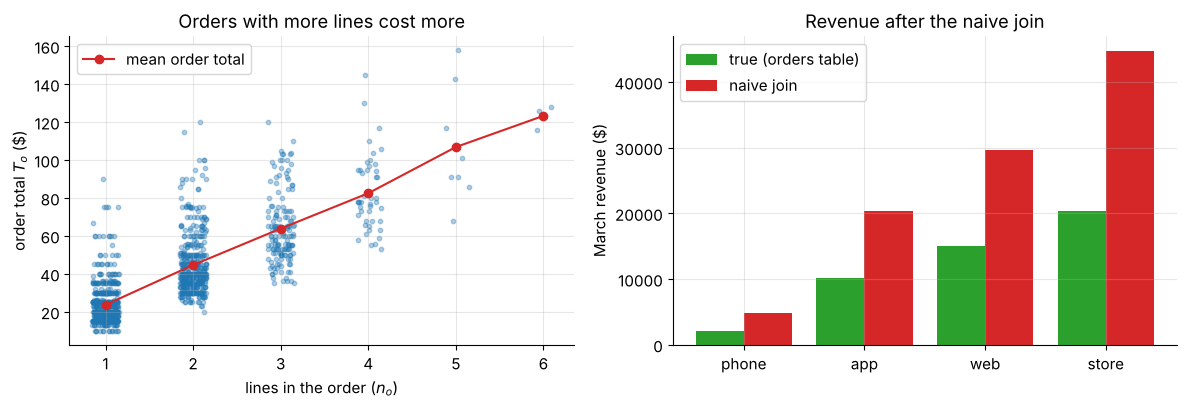

In [48]:
true_by_channel = q(f"SELECT o.channel, SUM(o.order_total) AS revenue FROM orders AS o WHERE {MARCH} GROUP BY o.channel")
naive_by_channel = q(f"""SELECT o.channel, SUM(o.order_total) AS revenue FROM orders AS o
                         JOIN order_items AS i ON i.order_id = o.order_id WHERE {MARCH} GROUP BY o.channel""")
compare = true_by_channel.merge(naive_by_channel, on="channel", suffixes=("_true", "_naive")).sort_values("revenue_true")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
jitter = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(per_order))
ax1.scatter(per_order.n + jitter, per_order["T"], s=10, alpha=0.35, color="tab:blue")
mean_T = per_order.groupby("n")["T"].mean()
ax1.plot(mean_T.index, mean_T.values, "o-", color="tab:red", label="mean order total")
ax1.set_xlabel("lines in the order ($n_o$)")
ax1.set_ylabel(r"order total $T_o$ (\$)")
ax1.set_title("Orders with more lines cost more")
ax1.legend()
x = np.arange(len(compare))
ax2.bar(x - 0.2, compare.revenue_true, width=0.4, label="true (orders table)", color="tab:green")
ax2.bar(x + 0.2, compare.revenue_naive, width=0.4, label="naive join", color="tab:red")
ax2.set_xticks(x)
ax2.set_xticklabels(compare.channel)
ax2.set_ylabel("March revenue ($)")
ax2.set_title("Revenue after the naive join")
ax2.legend()
plt.tight_layout()
plt.show()

### 5.4 The fix: bring every table to the report's grain *before* joining

The report's grain is "one row per order, then one row per channel". `order_items` is finer than that, so we first **aggregate it to the order grain** in a **CTE** (common table expression, a named subquery introduced with `WITH`. Section 7 covers CTEs in detail). After that step, both inputs have exactly one row per order, and the join cannot multiply anything:

In [49]:
CORRECT_REPORT = f"""
WITH order_sizes AS (               -- grain: one row per order (that has lines)
    SELECT order_id,
           SUM(quantity) AS units,
           COUNT(*)      AS n_lines
    FROM order_items
    GROUP BY order_id
)
SELECT o.channel,
       COUNT(*)                      AS n_orders,
       COUNT(DISTINCT o.customer_id) AS n_customers,
       COALESCE(SUM(s.units), 0)     AS units,
       ROUND(SUM(o.order_total), 2)  AS revenue,
       ROUND(AVG(o.order_total), 2)  AS avg_order_value
FROM orders AS o                    -- grain: one row per order
LEFT JOIN order_sizes AS s ON s.order_id = o.order_id
WHERE {MARCH}
GROUP BY o.channel
HAVING COUNT(*) >= 150
ORDER BY revenue DESC
"""
correct_report = q(CORRECT_REPORT)
display(correct_report)
_ = both(CORRECT_REPORT)

,channel,n_orders,n_customers,units,revenue,avg_order_value
0,store,520,338,1126,20352.74,39.14
1,web,396,297,788,15012.03,37.91
2,app,248,212,529,10124.45,40.82


SQLite and DuckDB agree.


Compare with the naive version: the store had 520 orders, not 914, and \$20,352.74 of revenue, not \$44,741.51, and its average order value is \$39.14, not \$48.95. Only `units` (a line-grain quantity) was right before. Each design decision in the correct query has a reason:

- **Pre-aggregation in the CTE** makes `order_sizes` unique per `order_id`, so the join is one-to-one (or one-to-zero), and order-level sums are no longer multiplied.
- **`LEFT JOIN`**, not `JOIN`, keeps the gift-card orders, which are real orders with real revenue but no lines. Their `units` are `NULL`, which `SUM` skips, and `COALESCE(..., 0)` makes a channel without any lines show 0 instead of `NULL`.
- **`COUNT(*)` is now safe** because the joined result has one row per order. (`COUNT(o.order_id)` is equally correct, but `COUNT(s.order_id)` would not be, see below.)
- **The date filter uses a half-open interval** on the order timestamp, so the order placed at 23:59:59.640 on March 31 is included and the subscription boxes created at midnight on April 1 are not (Section 6).

> **Key idea.** Aggregate each table to the grain of the result **before** joining, then join tables that share that grain. Check the claim with a row count: the join must not change the number of rows.

### 5.5 Tempting wrong fixes

When a report is "a bit too high", it is tempting to patch the symptom. Here are five patches that people really write, each evaluated on the whole of March (all channels together) against the true values:

In [50]:
ORDER_SIZES = "WITH s AS (SELECT order_id, SUM(quantity) AS units FROM order_items GROUP BY order_id) "
VARIANTS = {
    "naive JOIN":
        f"""SELECT COUNT(*) AS n_orders, SUM(o.order_total) AS revenue, AVG(o.order_total) AS aov
            FROM orders o JOIN order_items i ON i.order_id = o.order_id WHERE {MARCH}""",
    "COUNT(DISTINCT order_id) on the naive join":
        f"""SELECT COUNT(DISTINCT o.order_id) AS n_orders, SUM(o.order_total) AS revenue,
                   SUM(o.order_total) / COUNT(DISTINCT o.order_id) AS aov
            FROM orders o JOIN order_items i ON i.order_id = o.order_id WHERE {MARCH}""",
    "SUM(DISTINCT order_total)":
        f"""SELECT COUNT(DISTINCT o.order_id) AS n_orders, SUM(DISTINCT o.order_total) AS revenue,
                   SUM(DISTINCT o.order_total) / COUNT(DISTINCT o.order_id) AS aov
            FROM orders o LEFT JOIN order_items i ON i.order_id = o.order_id WHERE {MARCH}""",
    "CTE + INNER JOIN":
        ORDER_SIZES + f"""SELECT COUNT(*) AS n_orders, SUM(o.order_total) AS revenue, AVG(o.order_total) AS aov
            FROM orders o JOIN s ON s.order_id = o.order_id WHERE {MARCH}""",
    "CTE + LEFT JOIN, but COUNT(s.order_id)":
        ORDER_SIZES + f"""SELECT COUNT(s.order_id) AS n_orders, SUM(o.order_total) AS revenue,
                   SUM(o.order_total) / COUNT(s.order_id) AS aov
            FROM orders o LEFT JOIN s ON s.order_id = o.order_id WHERE {MARCH}""",
    "CTE + LEFT JOIN, COUNT(*)  (correct)":
        ORDER_SIZES + f"""SELECT COUNT(*) AS n_orders, SUM(o.order_total) AS revenue, AVG(o.order_total) AS aov
            FROM orders o LEFT JOIN s ON s.order_id = o.order_id WHERE {MARCH}""",
}
truth = q(f"SELECT COUNT(*) AS n_orders, SUM(order_total) AS revenue, AVG(order_total) AS aov FROM orders o WHERE {MARCH}").iloc[0]
rows = []
for name, sql in VARIANTS.items():
    r = q(sql).iloc[0]
    rows.append({"variant": name, "n_orders": int(r.n_orders), "revenue": round(r.revenue, 2), "aov": round(r.aov, 2),
                 "all correct?": bool(r.n_orders == truth.n_orders and abs(r.revenue - truth.revenue) < 0.005
                                      and abs(r.aov - truth.aov) < 0.005)})
print(f"truth (orders table alone): n_orders={int(truth.n_orders)}, revenue={truth.revenue:.2f}, aov={truth.aov:.2f}")
pd.DataFrame(rows)

truth (orders table alone): n_orders=1204, revenue=47633.85, aov=39.56


,variant,n_orders,revenue,aov,all correct?
0,naive JOIN,2064,99582.39,48.25,False
1,COUNT(DISTINCT order_id) on the naive join,1177,99582.39,84.61,False
2,SUM(DISTINCT order_total),1204,10959.65,9.10,False
3,CTE + INNER JOIN,1177,45958.85,39.05,False
4,"CTE + LEFT JOIN, but COUNT(s.order_id)",1177,47633.85,40.47,False
5,"CTE + LEFT JOIN, COUNT(*) (correct)",1204,47633.85,39.56,True


Why each patch fails:

1. **`COUNT(DISTINCT o.order_id)`** repairs the order count (apart from the dropped gift cards: 1177 instead of 1204), but leaves the inflated sum untouched, so dividing the two makes the average order value **worse**: \$84.61 instead of \$39.56.
2. **`SUM(DISTINCT o.order_total)`** looks clever: "sum each order total only once". But `DISTINCT` works on **values**, not on orders. Two different orders that both cost \$14.99 contribute \$14.99 once, together. Prices in a shop repeat constantly (93 March orders have a total of exactly \$14.99), so this "fix" loses more than three quarters of the revenue. It is right only by accident, when every order total is different.
3. **Pre-aggregating, but with an `INNER JOIN`**, fixes the multiplication but drops the 27 gift-card orders of March together with their \$1,675 of revenue.
4. **`LEFT JOIN` with `COUNT(s.order_id)`** keeps the gift-card revenue in the numerator but not in the denominator: `COUNT` of a right-hand column skips the `NULL`-extended rows. The average order value comes out too high (\$40.47), and a `HAVING COUNT(s.order_id) >= 150` would compare the wrong count with the threshold.
5. Only the last variant is right: one row per order, all orders kept, each order counted once.

Two more wrong denominators appear in real reports: `SUM(order_total) / SUM(units)` is **revenue per book sold**, a legitimate metric but not the average order value, and `SUM(order_total) / COUNT(DISTINCT customer_id)` is **revenue per customer**. Always ask: *one unit of the denominator is one what?* For an average order value, the answer must be "one order", counted once, gift cards included.

> **Common pitfall.** A `DISTINCT` added "until the numbers look right" almost always hides a grain problem instead of solving it. Fix the grain instead.

### 5.6 The same trap in pandas

`DataFrame.merge` is a join, so it fans out in exactly the same way. Its `validate=` argument turns your grain assumption into an **assertion**: `"one_to_one"`, `"one_to_many"`, `"many_to_one"` or `"many_to_many"`. If the data violate the declared relationship, pandas raises a `MergeError` instead of silently multiplying rows. `indicator=True` adds a column `_merge` that says where each row came from (`both`, `left_only`, `right_only`).

In [51]:
orders_df = q("SELECT * FROM orders")
items_df = q("SELECT * FROM order_items")
march_df = orders_df[(orders_df.order_ts >= "2026-03-01") & (orders_df.order_ts < "2026-04-01")]

try:
    march_df.merge(items_df, on="order_id", how="left", validate="one_to_one")
except pd.errors.MergeError as err:
    print("MergeError:", err)

order_sizes_df = items_df.groupby("order_id", as_index=False).agg(units=("quantity", "sum"))
merged = march_df.merge(order_sizes_df, on="order_id", how="left", validate="one_to_one", indicator=True)
print(f"rows: {len(march_df)} orders -> {len(merged)} after the merge (grain preserved)")
print(merged["_merge"].value_counts().to_dict())

MergeError: Merge keys are not unique in right dataset; not a one-to-one merge
rows: 1204 orders -> 1204 after the merge (grain preserved)
{'both': 1177, 'left_only': 27, 'right_only': 0}


The 27 `left_only` rows are March's gift-card orders. The rest of the report in pandas, with `groupby` + named aggregation, and a reconciliation against the SQL result:

In [52]:
pandas_report = (merged.groupby("channel", as_index=False)
                 .agg(n_orders=("order_id", "size"), n_customers=("customer_id", "nunique"),
                      units=("units", "sum"), revenue=("order_total", "sum"), avg_order_value=("order_total", "mean"))
                 .query("n_orders >= 150")
                 .round({"revenue": 2, "avg_order_value": 2})
                 .sort_values("revenue", ascending=False, ignore_index=True))
display(pandas_report)
print("pandas report == SQL report:", frame_diff(pandas_report, correct_report, ordered=True) is None)

,channel,n_orders,n_customers,units,revenue,avg_order_value
0,store,520,338,1126.0,20352.74,39.14
1,web,396,297,788.0,15012.03,37.91
2,app,248,212,529.0,10124.45,40.82


pandas report == SQL report: True


`"size"` counts rows (like `COUNT(*)`), `"count"` would count non-missing values (like `COUNT(col)`), and `"nunique"` ignores missing values, exactly like `COUNT(DISTINCT col)`.

### ✏️ Exercise 7: revenue by genre

For orders placed in **March 2026**, return one row per `genre` with: `n_orders` (the number of **different** orders that contain at least one line of that genre), `units` (books sold) and `line_revenue` (the sum of `quantity * unit_price`, rounded to 2 decimals), sorted by `line_revenue` from highest to lowest. You need three tables: `order_items` (the lines), `books` (the genre) and `orders` (the date).

Think about grain first: what is the grain of `order_items` joined to `books`? Can this join fan out?

In [53]:
# ✏️ Exercise 7: March revenue by genre
def ex7_sql() -> str:
    """Return a SQL query (as a string) for Exercise 7."""
    # YOUR CODE HERE
    raise NotImplementedError


EX7_EXPECTED = q(f"""
SELECT b.genre, COUNT(DISTINCT i.order_id) AS n_orders, SUM(i.quantity) AS units,
       ROUND(SUM(i.quantity * i.unit_price), 2) AS line_revenue
FROM order_items AS i
JOIN books  AS b ON b.book_id  = i.book_id
JOIN orders AS o ON o.order_id = i.order_id
WHERE {MARCH}
GROUP BY b.genre ORDER BY line_revenue DESC""")


def _diagnose_ex7(got):
    if "n_orders" in got.columns and got.n_orders.sum() > EX7_EXPECTED.n_orders.sum():
        return "n_orders is too large: COUNT(*) counts lines. An order with two math lines is one order."
    return None


def _test():
    check_sql(ex7_sql(), EX7_EXPECTED, ordered=True, diagnose=_diagnose_ex7)

run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex7_sql() -> str:
    return """
    SELECT b.genre,
           COUNT(DISTINCT i.order_id)               AS n_orders,
           SUM(i.quantity)                          AS units,
           ROUND(SUM(i.quantity * i.unit_price), 2) AS line_revenue
    FROM order_items AS i
    JOIN books  AS b ON b.book_id  = i.book_id     -- many lines -> one book : no fan-out
    JOIN orders AS o ON o.order_id = i.order_id    -- many lines -> one order: no fan-out
    WHERE o.order_ts >= '2026-03-01' AND o.order_ts < '2026-04-01'
    GROUP BY b.genre
    ORDER BY line_revenue DESC
    """
```
Both joins go from the fine grain (line) to a coarser table whose key is unique (`book_id`, `order_id`), so every line matches at most one row and the result keeps the line grain: summing line-level quantities and amounts is safe. Fan-out happens only when you join *toward* the finer grain (orders → lines) and then aggregate coarse-grain columns. `n_orders` needs `DISTINCT` because an order with two lines of the same genre contributes two lines to that genre's group. Note that the genre counts do not add up to the number of orders: an order with a math and a kids book counts for both genres. The inner join with `orders` also drops the orphan lines of cancelled orders, which is what we want here.
</details>

### ✏️ Exercise 8: the April channel report, with lines per order

Build the April 2026 version of the channel report with one extra column. For each channel return `channel`, `n_orders`, `n_customers`, `units`, `revenue` (rounded to 2), `avg_order_value` (rounded to 2) and `avg_lines_per_order` (rounded to 2), where **a gift-card order counts as an order with 0 lines**. Keep only channels with at least 150 orders and sort by revenue from highest to lowest.

In [54]:
# ✏️ Exercise 8: April channel report with average lines per order
def ex8_sql() -> str:
    """Return a SQL query (as a string) for Exercise 8."""
    # YOUR CODE HERE
    raise NotImplementedError


EX8_EXPECTED = q("""
WITH s AS (SELECT order_id, SUM(quantity) AS units, COUNT(*) AS n_lines FROM order_items GROUP BY order_id)
SELECT o.channel, COUNT(*) AS n_orders, COUNT(DISTINCT o.customer_id) AS n_customers,
       COALESCE(SUM(s.units), 0) AS units, ROUND(SUM(o.order_total), 2) AS revenue,
       ROUND(AVG(o.order_total), 2) AS avg_order_value,
       ROUND(AVG(COALESCE(s.n_lines, 0)), 2) AS avg_lines_per_order
FROM orders AS o LEFT JOIN s ON s.order_id = o.order_id
WHERE o.order_ts >= '2026-04-01' AND o.order_ts < '2026-05-01'
GROUP BY o.channel HAVING COUNT(*) >= 150 ORDER BY revenue DESC""")


def _diagnose_ex8(got):
    cols = set(got.columns)
    if {"channel", "n_orders"} <= cols:
        merged_ = got.merge(EX8_EXPECTED, on="channel", suffixes=("", "_true"))
        if (merged_.n_orders > merged_.n_orders_true).any():
            return "n_orders is too large: the join fans out. Aggregate order_items per order_id first."
        if (merged_.n_orders < merged_.n_orders_true).any():
            return "n_orders is too small: gift-card orders (no lines) were dropped. Use a LEFT JOIN and count orders."
    if {"channel", "avg_lines_per_order"} <= cols:
        merged_ = got.merge(EX8_EXPECTED, on="channel", suffixes=("", "_true"))
        if (merged_.avg_lines_per_order > merged_.avg_lines_per_order_true + 0.005).any():
            return "avg_lines_per_order is too high: gift-card orders must count as 0 lines (COALESCE before AVG)."
    return None


def _test():
    check_sql(ex8_sql(), EX8_EXPECTED, ordered=True, diagnose=_diagnose_ex8)

run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex8_sql() -> str:
    return """
    WITH order_sizes AS (
        SELECT order_id, SUM(quantity) AS units, COUNT(*) AS n_lines
        FROM order_items
        GROUP BY order_id
    )
    SELECT o.channel,
           COUNT(*)                                 AS n_orders,
           COUNT(DISTINCT o.customer_id)            AS n_customers,
           COALESCE(SUM(s.units), 0)                AS units,
           ROUND(SUM(o.order_total), 2)             AS revenue,
           ROUND(AVG(o.order_total), 2)             AS avg_order_value,
           ROUND(AVG(COALESCE(s.n_lines, 0)), 2)    AS avg_lines_per_order
    FROM orders AS o
    LEFT JOIN order_sizes AS s ON s.order_id = o.order_id
    WHERE o.order_ts >= '2026-04-01' AND o.order_ts < '2026-05-01'
    GROUP BY o.channel
    HAVING COUNT(*) >= 150
    ORDER BY revenue DESC
    """
```
`AVG(s.n_lines)` without `COALESCE` would skip the gift-card orders (their `n_lines` is `NULL`), averaging over orders *with* lines only. `SUM(s.n_lines) * 1.0 / COUNT(*)` is an equivalent correct formula: the numerator ignores the `NULL`s, the denominator counts every order.
</details>

## 6. Dates and time windows

### 6.1 Half-open intervals

"Orders placed in March" sounds unambiguous, yet it is one of the most frequently mistranslated conditions in SQL. The robust translation is a **half-open interval**, closed at the start and open at the end:

$$
\text{March} = [\,\text{2026-03-01 00:00:00},\ \text{2026-04-01 00:00:00}\,)
\quad\Longleftrightarrow\quad
\texttt{order\_ts >= '2026-03-01' AND order\_ts < '2026-04-01'} .
$$

Why this form?

- It needs only two values that are easy to write: the first instant of the period and the first instant of the **next** period. You never have to know how many days the month has.
- There is **no "last instant" of a day** that you could write down: timestamps may carry seconds, milliseconds or microseconds, and `23:59:59` misses everything after it.
- Consecutive half-open intervals **tile** the time line: $[a, b) \cup [b, c) = [a, c)$ with no overlap and no gap, so every order lands in exactly one month, and monthly totals add up to the quarterly total.

### 6.2 Five ways to say "March", compared

Our data contains two boundary cases on purpose: an app order at `23:59:59.640` on March 31, and 30 subscription boxes created at exactly `00:00:00` on April 1.

In [55]:
display(q("""SELECT order_id, channel, order_ts FROM orders
             WHERE order_ts >= '2026-03-31 23:00:00' AND order_ts < '2026-04-01 00:00:01'
             ORDER BY order_ts, order_id LIMIT 4"""))

MARCH_VARIANTS = {
    "half-open: >= '03-01' AND < '04-01'": "order_ts >= '2026-03-01' AND order_ts < '2026-04-01'",
    "BETWEEN '03-01' AND '03-31'": "order_ts BETWEEN '2026-03-01' AND '2026-03-31'",
    "BETWEEN '03-01 00:00:00' AND '03-31 23:59:59'": "order_ts BETWEEN '2026-03-01 00:00:00' AND '2026-03-31 23:59:59'",
    "BETWEEN '03-01' AND '04-01'": "order_ts BETWEEN '2026-03-01' AND '2026-04-01'",
    "strftime('%Y-%m', order_ts) = '2026-03'": "strftime('%Y-%m', order_ts) = '2026-03'",
}
rows = []
for name, cond in MARCH_VARIANTS.items():
    row = {"condition": name}
    for con in (db, duck):
        r = q(f"SELECT COUNT(*) AS n, ROUND(SUM(order_total), 2) AS revenue FROM orders WHERE {cond}", con).iloc[0]
        row[f"{engine_name(con)} orders"], row[f"{engine_name(con)} revenue"] = int(r.n), r.revenue
    rows.append(row)
pd.DataFrame(rows)

,order_id,channel,order_ts
0,52279,web,2026-03-31 23:23:56
1,52280,app,2026-03-31 23:59:59.640
2,52281,web,2026-04-01 00:00:00
3,52282,web,2026-04-01 00:00:00


,condition,SQLite orders,SQLite revenue,DuckDB orders,DuckDB revenue
0,half-open: >= '03-01' AND < '04-01',1204,47633.85,1204,47633.85
1,BETWEEN '03-01' AND '03-31',1172,46294.68,1172,46294.68
2,BETWEEN '03-01 00:00:00' AND '03-31 23:59:59',1203,47618.87,1203,47618.87
3,BETWEEN '03-01' AND '04-01',1204,47633.85,1234,48083.55
4,"strftime('%Y-%m', order_ts) = '2026-03'",1204,47633.85,1204,47633.85


Only the half-open interval (and the month-string comparison, discussed below) gives the right 1204 orders in both engines. The others fail in instructive ways:

- **`BETWEEN '2026-03-01' AND '2026-03-31'`** loses all 32 orders of March 31. `BETWEEN` includes both ends, but the end is March 31 **at midnight**: in DuckDB the date literal is converted to the timestamp `2026-03-31 00:00:00`, and in SQLite the text `'2026-03-31 10:15:00'` is longer than `'2026-03-31'` and therefore sorts after it.
- **`… AND '2026-03-31 23:59:59'`** loses only the order placed at `23:59:59.640`. One order out of 1204 is an error that nobody notices in a dashboard, and that is exactly why it survives for years.
- **`BETWEEN '2026-03-01' AND '2026-04-01'`** gives **different answers in the two engines**. DuckDB compares real timestamps, so the 30 subscription boxes at `2026-04-01 00:00:00` are equal to the upper bound and are included (1234 orders, all 30 also counted in April: they are counted twice in a monthly series). SQLite compares *text*, and `'2026-04-01 00:00:00'` sorts after `'2026-04-01'`, so it happens to exclude them. The query is wrong, but one engine just hides it.

### 6.3 Timestamps stored as text (SQLite)

SQLite has no timestamp type: our `order_ts` is TEXT, and comparisons are **string comparisons**, character by character. They agree with time order only if every value uses the same zero-padded ISO-8601 format `YYYY-MM-DD HH:MM:SS`. Predict each result before running the cell:

In [56]:
q("""
SELECT '2026-3-5'            > '2026-03-31'           AS march_5_after_march_31,      -- missing zero padding
       '2026-03-31T09:00:00' > '2026-03-31 23:00:00'  AS t_separator_sorts_later,     -- 'T' > ' '
       '2026-03-31 23:59:59.640' > '2026-03-31 23:59:59' AS millis_after_whole_second  -- same prefix, longer string
""")

,march_5_after_march_31,t_separator_sorts_later,millis_after_whole_second
0,1,1,1


The first two results are 1 (true) although March 5 is before March 31 and 9:00 is before 23:00. The third is correct, because a string that extends another one sorts after it. Time zones add another layer: `'2026-03-31 23:30:00-04:00'` (Toronto, on daylight time) is already April 1 in UTC. The safe practice is to **normalize at load time**: one format, one time zone (usually UTC), or a real `TIMESTAMP` (`TIMESTAMPTZ` with time zones) column in engines that have one, like DuckDB.

### 6.4 Grouping by day and month

To aggregate per period, compute a period label from the timestamp. The function names and even the argument order differ between engines:

| | SQLite (text timestamps) | DuckDB (`TIMESTAMP`) |
|---|---|---|
| month label | `strftime('%Y-%m', ts)` or `substr(ts, 1, 7)` | `strftime(ts, '%Y-%m')` (documented order, and SQLite's order is also accepted) |
| first instant of the month | `date(ts, 'start of month')` | `date_trunc('month', ts)` |
| calendar day | `date(ts)` or `substr(ts, 1, 10)` | `CAST(ts AS DATE)` |

Beware of SQLite's forgiving nature here: with the arguments swapped, `strftime(ts, '%Y-%m')` raises no error in SQLite, it silently returns `NULL` for every row, and a `GROUP BY` on it produces a single `NULL` group.

In [57]:
monthly_sqlite = q("SELECT strftime('%Y-%m', order_ts) AS month, COUNT(*) AS n_orders, ROUND(SUM(order_total), 2) AS revenue FROM orders GROUP BY month ORDER BY month")
monthly_duck = q("SELECT strftime(order_ts, '%Y-%m') AS month, COUNT(*) AS n_orders, ROUND(SUM(order_total), 2) AS revenue FROM orders GROUP BY month ORDER BY month", duck)
display(monthly_sqlite)
print("same monthly table in DuckDB:", frame_diff(monthly_sqlite, monthly_duck, ordered=True) is None,
      "| months add up to the total:", monthly_sqlite.n_orders.sum() == q("SELECT COUNT(*) AS n FROM orders").n[0])

,month,n_orders,revenue
0,2026-02,1060,42049.39
1,2026-03,1204,47633.85
2,2026-04,1152,46754.87


same monthly table in DuckDB: True | months add up to the total: True


Comparing a computed label (`WHERE strftime('%Y-%m', order_ts) = '2026-03'`) also gives the right answer, but it has to compute the function for every row, which prevents the engine from using an index on `order_ts`. On big tables, prefer a half-open range on the raw column. Daily counts reveal the subscription boxes as spikes at midnight on the first day of each month:

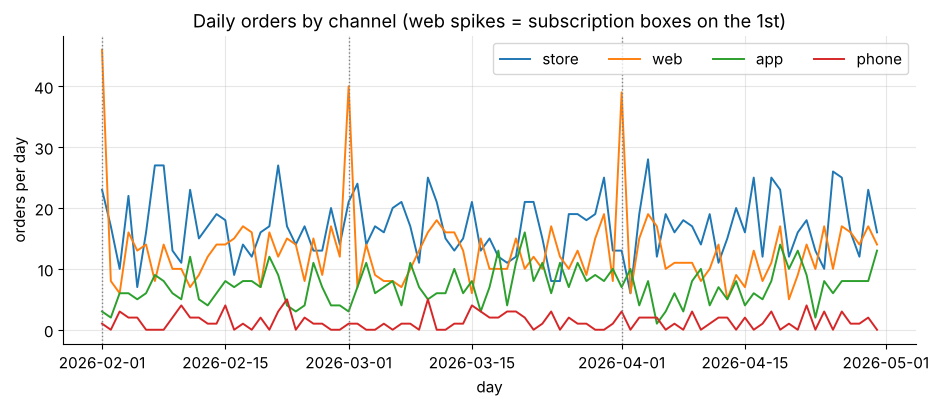

In [58]:
daily = q("""
SELECT date(order_ts) AS day, channel, COUNT(*) AS n_orders
FROM orders
GROUP BY day, channel
""")
wide = daily.pivot(index="day", columns="channel", values="n_orders").fillna(0)
wide.index = pd.to_datetime(wide.index)

fig, ax = plt.subplots(figsize=(11, 4))
for channel in ["store", "web", "app", "phone"]:
    ax.plot(wide.index, wide[channel], label=channel, lw=1.4)
for first in ["2026-02-01", "2026-03-01", "2026-04-01"]:
    ax.axvline(pd.Timestamp(first), color="gray", ls=":", lw=1)
ax.set_xlabel("day")
ax.set_ylabel("orders per day")
ax.set_title("Daily orders by channel (web spikes = subscription boxes on the 1st)")
ax.legend(ncol=4)
plt.show()

The store line also shows a weekly rhythm: busier weekends.

**Quick check 5.** A teammate filters a whole quarter with `WHERE order_ts BETWEEN '2026-02-01' AND '2026-04-30 23:59:59.999'`. Is that safe?

<details>
<summary>Answer</summary>

Not in general. It assumes timestamps never carry more than millisecond precision (DuckDB and PostgreSQL timestamps have **microseconds**, so `23:59:59.9995` would be lost), and in SQLite's text comparison it depends on the exact formatting of the values. `order_ts >= '2026-02-01' AND order_ts < '2026-05-01'` is correct whatever the precision.
</details>

### ✏️ Exercise 9: the last week of March, day by day

Return one row per calendar day from **March 25 to March 31, 2026** (inclusive) with the columns `day` (text `'YYYY-MM-DD'`), `n_orders` and `revenue` (rounded to 2 decimals), sorted by `day`. Use a half-open interval.

In [59]:
# ✏️ Exercise 9: daily orders and revenue, March 25-31
def ex9_sql() -> str:
    """Return a SQL query (as a string) for Exercise 9."""
    # YOUR CODE HERE
    raise NotImplementedError


EX9_EXPECTED = q("""
SELECT date(order_ts) AS day, COUNT(*) AS n_orders, ROUND(SUM(order_total), 2) AS revenue
FROM orders WHERE order_ts >= '2026-03-25' AND order_ts < '2026-04-01'
GROUP BY day ORDER BY day""")


def _diagnose_ex9(got):
    if len(got) == 6:
        return "a day is missing: BETWEEN '2026-03-25' AND '2026-03-31' loses March 31 (after midnight)."
    if len(got) == 8:
        return "April 1 is included, and the end of the interval must be excluded (< '2026-04-01')."
    return None


def _test():
    check_sql(ex9_sql(), EX9_EXPECTED, ordered=True, diagnose=_diagnose_ex9)

run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex9_sql() -> str:
    return """
    SELECT date(order_ts)               AS day,
           COUNT(*)                     AS n_orders,
           ROUND(SUM(order_total), 2)   AS revenue
    FROM orders
    WHERE order_ts >= '2026-03-25' AND order_ts < '2026-04-01'
    GROUP BY day
    ORDER BY day
    """
```
`substr(order_ts, 1, 10)` works as well as `date(order_ts)` because the format is consistent. In DuckDB you would write `CAST(order_ts AS DATE)`. The upper bound `'2026-04-01'` is excluded, so the subscription boxes of April 1 stay out, and the 32 orders of March 31 (including the one at `23:59:59.640`) are in.
</details>

## 7. CTEs, subqueries and window functions

### 7.1 A second dataset: a game studio's in-app purchases

For this section we switch to a small fictional mobile game. `players` has one row per player (grain: player), `purchases` one row per in-app purchase (grain: purchase). Two quirks matter:

- some purchases are **bundles**: two items bought by the same player at the **same timestamp**.
- `purchase_id` increases with time, and is unique, so it can break ties between equal timestamps.

In [60]:
GAME_SCHEMAS = {
    "players":   [("player_id", "text"), ("country", "text"), ("signup_date", "text")],
    "purchases": [("purchase_id", "int"), ("player_id", "text"), ("ts", "timestamp"),
                  ("item", "text"), ("price", "float")],
}


def make_game(seed: int = SEED) -> dict[str, list[tuple]]:
    """Simulate a fictional mobile game's players and in-app purchases (Jan - Mar 2026)."""
    rng = np.random.default_rng(seed + 7)
    catalog = [("coins_small", 0.99), ("starter_pack", 2.99), ("coins_medium", 4.99), ("coins_large", 9.99),
               ("battle_pass", 9.99), ("skin_rare", 14.99), ("skin_legendary", 24.99)]
    item_p = np.array([0.26, 0.12, 0.2, 0.12, 0.14, 0.11, 0.05])
    countries = ["CA", "US", "JP", "BR", "DE", "KR", "IN", "FR"]
    players, events = [], []
    t0 = datetime(2026, 1, 5)
    for k in range(1, 41):
        pid = f"P{k:02d}"
        signup = date(2026, 1, 1) + timedelta(days=int(rng.integers(0, 4)))
        players.append((pid, countries[rng.integers(len(countries))], signup.isoformat()))
        n = 0 if rng.random() < 0.1 else 1 + int(rng.poisson(4.5))
        for _ in range(n):
            ts = t0 + timedelta(seconds=int(rng.integers(0, 84 * 86400)))
            item, price = catalog[rng.choice(len(catalog), p=item_p)]
            events.append((ts, pid, item, price))
    events.append((datetime(2026, 3, 29, 20, 15, 0), "P12", "coins_small", 0.99))     # two late top-ups
    events.append((datetime(2026, 3, 29, 20, 16, 30), "P12", "coins_medium", 4.99))
    with_purchases = sorted({e[1] for e in events})
    for pid in rng.choice(with_purchases, size=4, replace=False):   # bundles: two items at ONE timestamp
        ts = t0 + timedelta(seconds=int(rng.integers(0, 84 * 86400)))
        events.append((ts, str(pid), "battle_pass", 9.99))
        events.append((ts, str(pid), "coins_medium", 4.99))
    events.sort(key=lambda e: (e[0], e[1], e[2]))
    purchases = [(i, pid, ts.strftime("%Y-%m-%d %H:%M:%S"), item, price)
                 for i, (ts, pid, item, price) in enumerate(events, start=1)]
    return {"players": players, "purchases": purchases}


game = make_game()
for name, schema in GAME_SCHEMAS.items():
    load_table(name, schema, game[name])
print({name: len(rows) for name, rows in game.items()})
display(q("SELECT * FROM purchases WHERE player_id = 'P40' ORDER BY ts, purchase_id LIMIT 4"))

{'players': 40, 'purchases': 203}


,purchase_id,player_id,ts,item,price
0,36,P40,2026-01-17 07:51:03,battle_pass,9.99
1,37,P40,2026-01-17 07:51:03,coins_medium,4.99
2,56,P40,2026-01-23 14:26:44,coins_large,9.99
3,101,P40,2026-02-14 23:58:54,coins_small,0.99


Player P40's very first "moment" in the game is a bundle: purchases 36 and 37 share the timestamp `2026-01-17 07:51:03`. Keep an eye on it.

### 7.2 Subqueries and CTEs

A query can contain other queries:

- a **scalar subquery** returns one value and can stand wherever a value can: `WHERE price > (SELECT AVG(price) FROM purchases)`.
- a subquery in **`FROM`** (a *derived table*) is a table like any other, so give it a name (`(…) AS t`), which MySQL, SQL Server and PostgreSQL before version 16 require (SQLite and DuckDB also accept it unnamed, as some queries in Section 8 do).
- a subquery in `WHERE … IN (…)` or `EXISTS (…)` implements semi- and anti-joins (Section 4.3).

A **CTE** (`WITH name AS (subquery)`) names a subquery up front. Several CTEs can be chained, each one using the previous ones, so a long computation reads top to bottom as a sequence of steps, **each with its own grain**:

In [61]:
q("""
WITH spend AS (                        -- step 1, grain: one row per player who bought something
    SELECT player_id, COUNT(*) AS n_purchases, SUM(price) AS total_spend
    FROM purchases
    GROUP BY player_id
),
by_country AS (                        -- step 2, grain: one row per country
    SELECT p.country,
           COUNT(*)                         AS paying_players,
           ROUND(AVG(s.total_spend), 2)     AS avg_spend_per_payer,
           ROUND(SUM(s.total_spend), 2)     AS country_revenue
    FROM spend AS s
    JOIN players AS p ON p.player_id = s.player_id     -- many-to-one: no fan-out
    GROUP BY p.country
)
SELECT *
FROM by_country
WHERE country_revenue > (SELECT AVG(country_revenue) FROM by_country)   -- a scalar subquery
ORDER BY country_revenue DESC
""")

,country,paying_players,avg_spend_per_payer,country_revenue
0,JP,8,46.95,375.56
1,KR,6,44.43,266.60
2,US,4,55.19,220.75


Ordinary (non-recursive) CTEs do not make anything possible that nested subqueries cannot do (`WITH RECURSIVE`, not covered here, is the exception), but they make queries **testable**: you can run `SELECT * FROM spend` on its own and check its grain with the `key_report` idea from Section 1 before building on it.

### 7.3 Window functions: aggregate without collapsing

`GROUP BY` turns each group into **one** row. A **window function** computes a value from a set of related rows (the *window*) but **keeps every row**. The syntax is `function(...) OVER (PARTITION BY ... ORDER BY ... frame)`:

- `PARTITION BY` splits the rows into independent groups (like `GROUP BY`, without collapsing them).
- `ORDER BY` orders the rows inside each partition (needed for rankings, running totals, `LAG`/`LEAD`).
- the optional **frame** (`ROWS BETWEEN … AND …`) says which rows around the current one enter the computation.

Each purchase below keeps its own row, and also sees the player's total and its share of it:

In [62]:
q("""
SELECT player_id, purchase_id, item, price,
       SUM(price) OVER (PARTITION BY player_id)                       AS player_total,
       ROUND(price / SUM(price) OVER (PARTITION BY player_id), 3)     AS share_of_player_total,
       COUNT(*)   OVER (PARTITION BY player_id)                       AS player_purchases
FROM purchases
WHERE player_id IN ('P35', 'P07')
ORDER BY player_id, purchase_id
""")

,player_id,purchase_id,item,price,player_total,share_of_player_total,player_purchases
0,P07,52,coins_small,0.99,35.96,0.028,4
1,P07,58,coins_medium,4.99,35.96,0.139,4
2,P07,60,skin_legendary,24.99,35.96,0.695,4
3,P07,200,coins_medium,4.99,35.96,0.139,4
4,P35,2,coins_medium,4.99,24.96,0.200,4
5,P35,15,battle_pass,9.99,24.96,0.400,4
6,P35,16,coins_medium,4.99,24.96,0.200,4
7,P35,132,coins_medium,4.99,24.96,0.200,4


Window functions are computed in the `SELECT` step of the logical order (Section 2.5): after `WHERE`, `GROUP BY` and `HAVING`, before `ORDER BY`. Consequently **you cannot filter on a window function in `WHERE`**. Compute it in a CTE or subquery and filter outside. (DuckDB adds a `QUALIFY` clause that filters on window functions directly, but SQLite and PostgreSQL do not have it.)

### 7.4 Ranking: `ROW_NUMBER`, `RANK`, `DENSE_RANK`

The three ranking functions differ only in how they treat **ties**. Take the spending of the Japanese players, where P12 and P27 both spent exactly \$61.93:

| spend | `ROW_NUMBER` | `RANK` | `DENSE_RANK` |
|:-:|:-:|:-:|:-:|
| 73.91 | 1 | 1 | 1 |
| 61.93 | 2 | 2 | 2 |
| 61.93 | 3 | 2 | 2 |
| 54.96 | 4 | 4 | 3 |

- `ROW_NUMBER` numbers rows 1, 2, 3, … and **never** ties: tied rows get different numbers in an order the engine chooses.
- `RANK` gives tied rows the same rank and then **skips**: 1, 2, 2, 4. This is "competition ranking": after a two-way tie for second place, the next player is fourth, and nobody is third.
- `DENSE_RANK` gives tied rows the same rank **without gaps**: 1, 2, 2, 3.

In [63]:
q("""
WITH spend AS (
    SELECT p.country, s.player_id, ROUND(SUM(s.price), 2) AS total_spend
    FROM purchases AS s JOIN players AS p ON p.player_id = s.player_id
    GROUP BY p.country, s.player_id
)
SELECT country, player_id, total_spend,
       ROW_NUMBER() OVER (PARTITION BY country ORDER BY total_spend DESC) AS row_number,
       RANK()       OVER (PARTITION BY country ORDER BY total_spend DESC) AS rank,
       DENSE_RANK() OVER (PARTITION BY country ORDER BY total_spend DESC) AS dense_rank
FROM spend
WHERE country = 'JP'
ORDER BY total_spend DESC, player_id
""")

,country,player_id,total_spend,row_number,rank,dense_rank
0,JP,P04,73.91,1,1,1
1,JP,P12,61.93,2,2,2
2,JP,P27,61.93,3,2,2
3,JP,P01,54.96,4,4,3
4,JP,P21,51.94,5,5,4
5,JP,P36,28.96,6,6,5
6,JP,P25,25.96,7,7,6
7,JP,P02,15.97,8,8,7


Which one is right depends on the question. "The top two spenders per country, ties included" is `RANK() <= 2`, and "one row per country, no matter what" is `ROW_NUMBER() = 1` *plus a tie-breaker that you choose on purpose*. Note also that we rank on the **rounded** spend: money stored as binary floating point can make two equal sums differ in the 15th digit, which would silently break a tie. Production systems store money as integer cents or `DECIMAL`.

### 7.5 Running totals and the frame clause

With an `ORDER BY` inside `OVER`, `SUM` becomes a **running total**. The frame decides exactly which rows are summed, and the default frame contains a surprise. When `ORDER BY` is present and no frame is written, the standard default is `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`, and `RANGE` treats all rows with the **same `ORDER BY` value** (called *peers*) as one block. For P04's bundle (two purchases at the same second) the two frames disagree:

In [64]:
running_sql = """
SELECT player_id, purchase_id, ts, price,
       SUM(price) OVER (PARTITION BY player_id ORDER BY ts)                         AS default_frame,
       SUM(price) OVER (PARTITION BY player_id ORDER BY ts, purchase_id
                        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)           AS rows_frame
FROM purchases
WHERE player_id = 'P04'
ORDER BY ts, purchase_id
LIMIT 4
"""
display(q(running_sql))
_ = both(running_sql)

,player_id,purchase_id,ts,price,default_frame,rows_frame
0,P04,17,2026-01-11 12:18:35,9.99,9.99,9.99
1,P04,33,2026-01-16 23:53:29,9.99,24.97,19.98
2,P04,34,2026-01-16 23:53:29,4.99,24.97,24.97
3,P04,86,2026-02-09 06:48:40,14.99,39.96,39.96


SQLite and DuckDB agree.


On purchase 33 the default frame already includes its peer, purchase 34 (\$19.98 + \$4.99 = \$24.97), as if both items had been bought "before" each other. A `ROWS` frame with a **total** order (`ts, purchase_id`) gives a proper row-by-row running total. Use the explicit frame whenever the running total feeds a decision, like "the moment a player crosses \$50" in Exercise 12.

### 7.6 `LAG` and `LEAD`: looking at neighboring rows

`LAG(x)` returns `x` from the **previous** row of the partition (in the window's order), `LEAD(x)` from the next one, and the first (last) row gets `NULL`. A classic use is the time between consecutive events. SQLite's `julianday()` converts a timestamp to a (fractional) day number, so a difference of two `julianday` values is a duration in days:

,player_id,purchase_id,ts,previous_ts,days_since_previous
165,P35,2,2026-01-05 16:19:46,None,NaN
166,P35,15,2026-01-11 09:59:39,2026-01-05 16:19:46,5.74
167,P35,16,2026-01-11 09:59:39,2026-01-11 09:59:39,0.00
168,P35,132,2026-02-28 23:29:24,2026-01-11 09:59:39,48.56


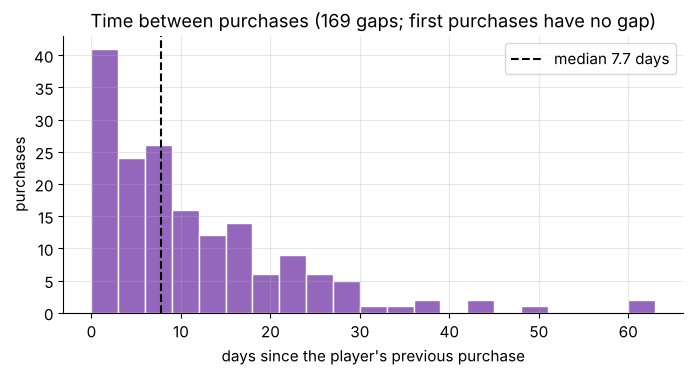

In [65]:
gaps = q("""
SELECT player_id, purchase_id, ts,
       LAG(ts) OVER (PARTITION BY player_id ORDER BY ts, purchase_id) AS previous_ts,
       ROUND(julianday(ts)
             - julianday(LAG(ts) OVER (PARTITION BY player_id ORDER BY ts, purchase_id)), 2) AS days_since_previous
FROM purchases
""")
display(gaps[gaps.player_id == "P35"])
gap_days = gaps.days_since_previous.dropna()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(gap_days, bins=np.arange(0, 66, 3), color="tab:purple", edgecolor="white")
ax.axvline(gap_days.median(), color="black", ls="--", label=f"median {gap_days.median():.1f} days")
ax.set_xlabel("days since the player's previous purchase")
ax.set_ylabel("purchases")
ax.set_title(f"Time between purchases ({len(gap_days)} gaps, first purchases have no gap)")
ax.legend()
plt.show()

Bundles produce gaps of exactly 0 days. The 34 first purchases have `NULL` gaps, which `dropna()` removes: 203 purchases − 34 first purchases = 169 gaps.

### 7.7 Deterministic tie-breaking

"Each player's **first** purchase" is a one-row-per-group question, the job of `ROW_NUMBER() … = 1`. With `ORDER BY ts` alone, P40's bundle makes the request ambiguous: two rows share the earliest timestamp. Which one gets row number 1 is up to the engine, and it can change when the same data is stored in a different physical order. To show this, we load the very same purchases into a second SQLite database in **reverse** insertion order:

In [66]:
db_shuffled = sqlite3.connect(":memory:")          # same rows, different physical order
load_table("players", GAME_SCHEMAS["players"], game["players"][::-1], cons=[db_shuffled])
load_table("purchases", GAME_SCHEMAS["purchases"], game["purchases"][::-1], cons=[db_shuffled])

FIRST_SQL = """
WITH ranked AS (
    SELECT player_id, purchase_id, ts, item,
           ROW_NUMBER() OVER (PARTITION BY player_id ORDER BY {order}) AS rn
    FROM purchases
)
SELECT player_id, purchase_id, ts, item FROM ranked WHERE rn = 1 AND player_id = 'P40'
"""
for order in ["ts", "ts, purchase_id"]:
    for con, label in [(db, "original order"), (db_shuffled, "reversed order")]:
        r = q(FIRST_SQL.format(order=order), con).iloc[0]
        print(f"ORDER BY {order:<17} {label:<15} -> purchase {r['purchase_id']} ({r['item']})")

ORDER BY ts                original order  -> purchase 36 (battle_pass)
ORDER BY ts                reversed order  -> purchase 37 (coins_medium)
ORDER BY ts, purchase_id   original order  -> purchase 36 (battle_pass)
ORDER BY ts, purchase_id   reversed order  -> purchase 36 (battle_pass)


With `ORDER BY ts` the "first purchase" of P40 flips from the battle pass to the coins when only the storage order changes: same data, same query, different answer. Adding the unique `purchase_id` as the last sort key makes the order **total** (no two rows can tie), so the answer is the same everywhere.

> **Key idea.** Whenever you pick one row per group (`ROW_NUMBER() = 1`, `LIMIT 1`, "latest record", "first event"), the `ORDER BY` must end with a column (or set of columns) that is **unique** within the group. Otherwise the result is not a function of the data.

DuckDB's `QUALIFY` makes the pattern shorter (the tie-breaker is still your job):

In [67]:
q("""
SELECT player_id, purchase_id, ts, item
FROM purchases
QUALIFY ROW_NUMBER() OVER (PARTITION BY player_id ORDER BY ts, purchase_id) = 1
ORDER BY player_id
LIMIT 5
""", duck)

,player_id,purchase_id,ts,item
0,P01,25,2026-01-14 09:06:53,coins_large
1,P02,32,2026-01-16 20:35:47,coins_small
2,P03,8,2026-01-07 17:54:11,coins_medium
3,P04,17,2026-01-11 12:18:35,battle_pass
4,P07,52,2026-01-22 19:17:00,coins_small


**Quick check 6.** Why does `SELECT player_id, ROW_NUMBER() OVER (ORDER BY ts) AS rn FROM purchases WHERE rn = 1` fail?

<details>
<summary>Answer</summary>

`WHERE` is evaluated before the `SELECT` step in which window functions (and their aliases) are computed, so `rn` does not exist yet when `WHERE` runs. SQLite reports "misuse of aliased window function rn", DuckDB "WHERE clause cannot contain window functions". Compute `rn` in a CTE or subquery and filter outside it, or use `QUALIFY` in DuckDB.
</details>

### ✏️ Exercise 10: the podium, ties included

For each country, return the players whose total spend ranks **first or second** in their country, where tied players share a rank (so a tie can put three players on the "top two"). Columns: `country`, `player_id`, `total_spend` (rounded to 2 decimals). Sort by `country`, then `total_spend` from highest to lowest, then `player_id`.

In [68]:
# ✏️ Exercise 10: top two spenders per country, ties included
def ex10_sql() -> str:
    """Return a SQL query (as a string) for Exercise 10."""
    # YOUR CODE HERE
    raise NotImplementedError


EX10_EXPECTED = q("""
WITH spend AS (
    SELECT p.country, s.player_id, ROUND(SUM(s.price), 2) AS total_spend
    FROM purchases AS s JOIN players AS p ON p.player_id = s.player_id
    GROUP BY p.country, s.player_id),
ranked AS (SELECT *, RANK() OVER (PARTITION BY country ORDER BY total_spend DESC) AS rnk FROM spend)
SELECT country, player_id, total_spend FROM ranked WHERE rnk <= 2
ORDER BY country, total_spend DESC, player_id""")


def _diagnose_ex10(got):
    if len(got) == len(EX10_EXPECTED) - 1:
        return "one row is missing: ROW_NUMBER breaks the tie in Japan arbitrarily. Use a ranking that keeps ties."
    return None


def _test():
    check_sql(ex10_sql(), EX10_EXPECTED, ordered=True, diagnose=_diagnose_ex10)

run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex10_sql() -> str:
    return """
    WITH spend AS (
        SELECT p.country, s.player_id, ROUND(SUM(s.price), 2) AS total_spend
        FROM purchases AS s
        JOIN players AS p ON p.player_id = s.player_id
        GROUP BY p.country, s.player_id
    ),
    ranked AS (
        SELECT *, RANK() OVER (PARTITION BY country ORDER BY total_spend DESC) AS rnk
        FROM spend
    )
    SELECT country, player_id, total_spend
    FROM ranked
    WHERE rnk <= 2
    ORDER BY country, total_spend DESC, player_id
    """
```
16 rows: two per country, except India (only one paying player) and Japan (P12 and P27 tie for second place). `DENSE_RANK() <= 2` gives the same rows here, but the two differ only after a tie for first place (with `RANK`, a two-way tie for first leaves nobody in second place). `ROW_NUMBER() <= 2` silently drops one of the tied players.
</details>

### ✏️ Exercise 11: each player's first purchase, deterministically

Return each paying player's **first** purchase: `player_id`, `purchase_id`, `ts`, `item`, sorted by `player_id`. If several purchases share the earliest timestamp, take the one with the **smallest `purchase_id`**. The checker runs your query on the original database **and** on `db_shuffled` (same rows, reversed storage order), and both must give the expected answer.

In [69]:
# ✏️ Exercise 11: first purchase per player, with a deterministic tie-breaker
def ex11_sql() -> str:
    """Return a SQL query (as a string) for Exercise 11."""
    # YOUR CODE HERE
    raise NotImplementedError


EX11_EXPECTED = q("""
WITH ranked AS (SELECT player_id, purchase_id, ts, item,
                       ROW_NUMBER() OVER (PARTITION BY player_id ORDER BY ts, purchase_id) AS rn
                FROM purchases)
SELECT player_id, purchase_id, ts, item FROM ranked WHERE rn = 1 ORDER BY player_id""")


def _diagnose_ex11(got):
    if len(got) > len(EX11_EXPECTED):
        return "more than one row per player: did you use RANK (which keeps ties) instead of ROW_NUMBER?"
    return "the answer depends on how the rows are stored: the ORDER BY needs a unique tie-breaker."


def _test():
    sql = ex11_sql()
    check_sql(sql, EX11_EXPECTED, ordered=True, diagnose=_diagnose_ex11)
    check_sql(sql, EX11_EXPECTED, ordered=True, diagnose=_diagnose_ex11, con=db_shuffled)

run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex11_sql() -> str:
    return """
    WITH ranked AS (
        SELECT player_id, purchase_id, ts, item,
               ROW_NUMBER() OVER (PARTITION BY player_id
                                  ORDER BY ts, purchase_id) AS rn
        FROM purchases
    )
    SELECT player_id, purchase_id, ts, item
    FROM ranked
    WHERE rn = 1
    ORDER BY player_id
    """
```
With `ORDER BY ts` alone, the query passes on one database and fails on the other: P40's first purchase depends on the storage order. A `GROUP BY player_id` with `MIN(ts)` finds the right *timestamp*, but joining back to `purchases` on `(player_id, ts)` returns **both** bundle rows for P40, so it still needs a tie-breaker.
</details>

### ✏️ Exercise 12: crossing \$50

For each player, find the purchase at which their **cumulative** spend (in time order, ties broken by `purchase_id`) first reaches **at least \$50**. Return `player_id`, `purchase_id`, `ts` and `cum_spend` (the cumulative spend including that purchase, rounded to 2 decimals), sorted by `player_id`. Players who never reach \$50 do not appear. This check also runs on both databases, and on a tiny extra dataset, again stored in both orders, in which a bundle straddles \$50.

In [70]:
# ✏️ Exercise 12: the purchase at which each player's cumulative spend reaches $50
def ex12_sql() -> str:
    """Return a SQL query (as a string) for Exercise 12."""
    # YOUR CODE HERE
    raise NotImplementedError


EX12_EXPECTED = q("""
WITH running AS (
    SELECT player_id, purchase_id, ts,
           SUM(price) OVER (PARTITION BY player_id ORDER BY ts, purchase_id
                            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cum_spend
    FROM purchases),
crossed AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY player_id ORDER BY ts, purchase_id) AS rn
    FROM running WHERE cum_spend >= 50)
SELECT player_id, purchase_id, ts, ROUND(cum_spend, 2) AS cum_spend FROM crossed WHERE rn = 1
ORDER BY player_id""")


def _diagnose_ex12(got):
    if len(got) > len(EX12_EXPECTED):
        return "several rows per player: keep only the FIRST purchase with cum_spend >= 50."
    return None


def _edge_db(stored_rows):
    """A tiny SQLite database with one player, Z1, whose $50 crossing falls inside a bundle."""
    con = sqlite3.connect(":memory:")
    load_table("players", GAME_SCHEMAS["players"], [("Z1", "CA", "2026-01-01")], cons=[con])
    load_table("purchases", GAME_SCHEMAS["purchases"], stored_rows, cons=[con])
    return con


EX12_EDGE_ROWS = [(1, "Z1", "2026-01-01 10:00:00", "skin_legendary", 24.99),
                  (2, "Z1", "2026-01-02 10:00:00", "skin_legendary", 24.99),
                  (3, "Z1", "2026-01-03 10:00:00", "coins_small", 0.99),      # purchases 3 and 4: a bundle
                  (4, "Z1", "2026-01-03 10:00:00", "battle_pass", 9.99)]
EX12_EDGE_DBS = [_edge_db(EX12_EDGE_ROWS), _edge_db(EX12_EDGE_ROWS[::-1])]   # both storage orders
EX12_EDGE_EXPECTED = pd.DataFrame({"player_id": ["Z1"], "purchase_id": [3],
                                   "ts": ["2026-01-03 10:00:00"], "cum_spend": [50.97]})


def _diagnose_ex12_edge(got):
    return ("in the extra test, purchases 3 and 4 form a bundle (same ts) that straddles $50: "
            "use ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW and ORDER BY ts, purchase_id.")


def _test():
    sql = ex12_sql()
    check_sql(sql, EX12_EXPECTED, ordered=True, diagnose=_diagnose_ex12)
    check_sql(sql, EX12_EXPECTED, ordered=True, diagnose=_diagnose_ex12, con=db_shuffled)
    for edge_db in EX12_EDGE_DBS:
        check_sql(sql, EX12_EDGE_EXPECTED, ordered=True, con=edge_db, diagnose=_diagnose_ex12_edge)

run_check("Exercise 12", _test)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex12_sql() -> str:
    return """
    WITH running AS (
        SELECT player_id, purchase_id, ts,
               SUM(price) OVER (PARTITION BY player_id
                                ORDER BY ts, purchase_id
                                ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cum_spend
        FROM purchases
    ),
    crossed AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY player_id
                                     ORDER BY ts, purchase_id) AS rn
        FROM running
        WHERE cum_spend >= 50
    )
    SELECT player_id, purchase_id, ts, ROUND(cum_spend, 2) AS cum_spend
    FROM crossed
    WHERE rn = 1
    ORDER BY player_id
    """
```
12 players cross \$50. The running total is computed in one CTE and filtered in the next, because a window function cannot appear in `WHERE`. Since the running total never decreases, "the first row with `cum_spend >= 50`" is well defined once the order is total. The extra dataset shows why both parts of the window matter: player Z1 has spent \$49.98 before a bundle of \$0.99 and \$9.99, so the answer is purchase 3 at \$50.97, but the default `RANGE` frame gives both rows of the bundle \$60.96, and an `ORDER BY ts` without the tie-breaker can put purchase 4 first (\$59.97). Because prices are floats, a comparison like `cum_spend >= 50` can misjudge a sum that should be exactly 50.00 by a tiny rounding error, but with money stored as integer cents that cannot happen.
</details>

## 8. Safe data cleaning

### 8.1 A messy export: ad campaigns for five fictional brands

A marketing agency runs online ad campaigns for five fictional brands (Kestrel Bikes, Brightleaf Tea, Orbit Snacks, Tidepool Swim, Juniper Lane Candles). Each campaign has a funnel of metrics: **impressions** (the ad was shown), **clicks**, **leads** (a form was filled in) and **conversions** (a purchase), plus the `revenue` it generated and the `spend` it cost. The ad platform exported the data **twice**, a week apart, and we must build a clean table with **one row per campaign** (the grain!) for a model that predicts conversions.

The raw table `campaigns_raw` has one row per *exported record*, with a technical `row_id` and the time `loaded_at` of the export. Real exports contain every defect below, and so does ours:

- campaign ids and brand names with inconsistent **case** and stray **whitespace** (including a tab and a non-breaking space),
- **missing metrics** (`NULL`),
- **funnel violations**: more clicks than impressions, or more conversions than leads, which is impossible,
- **negative** money values,
- **invalid dates** like `2026-02-30`, `2026/03/05` or `N/A`,
- **duplicates**: campaigns present in both exports, sometimes identical, sometimes **corrected** in the second export, and sometimes **broken in one export but valid in the other**.

In [71]:
CAMPAIGN_SCHEMA = [("row_id", "int"), ("campaign_id", "text"), ("brand", "text"), ("channel", "text"),
                   ("start_date", "text"), ("impressions", "int"), ("clicks", "int"), ("leads", "int"),
                   ("conversions", "int"), ("revenue", "float"), ("spend", "float"), ("loaded_at", "timestamp")]
BRANDS = [("KB", "Kestrel Bikes"), ("BT", "Brightleaf Tea"), ("OS", "Orbit Snacks"),
          ("TS", "Tidepool Swim"), ("JL", "Juniper Lane Candles")]


def campaign_truth(rng) -> list[dict]:
    """The true state of 200 campaigns (40 per brand), with a consistent funnel."""
    truth = []
    for code, name in BRANDS:
        for num in sorted(rng.choice(np.arange(1, 1000), size=40, replace=False)):
            imp = int(rng.lognormal(10.2, 0.5))
            clicks = int(imp * rng.uniform(0.01, 0.06))
            leads = int(clicks * rng.uniform(0.08, 0.30))
            conv = int(leads * rng.uniform(0.10, 0.50))
            truth.append({"campaign_id": f"{code}-{num:04d}", "brand": name,
                          "channel": ["search", "social", "video", "email"][rng.integers(4)],
                          "start_date": (date(2026, 1, 1) + timedelta(days=int(rng.integers(0, 90)))).isoformat(),
                          "impressions": imp, "clicks": clicks, "leads": leads, "conversions": conv,
                          "revenue": round(conv * float(rng.uniform(20, 80)), 2),
                          "spend": round(imp / 1000 * float(rng.uniform(3, 12)), 2)})
    return truth


def messy_text(rng, text: str) -> str:
    """Randomly flip the case of a text and pad it with spaces, like a careless export."""
    if rng.random() < 0.15:
        text = text.lower() if text[:2].isupper() else text.upper()
    if rng.random() < 0.25:
        text = " " * int(rng.integers(1, 3)) + text
    if rng.random() < 0.25:
        text = text + " " * int(rng.integers(1, 3))
    return text

In [72]:
def make_campaigns(seed: int = SEED) -> tuple[list[tuple], dict[str, list[str]]]:
    """Two exports of the campaigns with planted defects. Returns (rows, {defect kind: campaign ids})."""
    rng = np.random.default_rng(seed + 11)
    truth = campaign_truth(rng)
    ids = rng.permutation(len(truth))
    groups = {"identical duplicate": ids[0:16], "corrected in 2nd export": ids[16:26],
              "broken in 1st export only": ids[26:34], "broken in 2nd export only": ids[34:40],
              "missing metric": ids[40:46], "funnel violation": ids[46:52],
              "negative spend": ids[52:56], "invalid date": ids[56:61]}
    batch1, batch2 = [], []
    for i, rec in enumerate(truth):
        r1 = dict(rec)
        if i in groups["broken in 1st export only"]:        # truncated impressions: clicks > impressions
            r1["impressions"] = rec["clicks"] // 3
        elif i in groups["missing metric"]:
            r1[["impressions", "clicks", "leads", "conversions"][int(rng.integers(4))]] = None
        elif i in groups["funnel violation"]:
            r1["conversions"] = rec["leads"] + int(rng.integers(1, 20))
        elif i in groups["negative spend"]:
            r1["spend"] = -rec["spend"]
        elif i in groups["invalid date"]:
            k = list(groups["invalid date"]).index(i)
            r1["start_date"] = ["2026-02-30", "2026/03/05", "N/A", "", "2026-13-01"][k]
        batch1.append(r1)
        if i in groups["identical duplicate"] or i in groups["broken in 1st export only"]:
            batch2.append(dict(rec))
        elif i in groups["corrected in 2nd export"]:
            batch2.append(dict(rec, revenue=round(rec["revenue"] * float(rng.uniform(1.05, 1.3)), 2)))
        elif i in groups["broken in 2nd export only"]:
            k = list(groups["broken in 2nd export only"]).index(i)
            batch2.append(dict(rec, revenue=-rec["revenue"]) if k < 4 else dict(rec, start_date="2026-02-30"))
    batch1 = [batch1[j] for j in rng.permutation(len(batch1))]
    batch2 = [batch2[j] for j in rng.permutation(len(batch2))]
    rows = []
    for batch, loaded_at in [(batch1, "2026-04-02 06:00:00"), (batch2, "2026-04-09 06:00:00")]:
        for rec in batch:
            rows.append([len(rows) + 1, messy_text(rng, rec["campaign_id"]), messy_text(rng, rec["brand"]),
                         rec["channel"], rec["start_date"], rec["impressions"], rec["clicks"], rec["leads"],
                         rec["conversions"], rec["revenue"], rec["spend"], loaded_at])
    dup_ids = {truth[i]["campaign_id"] for i in groups["identical duplicate"]}
    sneaky = [r for r in rows if r[11].startswith("2026-04-09") and r[1].strip().upper() in dup_ids][:3]
    for r, junk in zip(sneaky, ["\t", "\xa0", "\t"]):     # whitespace that a plain TRIM() keeps
        r[1] = r[1].strip() + junk
    planted = {kind: sorted(truth[i]["campaign_id"] for i in idx) for kind, idx in groups.items()}
    return [tuple(r) for r in rows], planted


campaign_rows, planted = make_campaigns()
load_table("campaigns_raw", CAMPAIGN_SCHEMA, campaign_rows)
load_table("campaigns_raw", CAMPAIGN_SCHEMA, campaign_rows[::-1], cons=[db_shuffled])   # reversed storage order
print(f"{len(campaign_rows)} raw rows, plus planted defects (used only to grade our cleaning at the end):")
print({kind: len(ids) for kind, ids in planted.items()})

240 raw rows; planted defects (used only to grade our cleaning at the end):
{'identical duplicate': 16, 'corrected in 2nd export': 10, 'broken in 1st export only': 8, 'broken in 2nd export only': 6, 'missing metric': 6, 'funnel violation': 6, 'negative spend': 4, 'invalid date': 5}


`planted` is the simulator's answer key: which campaigns received which defect. A real pipeline never has one, so we use it only to **grade** our cleaning, never to perform it. Here is a sample of raw records. Note `2026-02-30`, the funnel violation in row 4 (390 impressions but 1172 clicks) and the upper-cased brand name:

In [73]:
show(q("SELECT * FROM campaigns_raw ORDER BY row_id"), max_rows=6)

,row_id,campaign_id,brand,channel,start_date,impressions,clicks,leads,conversions,revenue,spend,loaded_at
0,1,BT-0248,Brightleaf Tea,social,2026-02-06,17061,669,137,53,2587.87,120.88,2026-04-02 06:00:00
1,2,BT-0224,Brightleaf Tea,video,2026-02-30,13339,533,123,51,1828.00,117.32,2026-04-02 06:00:00
2,3,JL-0173,Juniper Lane Candles,video,2026-01-25,21207,474,123,16,620.34,75.83,2026-04-02 06:00:00
3,4,BT-0509,Brightleaf Tea,email,2026-02-07,390,1172,150,23,1751.83,420.19,2026-04-02 06:00:00
4,5,JL-0684,JUNIPER LANE CANDLES,social,2026-03-21,40761,2083,461,140,3385.48,151.51,2026-04-02 06:00:00
5,6,OS-0454,Orbit Snacks,email,2026-02-04,24229,973,272,99,7918.52,91.16,2026-04-02 06:00:00


... 234 more rows (total 240)


### 8.2 Step 1: normalize text with `TRIM`, `UPPER`, and invisible characters

Grouping and joining compare strings **exactly**: `'KB-0127'`, `'kb-0127'` and `' KB-0127 '` are three different keys. Normalization maps every spelling of the same thing to one canonical form, here upper case without surrounding whitespace. How many distinct campaigns does the export contain?

In [74]:
WS = " \t\n\r\xa0"   # space, tab, newline, carriage return, non-breaking space
norm_sql = """
SELECT COUNT(*)                                     AS n_rows,
       COUNT(DISTINCT campaign_id)                  AS raw_ids,
       COUNT(DISTINCT UPPER(TRIM(campaign_id)))     AS trim_upper_ids,
       COUNT(DISTINCT UPPER(TRIM(campaign_id, ?)))  AS trim_all_whitespace_ids
FROM campaigns_raw
"""
for con in (db, duck):
    print(f"{engine_name(con):>6}:", q(norm_sql, con, params=[WS]).iloc[0].to_dict())
print("ids that still contain whitespace after TRIM():",
      q("SELECT DISTINCT TRIM(campaign_id) AS id FROM campaigns_raw WHERE TRIM(campaign_id) <> TRIM(campaign_id, ?)",
        params=[WS]).id.map(repr).tolist())

SQLite: {'n_rows': 240, 'raw_ids': 232, 'trim_upper_ids': 203, 'trim_all_whitespace_ids': 200}
DuckDB: {'n_rows': 240, 'raw_ids': 232, 'trim_upper_ids': 202, 'trim_all_whitespace_ids': 200}
ids that still contain whitespace after TRIM(): ["'JL-0817\\t'", "'kb-0127\\xa0'", "'OS-0474\\t'"]


The raw column has 232 distinct values for what should be 200 campaigns. `UPPER(TRIM(…))` brings it down to 203 in SQLite, but **not** to 200: by default, `TRIM` removes only the ordinary space character. Two ids end with a tab (`\t`) and one with a non-breaking space (`\xa0`, common in data copied from web pages and spreadsheets). They look identical on screen, and they are different keys. DuckDB's default `TRIM` happens to remove the non-breaking space but not the tab (202), and Python's `str.strip()` removes both. Passing the full set of whitespace characters as the second argument of `TRIM` (supported by both engines) gives the right 200.

> **Common pitfall.** "The same" cleaning function differs between engines and languages: `TRIM` in SQLite, `TRIM` in DuckDB and `str.strip` in Python remove different characters. After normalizing, **count distinct keys** and check the number against what you expect, and look for leftovers with a query like the one above.

Upper case is a convention, and `LOWER` works just as well. What matters is to pick **one** canonical form and apply it everywhere the key is used, in particular on **both sides of every join**: a join between a normalized and a raw column silently loses the rows whose spelling differs.

Brand names get the same treatment. In the next steps we work on a normalized view of the raw table. A **view** is a stored query: it has no data of its own, and every query that reads it reruns its `SELECT`. We create it in both engines. The whitespace set is spelled with `char()` in SQLite and `chr()` in DuckDB:

In [75]:
def create_normalized_view(con) -> None:
    """campaigns_norm: campaigns_raw with canonical campaign ids and brand names (no rows removed)."""
    ch = "char" if isinstance(con, sqlite3.Connection) else "chr"
    ws = f"' ' || {ch}(9) || {ch}(10) || {ch}(13) || {ch}(160)"
    con.execute("DROP VIEW IF EXISTS campaigns_norm")
    con.execute(f"""
        CREATE VIEW campaigns_norm AS
        SELECT row_id,
               UPPER(TRIM(campaign_id, {ws})) AS campaign_id,
               UPPER(TRIM(brand, {ws}))       AS brand,
               channel, start_date, impressions, clicks, leads, conversions, revenue, spend, loaded_at
        FROM campaigns_raw""")


for con in (db, duck, db_shuffled):
    create_normalized_view(con)
display(q("SELECT brand, COUNT(*) AS n_rows, COUNT(DISTINCT campaign_id) AS n_campaigns FROM campaigns_norm GROUP BY brand ORDER BY brand"))
print("distinct raw brand spellings:", q("SELECT COUNT(DISTINCT brand) AS n FROM campaigns_raw").n[0])

,brand,n_rows,n_campaigns
0,BRIGHTLEAF TEA,49,40
1,JUNIPER LANE CANDLES,47,40
2,KESTREL BIKES,51,40
3,ORBIT SNACKS,49,40
4,TIDEPOOL SWIM,44,40


distinct raw brand spellings: 51


### 8.3 Steps 2–5: row-level validity rules

The next four steps each remove rows that break a **business rule**. Each rule is a condition on a single row:

| step | rule (a row is valid if...) | SQL condition |
|---|---|---|
| 2. complete | no metric is missing | `impressions IS NOT NULL AND clicks IS NOT NULL AND ...` (all six) |
| 3. funnel | each stage is at most the previous one | `impressions >= clicks AND clicks >= leads AND leads >= conversions` |
| 4. non-negative | no count or amount is negative | `impressions >= 0 AND ... AND revenue >= 0 AND spend >= 0` |
| 5. valid date | `start_date` is a real calendar date in `YYYY-MM-DD` format | see below |

The funnel rule encodes domain knowledge: a click requires an impression, a lead requires a click, a conversion requires a lead. Data that break it are not "unusual". They are **impossible**, so they come from a bug (here, a truncated number in the first export).

Date validation is where engines differ the most. SQLite's `date()` returns `NULL` for unparseable text, but it silently **normalizes** impossible days: `date('2026-02-30')` is `'2026-03-02'`. So the robust SQLite test is a round trip, `date(start_date) = start_date`. DuckDB's `TRY_CAST(... AS DATE)` returns `NULL` on failure, but it accepts other separators such as `2026/03/05`. `TRY_STRPTIME(start_date, '%Y-%m-%d')` rejects other separators and impossible days, but it still accepts unpadded or short numbers (`2026-3-5`, even `26-03-05` as the year 26) and surrounding spaces. Add `regexp_full_match(start_date, '\d{4}-\d{2}-\d{2}')` when the exact format matters, as our DuckDB pipeline in Section 8.7 does.

In [76]:
date_tests = ["2026-03-05", "2026-02-30", "2026/03/05", "2026-13-01", "N/A", ""]
rows = []
for s in date_tests:
    sqlite_date = q("SELECT date(?) AS d", params=[s]).d[0]
    rows.append({"text": repr(s),
                 "SQLite date(x)": sqlite_date,
                 "SQLite valid: date(x) = x": sqlite_date == s,
                 "DuckDB TRY_CAST(x AS DATE)": q("SELECT CAST(TRY_CAST(? AS DATE) AS VARCHAR) AS d", duck, params=[s]).d[0],
                 "DuckDB valid: TRY_STRPTIME(x, '%Y-%m-%d')": q("SELECT TRY_STRPTIME(?, '%Y-%m-%d') IS NOT NULL AS ok",
                                                               duck, params=[s]).ok[0]})
pd.DataFrame(rows)

,text,SQLite date(x),SQLite valid: date(x) = x,DuckDB TRY_CAST(x AS DATE),"DuckDB valid: TRY_STRPTIME(x, '%Y-%m-%d')"
0,'2026-03-05',2026-03-05,True,2026-03-05,True
1,'2026-02-30',2026-03-02,False,None,False
2,'2026/03/05',None,False,2026-03-05,False
3,'2026-13-01',None,False,None,False
4,'N/A',None,False,None,False
5,'',None,False,None,False


Now we apply the four rules one after the other and record how many rows each step removes:

In [77]:
RULES = {   # SQLite conditions: a row is kept when the condition is TRUE
    "2. complete":     "impressions IS NOT NULL AND clicks IS NOT NULL AND leads IS NOT NULL "
                       "AND conversions IS NOT NULL AND revenue IS NOT NULL AND spend IS NOT NULL",
    "3. funnel":       "impressions >= clicks AND clicks >= leads AND leads >= conversions",
    "4. non-negative": "impressions >= 0 AND clicks >= 0 AND leads >= 0 AND conversions >= 0 "
                       "AND revenue >= 0 AND spend >= 0",
    "5. valid date":   "date(start_date) = start_date",
}


def apply_rules(rule_names, con=None) -> list[int]:
    """Row counts of campaigns_norm before the first rule and after each rule, applied in the given order."""
    counts, cond = [], "1 = 1"
    counts.append(q(f"SELECT COUNT(*) AS n FROM campaigns_norm WHERE {cond}", con).n[0])
    for name in rule_names:
        cond += f" AND ({RULES[name]})"
        counts.append(q(f"SELECT COUNT(*) AS n FROM campaigns_norm WHERE {cond}", con).n[0])
    return counts


counts = apply_rules(list(RULES))
steps = pd.DataFrame({"step": list(RULES), "rows before": counts[:-1], "removed": np.diff(counts) * -1,
                      "rows after": counts[1:]})
steps

,step,rows before,removed,rows after
0,2. complete,240,6,234
1,3. funnel,234,14,220
2,4. non-negative,220,8,212
3,5. valid date,212,7,205


205 of the 240 rows satisfy all four rules. Before we deduplicate them, two subtleties.

**Keep the good rows, or delete the bad ones?** In SQL these are *not* the same when `NULL`s are present. `WHERE impressions >= clicks` keeps a row only if the comparison is **true**, so a row with a `NULL` click count is dropped. The "same" rule written as a deletion, `DELETE FROM … WHERE clicks > impressions`, deletes a row only if *its* condition is true, so the row with the `NULL` survives:

In [78]:
keep_good = q("SELECT COUNT(*) AS n FROM campaigns_norm WHERE impressions >= clicks AND clicks >= leads AND leads >= conversions").n[0]
not_bad = q("SELECT COUNT(*) AS n FROM campaigns_norm WHERE NOT (clicks > impressions OR leads > clicks OR conversions > leads)").n[0]
delete_bad = 240 - q("SELECT COUNT(*) AS n FROM campaigns_norm WHERE clicks > impressions OR leads > clicks OR conversions > leads").n[0]
print(f"keep rows where the funnel holds        : {keep_good}")
print(f"keep rows where NOT (funnel is broken)  : {not_bad}")
print(f"delete rows where the funnel is broken  : {delete_bad} rows survive")

keep rows where the funnel holds        : 220
keep rows where NOT (funnel is broken)  : 220
delete rows where the funnel is broken  : 226 rows survive


`NOT (unknown)` is still unknown, so the second form also drops the six incomplete rows. Only the `DELETE` form lets them through.

Does a pipeline of `DELETE` statements therefore depend on the order of its steps? No. Each `DELETE` is still a row filter: it keeps exactly the rows on which its condition is *not true* (false **or unknown**), so a sequence of `DELETE`s gives the same result in any order, like the filters of Section 8.4. What the `DELETE` style needs is **explicit `NULL` handling**. The completeness step must be part of the pipeline (at any position), because no other `DELETE` removes the incomplete rows. And a condition can be unknown even on a row with no missing value: `date()` returns `NULL` for `'2026/03/05'`, `'2026-13-01'`, `'N/A'` and `''` (see the date table above), so `DELETE … WHERE date(start_date) <> start_date` is unknown on exactly these four invalid dates and keeps all of them.

A safe deletion negates the "keep" condition explicitly: `DELETE … WHERE (date(start_date) = start_date) IS NOT TRUE` removes every row on which the test is false *or* unknown. (The `NULL`-safe `date(start_date) IS NOT start_date` of Section 2.4 also removes these four, but it would keep a row whose `start_date` is itself `NULL`, because `NULL IS NOT NULL` is false.) Writing every rule as "keep where valid" avoids the problem altogether: `WHERE` drops a row whose condition is unknown automatically.

### 8.4 Why row filters commute, and deduplication does not

A **row filter** $\sigma_p$ keeps the rows $r$ of a table $T$ for which the condition $p(r)$ is true. Whether a row survives depends **only on that row**. Therefore, for two filters,

$$
\sigma_p(\sigma_q(T)) = \{\, r \in T : q(r) \text{ and } p(r) \,\} = \sigma_q(\sigma_p(T)) = \sigma_{p \wedge q}(T) .
$$

Filters **commute**: the four validity steps can run in any order, or as one `WHERE` with `AND`, and the surviving rows are always the same. (Only the per-step "removed" counts change, because a row that breaks two rules is charged to whichever rule runs first.) Let us confirm it by brute force over all $4! = 24$ orders:

In [79]:
from itertools import permutations

final_counts, removed_by_funnel = set(), set()
for order in permutations(RULES):
    counts = apply_rules(order)
    final_counts.add(counts[-1])
    removed_by_funnel.add(counts[order.index("3. funnel")] - counts[order.index("3. funnel") + 1])
print(f"24 orders -> final row counts {sorted(map(int, final_counts))}, "
      f"rows charged to the funnel step: {sorted(map(int, removed_by_funnel))}")

24 orders -> final row counts [205]; rows charged to the funnel step: [14, 20]


All 24 orders end with the same 205 rows. The funnel step removes 20 rows when it runs before both the completeness and the non-negativity steps, and 14 otherwise: the six incomplete rows fail the funnel and the non-negativity tests as well (a comparison with `NULL` is never true), so they are charged to whichever of these three rules runs first.

**Deduplication is different.** "Keep one row per `campaign_id`" decides the fate of a row by looking at **other rows** with the same key. Call it $\delta$. Here is a two-row counterexample that shows $\sigma_p \circ \delta \neq \delta \circ \sigma_p$. Campaign K1 was exported twice. The first record (A) is broken, the second (B) is valid:

| record | campaign | impressions | clicks | valid? |
|:-:|:-:|:-:|:-:|:-:|
| A (1st export) | K1 | 390 | 1172 | no (funnel) |
| B (2nd export) | K1 | 42736 | 1172 | yes |

- **Deduplicate first, then filter.** Suppose $\delta$ keeps A (because it came first, or by chance). Then $\sigma_p$ removes A, and campaign K1 **disappears** from the clean table, although a valid record existed.
- **Filter first, then deduplicate.** $\sigma_p$ removes A, and $\delta$ keeps B, the only candidate. K1 survives with valid data.

A rule like "keep the latest export" does not rescue the dedup-first order: swap the roles of A and B (the *second* export is the broken one), and it deletes K1 just the same. The general lesson: validity filters must run **before** deduplication, so that the representative of each key is chosen **among valid rows only**.

> **Going deeper.** The two operations *do* commute when the filter condition is constant within each key group, for example `WHERE brand = 'ORBIT SNACKS'` (all records of a campaign share its brand): then every record of a key is kept or dropped together, and the choice of representative cannot matter.

### 8.5 Step 6: deduplication, and the `SELECT * … GROUP BY id` trap

A query that looks like the shortest possible deduplication is

```sql
SELECT * FROM campaigns_norm GROUP BY campaign_id
```

It asks for one row per campaign, but `SELECT *` lists columns that are neither grouped nor aggregated, the "bare columns" of Section 3.3. What each engine does with it:

- **SQLite** accepts it. Its documentation says that each bare column is evaluated on an **arbitrarily selected row** of the group (the same row for all bare columns). In practice the choice follows the physical order of the data, so it can change when the table is reloaded, sorted, indexed or vacuumed. (Special case: if the query contains exactly one `MIN()` or `MAX()` aggregate, the bare columns come from the row holding that minimum or maximum.)
- **MySQL** accepts or rejects it depending on the server's SQL mode. With `ONLY_FULL_GROUP_BY` enabled (the default since MySQL 5.7.5), the query fails with error 1055 ("Expression #1 of SELECT list is not in GROUP BY clause and contains nonaggregated column ..."). With the mode disabled, which is still common on older or permissively configured servers, MySQL accepts it and "is free to choose any value from each group", and the documentation warns that the chosen values are **nondeterministic** and that adding an `ORDER BY` does not influence them.
- **PostgreSQL** rejects it, unless the extra columns are functionally determined by the grouped columns (grouping by a table's declared primary key allows its other columns). **DuckDB** rejects it as well, and its error message suggests `ANY_VALUE(col)`, which makes the arbitrariness explicit.

Let us watch SQLite choose, using the two records of the counterexample stored in both possible orders:

In [80]:
pair = [("A", "K1", "2026-04-02 06:00:00", 390, 1172), ("B", "K1", "2026-04-09 06:00:00", 42736, 1172)]
pair_schema = [("record", "text"), ("campaign_id", "text"), ("loaded_at", "timestamp"),
               ("impressions", "int"), ("clicks", "int")]
for label, stored in [("A stored first", pair), ("B stored first", pair[::-1])]:
    load_table("pair", pair_schema, stored, cons=[db])
    print(f"{label}: SELECT * ... GROUP BY campaign_id ->", q("SELECT * FROM pair GROUP BY campaign_id").record.tolist())
load_table("pair", pair_schema, pair, cons=[duck])
attempt("SELECT * FROM pair GROUP BY campaign_id", duck)

A stored first: SELECT * ... GROUP BY campaign_id -> ['A']
B stored first: SELECT * ... GROUP BY campaign_id -> ['B']


DuckDB refused it -> BinderException: Binder Error: column "record" must appear in the GROUP BY clause or must be part of an aggregate function.


Same data, same query, different answer. In the first case, filtering afterwards deletes campaign K1 entirely.

DuckDB's `ANY_VALUE` is honest about being arbitrary, but it is applied **per column**, and it skips `NULL`s. Applied to several columns, it can assemble a row that **never existed**:

In [81]:
load_table("versions", [("record", "text"), ("campaign_id", "text"), ("clicks", "int"), ("leads", "int")],
           [("A", "K2", None, 7), ("B", "K2", 40, None)], cons=[duck])
display(q("SELECT * FROM versions", duck))
display(q("SELECT campaign_id, ANY_VALUE(clicks) AS clicks, ANY_VALUE(leads) AS leads FROM versions GROUP BY campaign_id", duck))

,record,campaign_id,clicks,leads
0,A,K2,<NA>,7
1,B,K2,40,<NA>


,campaign_id,clicks,leads
0,K2,40,7


Neither record has both 40 clicks and 7 leads, yet the "deduplicated" row does: a silent fabrication. (DuckDB's `arg_max(col, loaded_at)` picks the value from the row with the largest `loaded_at`, which is deterministic only if `loaded_at` is unique within each group.)

### 8.6 Four pipelines, graded

Now the real data. We compare four ways to combine the validity filter (steps 2–5) with deduplication (step 6), and run each of them on **two** copies of the same raw data that differ only in storage order (`db` and `db_shuffled`). The planted answer key tells us what the result should be: all 200 campaigns, except the 21 whose only record is broken (missing metric, funnel violation, negative spend, invalid date), so 179 campaigns, each with its latest valid record.

In [82]:
VALID = " AND ".join(f"({cond})" for cond in RULES.values())       # steps 2-5 as one condition
COLS = "campaign_id, row_id, brand, channel, start_date, impressions, clicks, leads, conversions, revenue, spend, loaded_at"
LATEST = "ROW_NUMBER() OVER (PARTITION BY campaign_id ORDER BY loaded_at DESC, row_id DESC)"
PIPELINES = {
    "dedup (GROUP BY *) -> filter":
        f"SELECT {COLS} FROM (SELECT * FROM campaigns_norm GROUP BY campaign_id) WHERE {VALID}",
    "dedup (latest record) -> filter":
        f"SELECT {COLS} FROM (SELECT *, {LATEST} AS rn FROM campaigns_norm) WHERE rn = 1 AND {VALID}",
    "filter -> dedup (GROUP BY *)":
        f"SELECT {COLS} FROM (SELECT * FROM campaigns_norm WHERE {VALID}) GROUP BY campaign_id",
    "filter -> dedup (latest valid record)":
        f"SELECT {COLS} FROM (SELECT *, {LATEST} AS rn FROM campaigns_norm WHERE {VALID}) WHERE rn = 1",
}
all_ids = set(q("SELECT DISTINCT campaign_id FROM campaigns_norm").campaign_id)
broken_only = {c for kind in ["missing metric", "funnel violation", "negative spend", "invalid date"] for c in planted[kind]}
expected_ids = all_ids - broken_only
reference = q(PIPELINES["filter -> dedup (latest valid record)"] + " ORDER BY campaign_id")


def grade(result: pd.DataFrame) -> dict:
    """Compare a cleaned table with the expected campaigns and with the reference choice of record."""
    kept = set(result.campaign_id)
    lost = expected_ids - kept
    merged = reference.merge(result, on="campaign_id", suffixes=("", "_got"))
    lost_kinds = sorted({kind for kind, ids in planted.items() for c in lost if c in ids})
    return {"campaigns": len(result), "valid campaigns lost": len(lost),
            "older record kept": int((merged.row_id_got != merged.row_id).sum()),
            "stale revenue": int((merged.revenue_got != merged.revenue).sum()),
            "lost campaigns were...": ", ".join(lost_kinds) or "-"}


rows = []
for name, sql in PIPELINES.items():
    for con, storage in [(db, "original"), (db_shuffled, "reversed")]:
        rows.append({"pipeline": name, "storage order": storage, **grade(q(sql, con))})
pd.DataFrame(rows)

,pipeline,storage order,campaigns,valid campaigns lost,older record kept,stale revenue,lost campaigns were...
0,dedup (GROUP BY *) -> filter,original,171,8,26,10,broken in 1st export only
1,dedup (GROUP BY *) -> filter,reversed,173,6,0,0,broken in 2nd export only
2,dedup (latest record) -> filter,original,173,6,0,0,broken in 2nd export only
3,dedup (latest record) -> filter,reversed,173,6,0,0,broken in 2nd export only
4,filter -> dedup (GROUP BY *),original,179,0,26,10,-
5,filter -> dedup (GROUP BY *),reversed,179,0,0,0,-
6,filter -> dedup (latest valid record),original,179,0,0,0,-
7,filter -> dedup (latest valid record),reversed,179,0,0,0,-


Read the table row by row:

1. **Dedup with `GROUP BY *`, then filter** loses valid campaigns, and *which* ones depends on the storage order: with the original order SQLite happened to keep the first export, so the 8 campaigns whose first export was broken vanished (and 26 campaigns kept an older record, 10 of them with outdated revenue). With the reversed order it kept the second export and lost the 6 campaigns whose second export was broken.
2. **Dedup on the latest record, then filter** is deterministic, and still wrong: it always loses the 6 campaigns whose latest record is broken. Determinism is necessary, but it is not correctness.
3. **Filter, then dedup with `GROUP BY *`** keeps every valid campaign, but which record represents a campaign is arbitrary: on one storage order, 10 campaigns carry the outdated revenue of the first export.
4. **Filter, then dedup with `ROW_NUMBER` over a total order** is the only pipeline that is both complete and reproducible.

> **Key idea.** Clean in this order: **normalize → validate (row filters, any order) → deduplicate** with `ROW_NUMBER() OVER (PARTITION BY key ORDER BY <recency>, <unique tie-breaker>)`. Never pick a representative row with bare columns.

### 8.7 The complete pipeline in one query

Here is the whole cleaning as a single query, one CTE per step, so that every intermediate result has a name, a grain and a row count you can check. The DuckDB version differs only in the date rule:

In [83]:
def clean_campaigns_sql(date_rule: str) -> str:
    """The six-step cleaning pipeline as one query (date_rule depends on the engine)."""
    return f"""
WITH normalized AS (                  -- step 1 happened in the view: canonical ids and brands
    SELECT * FROM campaigns_norm
),
complete AS (                         -- step 2: no missing metric
    SELECT * FROM normalized
    WHERE impressions IS NOT NULL AND clicks IS NOT NULL AND leads IS NOT NULL
      AND conversions IS NOT NULL AND revenue IS NOT NULL AND spend IS NOT NULL
),
funnel_ok AS (                        -- step 3: impressions >= clicks >= leads >= conversions
    SELECT * FROM complete
    WHERE impressions >= clicks AND clicks >= leads AND leads >= conversions
),
non_negative AS (                     -- step 4: no negative counts or amounts
    SELECT * FROM funnel_ok
    WHERE impressions >= 0 AND clicks >= 0 AND leads >= 0 AND conversions >= 0
      AND revenue >= 0 AND spend >= 0
),
valid_dates AS (                      -- step 5: real calendar dates in YYYY-MM-DD format
    SELECT * FROM non_negative WHERE {date_rule}
),
ranked AS (                           -- step 6: latest valid record per campaign, ties broken by row_id
    SELECT *, ROW_NUMBER() OVER (PARTITION BY campaign_id
                                 ORDER BY loaded_at DESC, row_id DESC) AS rn
    FROM valid_dates
)
SELECT {COLS}
FROM ranked
WHERE rn = 1
ORDER BY campaign_id
"""


clean_sqlite = q(clean_campaigns_sql("date(start_date) = start_date"))
clean_sqlite_reversed = q(clean_campaigns_sql("date(start_date) = start_date"), db_shuffled)
clean_duck = q(clean_campaigns_sql(r"TRY_STRPTIME(start_date, '%Y-%m-%d') IS NOT NULL "
                                   r"AND regexp_full_match(start_date, '\d{4}-\d{2}-\d{2}')"), duck)
print(f"{len(clean_sqlite)} clean campaigns,",
      "same on reversed storage:", frame_diff(clean_sqlite, clean_sqlite_reversed, ordered=True) is None, "|",
      "same in DuckDB:", frame_diff(clean_sqlite, clean_duck, ordered=True) is None, "|",
      "grade:", grade(clean_sqlite))
show(clean_sqlite, max_rows=5)

179 clean campaigns; same on reversed storage: True | same in DuckDB: True | grade: {'campaigns': 179, 'valid campaigns lost': 0, 'older record kept': 0, 'stale revenue': 0, 'lost campaigns were...': '-'}


,campaign_id,row_id,brand,channel,start_date,impressions,clicks,leads,conversions,revenue,spend,loaded_at
0,BT-0010,108,BRIGHTLEAF TEA,social,2026-01-22,26098,1397,238,33,2160.61,201.75,2026-04-02 06:00:00
1,BT-0022,200,BRIGHTLEAF TEA,email,2026-01-23,37980,1338,372,126,7380.76,314.06,2026-04-02 06:00:00
2,BT-0023,152,BRIGHTLEAF TEA,social,2026-01-16,42601,2160,335,34,1603.50,383.24,2026-04-02 06:00:00
3,BT-0026,55,BRIGHTLEAF TEA,search,2026-03-13,34497,417,57,19,1123.87,174.26,2026-04-02 06:00:00
4,BT-0067,132,BRIGHTLEAF TEA,video,2026-02-05,24343,437,62,21,1636.90,79.82,2026-04-02 06:00:00


... 174 more rows (total 179)


A last check on the result's grain: `campaign_id` must now be a key. We store the result as a table (`CREATE TABLE … AS <query>`) and reuse the `key_report` helper from Section 1:

In [84]:
db.execute("DROP TABLE IF EXISTS campaigns_clean")
db.execute("CREATE TABLE campaigns_clean AS " + clean_campaigns_sql("date(start_date) = start_date"))
key_report("campaigns_clean", ["campaign_id"])

,candidate key,n_rows,n_distinct_keys,n_rows_with_null_key,is a key?
0,campaigns_clean(campaign_id),179,179,0,True


### 8.8 The same cleaning in pandas, and its own traps

The logic carries over to pandas one to one, but three details behave differently. To mimic a typical `pd.read_csv`, we load the raw table with the metric columns as `float64`, where a missing value is `NaN`.

In [85]:
METRICS = ["impressions", "clicks", "leads", "conversions", "revenue", "spend"]
raw_pd = q("SELECT * FROM campaigns_raw").astype({c: "float64" for c in METRICS})

# Trap 1: comparisons with NaN are simply False in pandas (two-valued logic), so negating a mask keeps NaN rows.
keep_good = raw_pd[(raw_pd.impressions >= raw_pd.clicks) & (raw_pd.clicks >= raw_pd.leads)
                   & (raw_pd.leads >= raw_pd.conversions)]
drop_bad = raw_pd[~((raw_pd.clicks > raw_pd.impressions) | (raw_pd.leads > raw_pd.clicks)
                    | (raw_pd.conversions > raw_pd.leads))]
print(f"keep rows where the funnel holds: {len(keep_good)}   drop rows where it is broken: {len(drop_bad)}")

# Trap 2: Python's str.strip() removes ALL Unicode whitespace (tab, non-breaking space...), unlike SQL's TRIM().
print("distinct ids after .str.strip().str.upper():", raw_pd.campaign_id.str.strip().str.upper().nunique())

# Trap 3: drop_duplicates keeps the first/last row in the CURRENT row order, whatever that order is.
normalized = raw_pd.assign(campaign_id=raw_pd.campaign_id.str.strip().str.upper())
pick_a = normalized.drop_duplicates("campaign_id", keep="last")
pick_b = normalized.sample(frac=1, random_state=SEED).drop_duplicates("campaign_id", keep="last")
both_picks = pick_a.merge(pick_b, on="campaign_id", suffixes=("_a", "_b"))
print("drop_duplicates on two row orders picks a different record for",
      int((both_picks.row_id_a != both_picks.row_id_b).sum()), "campaigns")

keep rows where the funnel holds: 220   drop rows where it is broken: 226
distinct ids after .str.strip().str.upper(): 200
drop_duplicates on two row orders picks a different record for 21 campaigns


- **`NaN` comparisons are false.** pandas uses two-valued logic for `float` columns: `NaN >= 3` and `NaN < 3` are both `False`. So `df[~bad_mask]` *keeps* rows with missing values (226 rows), like SQL's `DELETE … WHERE bad`, while `df[good_mask]` drops them (220 rows). (pandas' nullable dtypes such as `Int64` instead propagate `<NA>` like SQL, and boolean indexing treats an `<NA>` in the mask as `False`, and with nullable columns both masks therefore drop the incomplete rows, exactly like SQL's `WHERE`.)
- **`str.strip()` is more thorough than `TRIM()`**: here it gives the right 200 ids without listing the whitespace characters. The pandas and SQL versions of "the same" pipeline can therefore disagree, which is one more reason to reconcile them.
- **`drop_duplicates` depends on row order**, exactly like SQLite's bare columns. Sorting by a **total** order first (`campaign_id`, then `loaded_at`, then the unique `row_id`) makes `keep="last"` mean "latest record, ties broken by `row_id`", deterministically.

Dates are validated with `pd.to_datetime(…, format="%Y-%m-%d", errors="coerce")`, which turns every unparseable or impossible date (`2026-02-30`, `2026/03/05`, `N/A`, the empty string) into `NaT`. One difference remains: like DuckDB's `TRY_STRPTIME`, it accepts the unpadded `2026-3-5`, which SQLite's round-trip test rejects. Add `str.fullmatch(r"\d{4}-\d{2}-\d{2}")` if the exact format matters.

### ✏️ Exercise 13: a rejection report by brand

Data-quality problems are easier to fix at the source when you know where they come from. Using the normalized view `campaigns_norm`, return one row per `brand` with: `n_rows` (all records), `n_incomplete` (records with at least one missing metric), `n_funnel_broken` (records where some funnel stage is **greater** than the previous one: more clicks than impressions, more leads than clicks, or more conversions than leads) and `n_invalid_date` (records whose `start_date` fails the SQLite round-trip test `date(start_date) = start_date`), sorted by `brand`.

In [86]:
# ✏️ Exercise 13: rejection report by brand (conditional aggregation)
def ex13_sql() -> str:
    """Return a SQL query (as a string) for Exercise 13."""
    # YOUR CODE HERE
    raise NotImplementedError


EX13_EXPECTED = q("""
SELECT brand, COUNT(*) AS n_rows,
       SUM(CASE WHEN impressions IS NULL OR clicks IS NULL OR leads IS NULL OR conversions IS NULL
                     OR revenue IS NULL OR spend IS NULL THEN 1 ELSE 0 END)                   AS n_incomplete,
       SUM(CASE WHEN clicks > impressions OR leads > clicks OR conversions > leads THEN 1 ELSE 0 END) AS n_funnel_broken,
       SUM(CASE WHEN date(start_date) = start_date THEN 0 ELSE 1 END)                           AS n_invalid_date
FROM campaigns_norm GROUP BY brand ORDER BY brand""")


def _diagnose_ex13(got):
    if "n_invalid_date" in got.columns and got.n_invalid_date.sum() < EX13_EXPECTED.n_invalid_date.sum():
        return ("too few invalid dates: for an empty start_date, date(start_date) = start_date is NULL, not false. "
                "Count the rows where the test is NOT TRUE (e.g. CASE WHEN <test> THEN 0 ELSE 1 END).")
    if "brand" in got.columns and got.brand.nunique() > 5:
        return "more than 5 brands: use the normalized view campaigns_norm, not campaigns_raw."
    return None


def _test():
    check_sql(ex13_sql(), EX13_EXPECTED, ordered=True, diagnose=_diagnose_ex13)

run_check("Exercise 13", _test)

⏳ Exercise 13: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex13_sql() -> str:
    return """
    SELECT brand,
           COUNT(*) AS n_rows,
           SUM(CASE WHEN impressions IS NULL OR clicks IS NULL OR leads IS NULL
                         OR conversions IS NULL OR revenue IS NULL OR spend IS NULL
                    THEN 1 ELSE 0 END)                                    AS n_incomplete,
           SUM(CASE WHEN clicks > impressions OR leads > clicks OR conversions > leads
                    THEN 1 ELSE 0 END)                                    AS n_funnel_broken,
           SUM(CASE WHEN date(start_date) = start_date THEN 0 ELSE 1 END) AS n_invalid_date
    FROM campaigns_norm
    GROUP BY brand
    ORDER BY brand
    """
```
The totals are 6 incomplete records, 14 broken funnels and 7 invalid dates. `CASE WHEN cond THEN 1 ELSE 0 END` sends an *unknown* condition to the `ELSE` branch. That is right for the date test (an empty string makes `date('')` `NULL`, so the test is unknown, and the record is invalid), which is why the test is written as "valid → 0, otherwise 1". For the funnel, an incomplete record has an unknown comparison and is therefore not counted as broken: it is already counted as incomplete.
</details>

### ✏️ Exercise 14: which campaigns were corrected?

Among the **valid** records (steps 2–5, and you may insert the Python string `VALID` defined above into an f-string), find the campaigns whose **earliest** valid record and **latest** valid record have **different revenue**. Order records by `loaded_at`, with ties broken by `row_id`. Return `campaign_id`, `first_revenue` and `latest_revenue`, sorted by `campaign_id`. The checker runs your query on both storage orders.

In [87]:
# ✏️ Exercise 14: corrected campaigns: earliest vs latest valid revenue
def ex14_sql() -> str:
    """Return a SQL query (as a string) for Exercise 14."""
    # YOUR CODE HERE
    raise NotImplementedError


EX14_EXPECTED = q(f"""
WITH valid AS (SELECT * FROM campaigns_norm WHERE {VALID}),
ranked AS (SELECT campaign_id, revenue,
                  ROW_NUMBER() OVER (PARTITION BY campaign_id ORDER BY loaded_at, row_id)           AS rn_first,
                  ROW_NUMBER() OVER (PARTITION BY campaign_id ORDER BY loaded_at DESC, row_id DESC) AS rn_last
           FROM valid)
SELECT f.campaign_id, f.revenue AS first_revenue, l.revenue AS latest_revenue
FROM ranked AS f JOIN ranked AS l ON l.campaign_id = f.campaign_id AND l.rn_last = 1
WHERE f.rn_first = 1 AND f.revenue <> l.revenue
ORDER BY f.campaign_id""")


def _diagnose_ex14(got):
    if len(got) > len(EX14_EXPECTED):
        return ("too many campaigns. Did you include invalid records (a negated revenue in the second export "
                "is not a correction)?")
    return None


def _test():
    sql = ex14_sql()
    check_sql(sql, EX14_EXPECTED, ordered=True, diagnose=_diagnose_ex14)
    check_sql(sql, EX14_EXPECTED, ordered=True, diagnose=_diagnose_ex14, con=db_shuffled)

run_check("Exercise 14", _test)

⏳ Exercise 14: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ex14_sql() -> str:
    return f"""
    WITH valid AS (
        SELECT * FROM campaigns_norm WHERE {VALID}
    ),
    ranked AS (
        SELECT campaign_id, revenue,
               ROW_NUMBER() OVER (PARTITION BY campaign_id
                                  ORDER BY loaded_at, row_id)           AS rn_first,
               ROW_NUMBER() OVER (PARTITION BY campaign_id
                                  ORDER BY loaded_at DESC, row_id DESC) AS rn_last
        FROM valid
    )
    SELECT f.campaign_id, f.revenue AS first_revenue, l.revenue AS latest_revenue
    FROM ranked AS f
    JOIN ranked AS l ON l.campaign_id = f.campaign_id AND l.rn_last = 1
    WHERE f.rn_first = 1 AND f.revenue <> l.revenue
    ORDER BY f.campaign_id
    """
```
Exactly the 10 campaigns that the second export corrected. Joining the CTE with itself pairs each campaign's first and last record (both sides have one row per campaign after the `rn = 1` filters, so the join cannot fan out). Without the validity filter, the 4 campaigns whose second export carried a negated revenue would also appear as "changed".
</details>

### ✏️ Exercise 15: the cleaning pipeline in pandas

Write `clean_campaigns_pandas(raw)` that takes a raw DataFrame like `raw_pd` and returns the clean table: one row per campaign, the latest valid record (ties broken by the larger `row_id`), with the same columns as the SQL result, in the order of the Python list `COLS.split(", ")`, sorted by `campaign_id` with a fresh index. Normalize `campaign_id` **and** `brand` (strip whitespace, upper case). The checker compares your result with the SQL pipeline's, on `raw_pd` and on a shuffled copy of it.

In [88]:
# ✏️ Exercise 15: the cleaning pipeline in pandas (must not depend on row order)
def clean_campaigns_pandas(raw: pd.DataFrame) -> pd.DataFrame:
    """Normalize, validate, then keep the latest valid record per campaign (deterministically)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    for label, frame in [("raw_pd", raw_pd), ("shuffled raw_pd", raw_pd.sample(frac=1, random_state=7))]:
        got = clean_campaigns_pandas(frame.copy())
        assert isinstance(got, pd.DataFrame), "return a DataFrame"
        problem = frame_diff(got.reset_index(drop=True), clean_sqlite, ordered=True)
        assert problem is None, f"on {label}: {problem}"

run_check("Exercise 15", _test)

⏳ Exercise 15: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def clean_campaigns_pandas(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy()
    df["campaign_id"] = df["campaign_id"].str.strip().str.upper()        # step 1
    df["brand"] = df["brand"].str.strip().str.upper()
    m = df[METRICS]
    valid = (m.notna().all(axis=1)                                         # step 2
             & (df.impressions >= df.clicks) & (df.clicks >= df.leads)     # step 3
             & (df.leads >= df.conversions)
             & (m >= 0).all(axis=1)                                        # step 4
             & pd.to_datetime(df.start_date, format="%Y-%m-%d", errors="coerce").notna())  # step 5
    latest = (df[valid]
              .sort_values(["campaign_id", "loaded_at", "row_id"])         # a total order
              .drop_duplicates("campaign_id", keep="last"))                # step 6
    return latest[COLS.split(", ")].sort_values("campaign_id").reset_index(drop=True)
```
Every validity condition is written as "keep where good", so `NaN` rows fail it. The sort makes the pick independent of the input order. A `groupby("campaign_id").tail(1)` after the same sort would work too.
</details>

## 9. Data-quality tests

Every bug in this notebook produced a plausible table and no error. The defense is to write down your assumptions as **tests that run automatically**, every time the data or the query changes. A convenient convention, used by tools such as dbt and Great Expectations: a test is a query that returns the **offending rows**, and it passes when the result is empty.

### 9.1 Generic tests

A handful of generic tests covers most of what we checked by hand in Sections 1, 4 and 8:

| test | assumption | offending rows |
|---|---|---|
| `unique(table, cols)` | `cols` identify a row (the grain) | key values that appear more than once |
| `not_null(table, col)` | the column is always filled | rows where it is `NULL` |
| `relationship(child, fk, parent, pk)` | every reference points to an existing row | orphans (an anti-join) |
| `accepted_values(table, col, values)` | the column uses a known vocabulary | rows with any other value |
| `rule(table, condition)` | a business rule holds on every row | rows where the condition is **not true** (false *or* unknown) |

In [89]:
def unique(table, cols):
    c = ", ".join(cols)
    return f"SELECT {c}, COUNT(*) AS n FROM {table} GROUP BY {c} HAVING COUNT(*) > 1"

def not_null(table, col):
    return f"SELECT * FROM {table} WHERE {col} IS NULL"

def relationship(child, fk, parent, pk):
    return (f"SELECT c.* FROM {child} AS c LEFT JOIN {parent} AS p ON p.{pk} = c.{fk} "
            f"WHERE c.{fk} IS NOT NULL AND p.{pk} IS NULL")

def accepted_values(table, col, values):
    listed = ", ".join(f"'{v}'" for v in values)
    return f"SELECT * FROM {table} WHERE {col} IS NULL OR {col} NOT IN ({listed})"

def rule(table, condition):
    return f"SELECT * FROM {table} WHERE CASE WHEN {condition} THEN 0 ELSE 1 END = 1"   # unknown counts as a failure


def run_suite(tests: dict[str, str], con=None) -> pd.DataFrame:
    """Run data-quality tests (name -> query returning offending rows) and summarize them."""
    rows = []
    for name, sql in tests.items():
        bad = q(sql, con)
        rows.append({"test": name, "status": "PASS" if bad.empty else "FAIL", "offending rows": len(bad)})
    return pd.DataFrame(rows)


bookstore_tests = {
    "unique orders(order_id)":                    unique("orders", ["order_id"]),
    "unique order_items(order_id, line_no)":      unique("order_items", ["order_id", "line_no"]),
    "not_null order_items.book_id":               not_null("order_items", "book_id"),
    "relationship order_items -> orders":         relationship("order_items", "order_id", "orders", "order_id"),
    "relationship order_items -> books":          relationship("order_items", "book_id", "books", "book_id"),
    "relationship orders -> customers":           relationship("orders", "customer_id", "customers", "customer_id"),
    "accepted_values orders.channel":             accepted_values("orders", "channel", ["store", "web", "app", "phone"]),
    "rule order_total > 0":                       rule("orders", "order_total > 0"),
    "rule online orders have a customer":         rule("orders", "channel = 'store' OR customer_id IS NOT NULL"),
    "rule quantity between 1 and 10":             rule("order_items", "quantity BETWEEN 1 AND 10"),
}
run_suite(bookstore_tests)

,test,status,offending rows
0,unique orders(order_id),PASS,0
1,"unique order_items(order_id, line_no)",PASS,0
2,not_null order_items.book_id,PASS,0
3,relationship order_items -> orders,FAIL,35
4,relationship order_items -> books,PASS,0
5,relationship orders -> customers,PASS,0
6,accepted_values orders.channel,PASS,0
7,rule order_total > 0,PASS,0
8,rule online orders have a customer,PASS,0
9,rule quantity between 1 and 10,PASS,0


One failure: the 35 orphan lines from cancelled orders. A failing test is not automatically a bug in the data. It is a **decision point**. Here the right reaction is to document the rule ("lines of cancelled orders are kept for auditing") and make sure every report joins `order_items` to `orders` with an inner join, or to exclude the orphans explicitly. Note also what the suite does *not* test: `not_null orders.customer_id` would fail on purpose, because guest checkouts are legitimate. That is why the business rule is stated more precisely ("only the store accepts guests").

The `rule` helper wraps the condition in `CASE WHEN … THEN 0 ELSE 1 END`, so a row for which the condition is *unknown* (because of a `NULL`) counts as a failure. A naive `WHERE NOT (condition)` would let exactly those rows pass unnoticed, as we saw in Section 8.3.

### 9.2 Reconciliation tests for reports

Generic tests check tables. Reports need **reconciliation**: an aggregate must agree with the same quantity computed independently, from the table at its native grain. For the channel report of Section 5 we check three invariants per channel (before the `HAVING` filter, which deliberately drops channels):

1. `n_orders` equals the number of March rows in `orders`,
2. `revenue` equals the sum of `order_total` over those rows,
3. `units` equals the sum of `quantity` over the March orders' lines.

In [90]:
def reconcile_channel_report(report_sql: str) -> pd.DataFrame:
    """Compare a March channel report (without HAVING) with totals computed at each table's own grain."""
    report = q(report_sql).set_index("channel")
    truth = q(f"""SELECT o.channel, COUNT(*) AS n_orders, ROUND(SUM(o.order_total), 2) AS revenue
                  FROM orders AS o WHERE {MARCH} GROUP BY o.channel""").set_index("channel")
    truth["units"] = q(f"""SELECT o.channel, SUM(i.quantity) AS units FROM order_items AS i
                           JOIN orders AS o ON o.order_id = i.order_id WHERE {MARCH}
                           GROUP BY o.channel""").set_index("channel").units
    checks = {}
    for col in ["n_orders", "revenue", "units"]:
        diff = report[col].reindex(truth.index).astype(float) - truth[col].astype(float)
        fmt = ",.2f" if col == "revenue" else ",.0f"
        checks[col] = ("PASS" if np.allclose(diff.fillna(np.inf), 0, atol=0.005)
                       else f"FAIL (off by up to {diff.abs().max():{fmt}})")
    return pd.DataFrame([checks])


without_having = lambda sql: sql.replace("HAVING COUNT(*) >= 150", "")
display(pd.concat({"naive report": reconcile_channel_report(without_having(NAIVE_REPORT)),
                   "CTE report": reconcile_channel_report(without_having(CORRECT_REPORT))}).droplevel(1))

,n_orders,revenue,units
naive report,FAIL (off by up to 394),"FAIL (off by up to 24,388.77)",PASS
CTE report,PASS,PASS,PASS


The naive report fails two of the three invariants (the store alone is off by 394 orders and \$24,388.77), while the CTE report passes all of them. The `units` column of the naive report passes, as predicted in Section 5.2: it is the one column that lives at the grain of the joined result. A reconciliation test like this one, run on every change, would have caught the fan-out before the report was ever shown to anyone.

### 9.3 Accounting for every row of a cleaning pipeline

For a cleaning pipeline, the essential reconciliation is a **row-count balance**: every raw row must end in exactly one bucket (kept, rejected for a stated reason, or removed as a duplicate), and the buckets must add up to the input. We label each raw row with its fate, checking the rules in pipeline order:

In [91]:
FATE_SQL = f"""
WITH flags AS (
    SELECT row_id, campaign_id,
           CASE WHEN {RULES['2. complete']}     THEN 1 ELSE 0 END AS ok_complete,
           CASE WHEN {RULES['3. funnel']}       THEN 1 ELSE 0 END AS ok_funnel,
           CASE WHEN {RULES['4. non-negative']} THEN 1 ELSE 0 END AS ok_non_negative,
           CASE WHEN {RULES['5. valid date']}   THEN 1 ELSE 0 END AS ok_date
    FROM campaigns_norm
)
SELECT row_id, campaign_id,
       CASE WHEN ok_complete = 0     THEN 'rejected: incomplete'
            WHEN ok_funnel = 0       THEN 'rejected: funnel'
            WHEN ok_non_negative = 0 THEN 'rejected: negative'
            WHEN ok_date = 0         THEN 'rejected: invalid date'
            WHEN row_id IN (SELECT row_id FROM campaigns_clean) THEN 'kept'
            ELSE 'duplicate (an older valid record)'
       END AS fate
FROM flags
"""
fates = q(FATE_SQL)
balance = fates.fate.value_counts().rename_axis("fate").reset_index(name="rows")
display(balance)
n_raw = q("SELECT COUNT(*) AS n FROM campaigns_raw").n[0]
print(f"raw rows: {n_raw} | accounted for: {balance.rows.sum()} | each row exactly once: {fates.row_id.is_unique}")
assert balance.rows.sum() == n_raw and fates.row_id.is_unique

,fate,rows
0,kept,179
1,duplicate (an older valid record),26
2,rejected: funnel,14
3,rejected: negative,8
4,rejected: invalid date,7
5,rejected: incomplete,6


raw rows: 240 | accounted for: 240 | each row exactly once: True


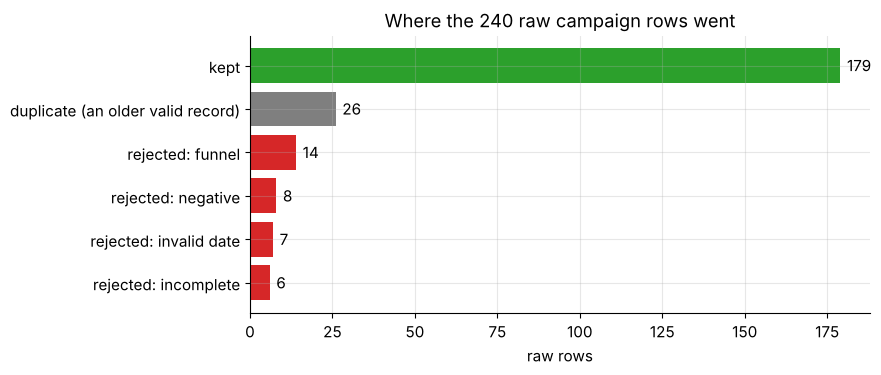

In [92]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = ["kept", "duplicate (an older valid record)", "rejected: funnel", "rejected: negative",
         "rejected: invalid date", "rejected: incomplete"]
values = balance.set_index("fate").rows.reindex(order).fillna(0)
colors = ["tab:green", "tab:gray"] + ["tab:red"] * 4
ax.barh(order[::-1], values.values[::-1], color=colors[::-1])
for y, v in enumerate(values.values[::-1]):
    ax.text(v + 2, y, f"{int(v)}", va="center")
ax.set_xlabel("raw rows")
ax.set_title(f"Where the {n_raw} raw campaign rows went")
plt.show()

179 + 26 + 14 + 8 + 7 + 6 = 240: every raw row is accounted for. Such an audit table is also the best answer when someone asks "why is campaign X missing from the model's training data?". Finally, a few tests on the clean table itself, including one that uses the planted answer key one last time:

In [93]:
clean_tests = {
    "unique campaigns_clean(campaign_id)":       unique("campaigns_clean", ["campaign_id"]),
    "not_null campaigns_clean.revenue":          not_null("campaigns_clean", "revenue"),
    "rule funnel holds":                          rule("campaigns_clean", RULES["3. funnel"]),
    "rule valid start_date":                      rule("campaigns_clean", RULES["5. valid date"]),
    "accepted_values brand":                      accepted_values("campaigns_clean", "brand",
                                                                  [name.upper() for _, name in BRANDS]),
}
display(run_suite(clean_tests))
print("all expected campaigns present:", set(q("SELECT campaign_id FROM campaigns_clean").campaign_id) == expected_ids)

,test,status,offending rows
0,unique campaigns_clean(campaign_id),PASS,0
1,not_null campaigns_clean.revenue,PASS,0
2,rule funnel holds,PASS,0
3,rule valid start_date,PASS,0
4,accepted_values brand,PASS,0


all expected campaigns present: True


### 9.4 Two engines as a test

Running the same query on two independent engines is a cheap extra test, the database version of asking a second person to check your arithmetic. Portable queries must agree, and a disagreement means either a dialect difference (date functions, `strftime`) or, more interestingly, a query whose answer is not determined by the data. Here are the main queries of this notebook once more:

In [94]:
cross_engine = {
    "naive channel report (Sec 5.1)":        NAIVE_REPORT,
    "correct channel report (Sec 5.4)":      CORRECT_REPORT,
    "reviews and NULLs (Sec 3.2)":           reviews_sql,
    "conditional aggregation (Sec 3.5)":     cond_sql,
    "emulated FULL JOIN (Sec 4.1)":          FULL_EMULATED + " ORDER BY 3 NULLS LAST, 1",   # NULL order differs by engine
    "running totals (Sec 7.5)":              running_sql,
    "BETWEEN up to April 1 (Sec 6.2)":       "SELECT COUNT(*) AS n FROM orders WHERE order_ts BETWEEN '2026-03-01' AND '2026-04-01'",
    "bare column GROUP BY (Sec 3.3)":        bare_sql,
}
rows = []
for name, sql in cross_engine.items():
    try:
        verdict = frame_diff(q(sql, db), q(sql, duck), ordered=True)
        rows.append({"query": name, "result": "agree" if verdict is None else "DISAGREE"})
    except Exception as err:
        rows.append({"query": name, "result": f"error in one engine: {type(err).__name__}"})
pd.DataFrame(rows)

,query,result
0,naive channel report (Sec 5.1),agree
1,correct channel report (Sec 5.4),agree
2,reviews and NULLs (Sec 3.2),agree
3,conditional aggregation (Sec 3.5),agree
4,emulated FULL JOIN (Sec 4.1),agree
5,running totals (Sec 7.5),agree
6,BETWEEN up to April 1 (Sec 6.2),DISAGREE
7,bare column GROUP BY (Sec 3.3),error in one engine: BinderException


The portable queries agree, including the naive report (both engines compute the same wrong numbers: a second engine does not catch a *logical* error). The two queries that do not agree are exactly the ones this notebook warned about: a `BETWEEN` whose meaning depends on how timestamps are compared, and a bare column whose value is not determined by the data, which DuckDB refuses to compute.

> **Key idea.** Turn every assumption into a test: *keys are unique* (grain), *references resolve* (joins), *rules hold* (cleaning), *totals reconcile* (aggregation), *rows balance* (pipelines). Tests are cheap, but silently wrong numbers in a model or a dashboard are not.

## 10. Exam-style questions

Twelve questions in the style of a written exam. Try each one on paper first. The answers explain why the right option is right **and** why each wrong option is wrong.

**Question 1 (grain).** A school database has a table `enrollments(student_id, course_id, term, grade)`. A student may retake a course in a later term, but takes a course at most once per term. Which set of columns is a key of the table?

- (A) `student_id`
- (B) `(student_id, course_id)`
- (C) `(student_id, course_id, term)`
- (D) `(course_id, term)`

<details>
<summary>Answer</summary>

**(C).** One row means "one student taking one course in one term", so those three columns identify a row. (A) A student has many enrollments. (B) A retake creates a second row with the same student and course. (D) Many students take the same course in the same term.
</details>

**Question 2 (`NULL` and aggregates).** A column `x` holds the values 4, `NULL`, 4, 9, `NULL`. What does `SELECT COUNT(*), COUNT(x), COUNT(DISTINCT x), AVG(x)` return?

- (A) 5, 3, 2, 5.67
- (B) 5, 5, 3, 3.4
- (C) 5, 3, 3, 5.67
- (D) 3, 3, 2, 3.4

<details>
<summary>Answer</summary>

**(A).** `COUNT(*)` counts rows (5), `COUNT(x)` counts non-`NULL` values (3), `COUNT(DISTINCT x)` counts different non-`NULL` values, 4 and 9 (2), and `AVG(x)` averages the known values, (4 + 4 + 9) / 3 = 17/3 ≈ 5.67. (B) counts `NULL`s as values and computes 17/5 = 3.4, i.e. treats `NULL` as 0. (C) counts `NULL` as a distinct value, which `COUNT(DISTINCT …)` never does. (D) `COUNT(*)` counts every row, including those with `NULL`s.
</details>

**Question 3 (fill in the blank).** Complete the query so that it lists the channels with at least 150 orders.

```sql
SELECT channel, COUNT(*) AS n_orders
FROM orders
GROUP BY channel
______ COUNT(*) >= 150;
```

- (A) `WHERE`
- (B) `HAVING`
- (C) `AND`
- (D) `FILTER`

<details>
<summary>Answer</summary>

**(B).** `HAVING` filters groups after `GROUP BY` and may use aggregates. (A) `WHERE` filters single rows before grouping, and it must appear before `GROUP BY` and cannot contain aggregates. (C) is not a syntax error, but it is still rejected: `GROUP BY channel AND COUNT(*) >= 150` reads as grouping by the single expression `channel AND (COUNT(*) >= 150)`, and both engines refuse aggregates inside `GROUP BY`. An expression after `GROUP BY` only changes *what* is grouped, and it never removes groups. (D) `FILTER (WHERE …)` attaches to an aggregate (`COUNT(*) FILTER (WHERE …)`) and restricts which rows the aggregate counts, and it does not remove groups.
</details>

**Question 4 (fan-out).** Table `orders` has two rows: order 1 with total \$30 and one line, order 2 with total \$50 and three lines. What does this query return?

```sql
SELECT AVG(o.order_total)
FROM orders AS o JOIN order_items AS i ON i.order_id = o.order_id;
```

- (A) \$40
- (B) \$45
- (C) \$20
- (D) \$80

<details>
<summary>Answer</summary>

**(B).** The join has four rows with totals 30, 50, 50, 50, so the average is 180 / 4 = 45. The formula of Section 5.3 agrees: $\bar T = 40$, $\bar n = 2$, $\operatorname{Cov}(n, T) = \frac{30 \cdot 1 + 50 \cdot 3}{2} - 2 \cdot 40 = 10$, and $40 + 10/2 = 45$. (A) is the true average order value, which the join does not compute. (C) divides the true revenue (80) by the number of joined rows (4). (D) is the true total revenue, not an average.
</details>

**Question 5 (`LEFT JOIN` and `WHERE`).** What does this query return?

```sql
SELECT c.customer_id, COUNT(o.order_id) AS n
FROM customers AS c
LEFT JOIN orders AS o ON o.customer_id = c.customer_id
WHERE o.channel = 'app'
GROUP BY c.customer_id;
```

- (A) Every customer, and those without app orders have `n = 0`.
- (B) Only the customers with at least one app order.
- (C) An error: `WHERE` cannot refer to the right table of a `LEFT JOIN`.
- (D) The customers without any order (with `n = 0`) and the customers with app orders.

<details>
<summary>Answer</summary>

**(B).** For a customer without orders, `o.channel` is `NULL`, the condition is unknown and the row is dropped, and for a customer with only web orders, every joined row fails the condition. Only customers with an app order survive, so the `LEFT JOIN` behaves like an inner join. (A) describes the query with `AND o.channel = 'app'` moved into the `ON` clause. (C) There is no such rule. The query is valid, just not what was intended. (D) Customers without orders are dropped too, because their `NULL` channel does not satisfy the condition.
</details>

**Question 6 (anti-join).** `SELECT COUNT(*) FROM products WHERE product_id NOT IN (SELECT product_id FROM returns)` returns 0, although many products were never returned. What is the most likely cause?

- (A) The column `returns.product_id` contains at least one `NULL`.
- (B) `NOT IN` only works with a list of constants, not with a subquery.
- (C) `products.product_id` contains duplicates.
- (D) `COUNT(*)` skips rows that contain a `NULL`.

<details>
<summary>Answer</summary>

**(A).** `x NOT IN (…, NULL)` expands to `… AND x <> NULL`, which is never true, so no row passes. Use `NOT EXISTS` or exclude `NULL`s inside the subquery. (B) `NOT IN` accepts subqueries. (C) Duplicate products could inflate a count, but cannot make it zero. (D) `COUNT(*)` counts all rows, and only `COUNT(column)` skips `NULL`s.
</details>

**Question 7 (fill in the blank).** Timestamps in `events` have microsecond precision. Complete the condition so that it selects exactly the events of July 2026.

```sql
WHERE event_ts >= '2026-07-01' AND event_ts ____ '2026-08-01'
```

- (A) `<=`
- (B) `<`
- (C) `BETWEEN`
- (D) `>`

<details>
<summary>Answer</summary>

**(B).** The half-open interval $[$July 1, August 1$)$ contains every instant of July, whatever the precision, and nothing else. (A) also includes events at exactly midnight on August 1 (in a timestamp-typed engine), which then belong to two months. (C) `BETWEEN` needs the form `x BETWEEN a AND b`, so the line would be a syntax error, and `BETWEEN` includes its upper end anyway. (D) Together with the first condition it selects the events after August 1, none of which happened in July.
</details>

**Question 8 (ranking).** Scores 90, 85, 85, 70 are ranked in descending order. What are `RANK()` and `DENSE_RANK()` of the row with score 70?

- (A) 4 and 3
- (B) 3 and 3
- (C) 4 and 4
- (D) 3 and 4

<details>
<summary>Answer</summary>

**(A).** `RANK` gives both 85s rank 2 and skips 3, so 70 is fourth, and `DENSE_RANK` gives both 85s rank 2 and continues with 3. (B) would be `DENSE_RANK` twice. (C) would be `RANK` (or `ROW_NUMBER`) twice. (D) swaps the two functions.
</details>

**Question 9 (fill in the blank).** `user_profiles(event_id, user_id, updated_at, email)` stores several versions of each user's profile. `event_id` is unique and `updated_at` can tie. Choose the blank so that the query returns exactly one, reproducible, latest row per user.

```sql
SELECT * FROM (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY user_id
                                 ORDER BY updated_at DESC, ______) AS rn
    FROM user_profiles
) AS t
WHERE rn = 1;
```

- (A) `user_id`
- (B) `event_id DESC`
- (C) `email`
- (D) `RANDOM()`

<details>
<summary>Answer</summary>

**(B).** `event_id` is unique, so `(updated_at, event_id)` is a total order inside each user's partition: no ties remain, and the latest version wins (the larger id among versions with the same timestamp). (A) `user_id` is constant within the partition, so it breaks no tie. (C) Two versions can have the same e-mail (for example when another field changed), so ties can remain. (D) Makes the choice random by design: the opposite of reproducible.
</details>

**Question 10 (cleaning order).** Campaign K7 has two raw records: the older one is valid, the newer one has a negative spend. Pipeline P1 first keeps the newest record per campaign, then drops rows with negative values. Pipeline P2 first drops rows with negative values, then keeps the newest record per campaign. What happens to K7?

- (A) Both pipelines keep the older, valid record.
- (B) P1 loses K7 completely, and P2 keeps the older, valid record.
- (C) P1 keeps the newer record, and P2 loses K7.
- (D) Both pipelines lose K7.

<details>
<summary>Answer</summary>

**(B).** P1 deduplicates first and picks the newer (invalid) record, but the filter then removes it, and nothing is left for K7. P2 removes the invalid record first, so the deduplication chooses among valid records only. Row filters commute with each other, but not with deduplication. (A) ignores that P1 never sees the older record after deduplication. (C) P1 cannot keep a record with a negative spend, since its filter runs last. (D) P2 keeps the valid record.
</details>

**Question 11 (a wrong fix).** Three orders with totals \$10, \$10 and \$20 each have two lines. An analyst joins `orders` to `order_items` and computes `SUM(DISTINCT o.order_total)`. What is the result?

- (A) \$40
- (B) \$30
- (C) \$80
- (D) \$60

<details>
<summary>Answer</summary>

**(B).** `DISTINCT` removes repeated **values**, so the sum is 10 + 20 = 30: the second \$10 order is lost. (A) is the true revenue, which you get by summing at the order grain. (C) is the plain `SUM` after the join (every order counted twice). (D) is 2 × (10 + 20), the sum of the distinct values doubled for the two lines of each order, and no common query computes it.
</details>

**Question 12 (pandas).** `orders.merge(items, on="order_id", validate="one_to_one")` raises a `MergeError`. What does that tell you?

- (A) Some `order_id` appears more than once on at least one side, so a plain merge would multiply rows.
- (B) Some orders have no items.
- (C) The two `order_id` columns have different data types.
- (D) pandas cannot validate merges on integer keys.

<details>
<summary>Answer</summary>

**(A).** `validate="one_to_one"` asserts that the merge keys are unique on both sides, and `items` repeats `order_id` once per line. Aggregate `items` per order first, or declare `"one_to_many"` if a line-grain result is what you want. (B) Keys without a partner do not violate the relationship, but `indicator=True` reveals them. (C) Incompatible key types raise a different error (or silently fail to match), not a validation error. (D) `validate=` works with keys of any type.
</details>

## 11. Summary and going further

### 11.1 Key takeaways

| topic | the rule to remember |
|---|---|
| grain | Say "one row per ___" for every input, every CTE and the result. Test it: rows = distinct key values, no `NULL` keys. |
| `NULL` | Comparisons with `NULL` are *unknown*, and `WHERE` keeps only *true*. Use `IS NULL`, `COALESCE`, `IS DISTINCT FROM`. |
| logical order | `FROM → WHERE → GROUP BY → HAVING → SELECT (windows) → DISTINCT → ORDER BY → LIMIT`. Aggregates go in `HAVING`, window filters go outside a CTE. |
| counting | `COUNT(*)` rows, `COUNT(col)` non-`NULL` values, `COUNT(DISTINCT col)` different values. One unit of the denominator must be the unit you are averaging over. |
| joins | $\lvert R \bowtie S \rvert = \sum_v a_v b_v$. Joining many → one keeps the grain, and joining one → many multiplies the "one" side. |
| `LEFT JOIN` | Conditions on the right table go in `ON`. Count a right-hand column, not `*`. |
| anti-join | `NOT EXISTS` or `LEFT JOIN … IS NULL`. Never `NOT IN` over a column that may contain `NULL`. |
| fan-out | Aggregate each table to the result's grain in a CTE **before** joining, and check that the join keeps the row count. `SUM(DISTINCT)` is not a fix. |
| bias of the naive average | $\text{naive AVG} = \bar T + \operatorname{Cov}(n, T) / \bar n$: too high whenever bigger orders have more lines. |
| time windows | Half-open: `ts >= start AND ts < next_start`. No `BETWEEN`, no `23:59:59`. Normalize timestamp formats and time zones at load time. |
| window functions | `ROW_NUMBER` never ties, `RANK` skips after ties, `DENSE_RANK` does not, and give running totals an explicit `ROWS` frame. |
| determinism | Any "pick one row" (`ROW_NUMBER() = 1`, `LIMIT`, `drop_duplicates`) needs an `ORDER BY` ending in a unique column. |
| cleaning order | Normalize → validate with row filters (any order, written as "keep where valid") → deduplicate with `ROW_NUMBER`. |
| bare columns | `SELECT * … GROUP BY id` picks arbitrary rows (SQLite, and MySQL without `ONLY_FULL_GROUP_BY`) and is rejected by DuckDB and PostgreSQL. Never use it to deduplicate. |
| testing | Unique, not-null, relationship, accepted-values and rule tests. Reconcile report totals and pipeline row counts. |

### 11.2 Engine differences met in this notebook

| behavior | SQLite | DuckDB | PostgreSQL | MySQL |
|---|---|---|---|---|
| bare columns in `GROUP BY` | allowed, arbitrary row | error (`ANY_VALUE` offered) | error | error with `ONLY_FULL_GROUP_BY` (default), arbitrary values without it |
| integer `/` integer | integer division | fractional result (`//` for integer division) | integer division | fractional result (`DIV` for integer division) |
| `NULL` position in `ORDER BY … ASC` | first | last | last | first |
| `LIKE` and letter case | case-insensitive (ASCII) | case-sensitive (`ILIKE` exists) | case-sensitive (`ILIKE` exists) | depends on the collation (usually insensitive) |
| default `TRIM` removes | spaces only | spaces and some Unicode spaces | spaces only | spaces only |
| timestamps | no type (usually ISO-8601 text, compared as strings!) | `TIMESTAMP` type | `timestamp` type | `DATETIME` type |
| `RIGHT` / `FULL OUTER JOIN` | since 3.39 | yes | yes | `RIGHT` yes, `FULL` no |
| filter on a window function | subquery or CTE | `QUALIFY` | subquery or CTE | subquery or CTE |

### 11.3 Cheat sheet

```sql
-- Is K a key of T?  (rows = distinct keys, and no NULL key)
SELECT COUNT(*), COUNT(DISTINCT k) FROM t;                    -- for several columns: count DISTINCT rows in a subquery

-- Children per parent, zeros included: condition on the right table goes in ON
SELECT p.id, COUNT(c.id) AS n_children
FROM parent AS p LEFT JOIN child AS c ON c.parent_id = p.id AND c.ts >= :start AND c.ts < :end
GROUP BY p.id;

-- Anti-join (NULL-safe)
SELECT * FROM a WHERE NOT EXISTS (SELECT 1 FROM b WHERE b.a_id = a.id);

-- Report at order grain: pre-aggregate the finer table, then LEFT JOIN, then aggregate
WITH order_sizes AS (SELECT order_id, SUM(quantity) AS units FROM order_items GROUP BY order_id)
SELECT o.channel, COUNT(*) AS n_orders, SUM(o.order_total) AS revenue, AVG(o.order_total) AS aov,
       COALESCE(SUM(s.units), 0) AS units
FROM orders AS o LEFT JOIN order_sizes AS s ON s.order_id = o.order_id
WHERE o.order_ts >= '2026-03-01' AND o.order_ts < '2026-04-01'
GROUP BY o.channel
HAVING COUNT(*) >= 150;

-- Latest valid record per key, deterministic
WITH valid AS (SELECT * FROM raw WHERE <rule 1> AND <rule 2> AND ...),
ranked AS (SELECT *, ROW_NUMBER() OVER (PARTITION BY k ORDER BY loaded_at DESC, row_id DESC) AS rn
           FROM valid)
SELECT * FROM ranked WHERE rn = 1;

-- Running total with an explicit frame and a total order
SUM(x) OVER (PARTITION BY g ORDER BY ts, id ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)

-- A data test: returns offending rows, passes when empty (unknown counts as failure)
SELECT * FROM t WHERE CASE WHEN <rule> THEN 0 ELSE 1 END = 1;
```

And in pandas: `df.merge(other, on=key, validate="many_to_one", indicator=True)`, `df.sort_values([key, time, unique_id]).drop_duplicates(key, keep="last")`, and write filters as "keep where valid" masks.

### 11.4 Going further

- SQLite documentation: [the `SELECT` statement](https://www.sqlite.org/lang_select.html) (including its paragraph on bare columns in aggregate queries), [date and time functions](https://www.sqlite.org/lang_datefunc.html) and [window functions](https://www.sqlite.org/windowfunctions.html).
- [DuckDB documentation](https://duckdb.org/docs/): see the pages on `QUALIFY`, `any_value`/`arg_max`, and timestamp functions.
- PostgreSQL tutorial: [window functions](https://www.postgresql.org/docs/current/tutorial-window.html), a clear first explanation of `OVER (PARTITION BY … ORDER BY …)`.
- MySQL reference manual: [MySQL handling of GROUP BY](https://dev.mysql.com/doc/refman/8.0/en/group-by-handling.html), the official description of `ONLY_FULL_GROUP_BY` and nondeterministic values.
- pandas: [`DataFrame.merge`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html) (the `validate=` and `indicator=` arguments) and [`DataFrame.drop_duplicates`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html).
- [Modern SQL](https://modern-sql.com/) by Markus Winand: standard features (window functions, `FILTER`, `IS DISTINCT FROM`) and which engines support them. His [Use The Index, Luke](https://use-the-index-luke.com/) explains why conditions on raw columns (like half-open ranges) are faster than functions of columns.
- [dbt data tests](https://docs.getdbt.com/docs/build/data-tests): the "a test is a query returning failing rows" idea, used in production pipelines.
- Ralph Kimball and Margy Ross, *The Data Warehouse Toolkit* (Wiley): the classic text on declaring the grain of fact tables and designing tables around it.

Next in the series, the last two notebooks move from tables to documents: extracting answers and tables from scanned pages, where many of the same habits (keys, grain, validation rules, reconciliation) apply again.